# Plot regional shifts in trait space


In [9]:
.libPaths(c("/net/home/swolf/R/x86_64-pc-linux-gnu-library/4.4", .libPaths()))

## Load Data

### Shift stats per region

In [10]:
#combined_results_gbif <- read.csv("~/Func_Neo_Phytes/Results/quantification_shifts_regions_Olsen_s1_5000_GBIF_wcvp.csv") 
#combined_results_gbif <- read.csv("~/Func_Neo_Phytes/Results/quantification_shifts_regions_Olsen_GBIF_wcvp_CS_log10.csv") ## PREPRINT VERSION
#combined_results_gbif <- read.csv("~/Func_Neo_Phytes/Results/quantification_shifts_regions_Olsen_GBIF_wcvp_CS_log10_notrim_LCweighted.csv") 
combined_results_gbif <- read.csv("~/Func_Neo_Phytes/Results/quantification_shifts_regions_Olsen_GBIF_wcvp_CS_log10_notrim_misstree.csv") 


combined_results_gbif

region,biome_number,biome_name,realm_abbrev,realm_name,cliffs_delta_PC1,cliffs_delta_PC2,cliffs_delta_PC3,cliffs_delta_PC4,cliffs_delta_PC5,effect_size_PC1,effect_size_PC2,effect_size_PC3,effect_size_PC4,effect_size_PC5,significance_PC1,significance_PC2,significance_PC3,significance_PC4,significance_PC5
<chr>,<int>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>
1_IM,1,Tropical & Subtropical Moist Broadleaf Forests,IM,Indomalaya,-0.21864132,0.12808926,-0.249233058,-0.091771901,0.01741818,small,small,small,negligible,negligible,***,**,***,,
1_NT,1,Tropical & Subtropical Moist Broadleaf Forests,NT,Neotropical,-0.02152819,0.12333182,-0.132060107,-0.018033711,-0.04461914,negligible,small,small,negligible,negligible,,**,***,,
2_AA,2,Tropical & Subtropical Dry Broadleaf Forests,AA,Australasia,0.30578512,0.05785124,-0.603305785,-0.917355372,0.07438017,medium,negligible,large,large,negligible,,,,**,
2_IM,2,Tropical & Subtropical Dry Broadleaf Forests,IM,Indomalaya,-0.29565557,0.26586889,-0.293314256,-0.144901145,0.12369927,medium,small,medium,small,small,**,**,***,,
2_NT,2,Tropical & Subtropical Dry Broadleaf Forests,NT,Neotropical,-0.04012574,0.15125740,-0.215236686,0.039940828,-0.02995562,negligible,small,small,negligible,negligible,,,*,,
4_AA,4,Temperate Broadleaf & Mixed Forests,AA,Australasia,-0.11349577,0.37684636,-0.308925641,0.051887388,-0.06350208,small,medium,medium,negligible,negligible,,***,**,,
4_NA,4,Temperate Broadleaf & Mixed Forests,NA,Nearctic,-0.17533507,0.11952261,-0.437574316,-0.030005432,-0.22906299,small,small,large,negligible,small,**,,***,,***
4_NT,4,Temperate Broadleaf & Mixed Forests,NT,Neotropical,-0.13263920,0.31281123,-0.226799457,0.016749660,-0.03033047,small,medium,small,negligible,negligible,,*,,,
5_NA,5,Temperate Coniferous Forests,NA,Nearctic,-0.04793783,0.18751924,-0.306632810,-0.040666359,-0.07121422,negligible,small,medium,negligible,negligible,,**,***,,


In [11]:
dim(combined_results_gbif)

[1] 20 20

### Region polygons

In [12]:
# read the aggregated shapefile
library(sf)
wwf_aggregated <- st_read("~/iNaturalist/Data/WWF/wwf_terr_ecos_aggregated.shp")
print(wwf_aggregated)

Linking to GEOS 3.12.1, GDAL 3.8.4, PROJ 9.4.0; sf_use_s2() is TRUE



Reading layer `wwf_terr_ecos_aggregated' from data source 
  `/net/home/swolf/iNaturalist/Data/WWF/wwf_terr_ecos_aggregated.shp' 
  using driver `ESRI Shapefile'
Simple feature collection with 64 features and 1 field
Geometry type: MULTIPOLYGON
Dimension:     XY
Bounding box:  xmin: -180 ymin: -87.26008 xmax: 180 ymax: 83.62313
Geodetic CRS:  WGS 84


Simple feature collection with 64 features and 1 field
Geometry type: MULTIPOLYGON
Dimension:     XY
Bounding box:  xmin: -180 ymin: -87.26008 xmax: 180 ymax: 83.62313
Geodetic CRS:  WGS 84
First 10 features:
   bim_rlm                       geometry
1    10_AA MULTIPOLYGON (((171.4289 -4...
2    10_AT MULTIPOLYGON (((34.56465 1....
3    10_IM MULTIPOLYGON (((116.6342 6....
4    10_NT MULTIPOLYGON (((-76.14241 4...
5    10_PA MULTIPOLYGON (((64.75403 34...
6    11_AA MULTIPOLYGON (((179.1841 -4...
7    11_AN MULTIPOLYGON (((-66.89195 -...
8    11_NA MULTIPOLYGON (((-42.17305 6...
9    11_PA MULTIPOLYGON (((149.4331 68...
10   12_AA MULTIPOLYGON (((122.7533 -3...


### Grid-level PCA results

In [13]:
library(data.table) 
dtn = 10
setDTthreads(threads = dtn) #defines how many threads data.table is allowed to use

#PREPRINT VERSION# combined_data = fread("/net/scratch/swolf/GBIF/gbif_res3_try6_CS_wcvp_summary_stats_inkl_pca_mean_group_region_log10.csv")
#combined_data = fread("/net/scratch/swolf/GBIF/gbif_res3_try6_CS_wcvp_summary_stats_inkl_pca_mean_group_region_log10_notrim_LCweighted.csv")
combined_data = fread("/net/scratch/swolf/GBIF/gbif_res3_try6_CS_wcvp_summary_stats_inkl_pca_mean_group_region_log10_notrim_misstree.csv")


head(combined_data)


h3_res3,group,PC1,PC2,PC3,PC4,PC5,count,count_sp,mean_perc_na,⋯,X.X614,X.X351,X.X6,X.X95,X.X138,X.X1080,X.X78,X.X4,X.X47,region
<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<int>,<int>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>
83001afffffffff,all,-10.334354,1.3228614,-1.7255834,1.0414618,2.1589100,10,4,5.68,⋯,3.884,-0.020,-0.698,85.452,2.183,3.140,-0.547,0.3330000,0.152,11_PA
83001afffffffff,native,-10.334354,1.3228614,-1.7255834,1.0414618,2.1589100,10,4,5.68,⋯,3.884,-0.020,-0.698,85.452,2.183,3.140,-0.547,0.3330000,0.152,11_PA
83001cfffffffff,all,-10.005360,-0.2380058,0.2491376,2.9137390,0.9757523,1,1,16.22,⋯,3.810,0.001,-0.744,92.099,2.545,3.121,-0.563,0.3166111,0.175,
83001cfffffffff,native,-9.988809,-0.3014320,0.2822225,2.9136399,0.9666302,1,1,16.22,⋯,3.810,0.001,-0.744,92.099,2.545,3.121,-0.563,0.3291221,0.175,
83001efffffffff,all,-10.690103,-0.8713593,-0.9452468,-0.2685651,1.3119540,4,3,3.38,⋯,4.005,0.003,-0.699,88.269,2.311,3.671,-1.933,0.4090000,0.211,11_PA
83001efffffffff,native,-10.690103,-0.8713593,-0.9452468,-0.2685651,1.3119540,4,3,3.38,⋯,4.005,0.003,-0.699,88.269,2.311,3.671,-1.933,0.4090000,0.211,11_PA


## Calculate centroids and vectors for all regions

In [14]:
library(dplyr)
library(plotly)

# Calculate centroids and vectors for all regions
centroid_vectors <- data.frame()
region_cell_counts <- data.frame()

regions <- unique(wwf_aggregated$bim_rlm)

for (i in regions) {
    f <- wwf_aggregated[wwf_aggregated$bim_rlm == i, ]
    region_cells <- h3::polyfill(f, res = 3)
    region_cell_count <- length(region_cells)
    region_cell_counts <- rbind(region_cell_counts, data.frame(region = i, cell_count = region_cell_count))
    filtered_data <- combined_data %>%
        filter(h3_res3 %in% region_cells)
    
    # Skip regions with no data
    if (nrow(filtered_data) == 0) {
        message("No data for region ", i, ", skipping...")
        next
    }

    # Skip regions with insufficient data
    if (nrow(filtered_data %>% filter(group == "native")) < 5 || nrow(filtered_data %>% filter(group == "all")) < 10) {
        message("Insufficient data for region ", i, ", skipping...")
        next
    } 
    
    centroids <- filtered_data %>%
        group_by(group) %>%
        summarise(PC1 = mean(PC1, na.rm = TRUE),
                    PC2 = mean(PC2, na.rm = TRUE),
                    PC3 = mean(PC3, na.rm = TRUE),
                    PC4 = mean(PC4, na.rm = TRUE),
                    PC5 = mean(PC5, na.rm = TRUE),
                            .groups = "drop")
    
    centroid_native <- centroids %>% filter(group == "native")
    centroid_all <- centroids %>% filter(group == "all")
    
    centroid_vectors <- rbind(centroid_vectors, data.frame(
        region = i,
        PC1_native = centroid_native$PC1,
        PC2_native = centroid_native$PC2,
        PC3_native = centroid_native$PC3,
        PC4_native = centroid_native$PC4,
        PC5_native = centroid_native$PC5,
        PC1_all = centroid_all$PC1,
        PC2_all = centroid_all$PC2,
        PC3_all = centroid_all$PC3,
        PC4_all = centroid_all$PC4,
        PC5_all = centroid_all$PC5
    ))
}




Attaching package: ‘dplyr’


The following objects are masked from ‘package:data.table’:

    between, first, last


The following objects are masked from ‘package:stats’:

    filter, lag


The following objects are masked from ‘package:base’:

    intersect, setdiff, setequal, union


Loading required package: ggplot2


Attaching package: ‘plotly’


The following object is masked from ‘package:ggplot2’:

    last_plot


The following object is masked from ‘package:stats’:

    filter


The following object is masked from ‘package:graphics’:

    layout


Insufficient data for region 10_AA, skipping...

polygon has holes

polygon has holes

Insufficient data for region 10_IM, skipping...

polygon has holes

polygon has holes

polygon has holes

No data for region 11_AA, skipping...

No data for region 11_AN, skipping...



polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

Insufficient data for region 14_AA, skipping...

Insufficient data for region 14_AT, skipping...

polygon has holes

polygon has holes

polygon has holes

Insufficient data for region 14_IM, skipping...

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

Insufficient data for region 14_NT, skipping...

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygo

In [15]:
centroid_vectors <- centroid_vectors %>%
  left_join(region_cell_counts, by = "region")

head(centroid_vectors)


,region,PC1_native,PC2_native,PC3_native,PC4_native,PC5_native,PC1_all,PC2_all,PC3_all,PC4_all,PC5_all,cell_count
,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<int>
1,10_AT,1.2304311,-0.4769617,0.1683897,0.73616587,-0.08588682,1.2103375,0.04745162,-0.4307696,0.5346859,-0.20367389,64
2,10_NT,-1.4292682,-1.8063013,-1.5154678,0.27689312,-1.16230093,-1.6844860,-1.19831850,-1.6625461,0.2078980,-1.08217267,66
3,10_PA,-2.1340405,0.8680219,-0.5695198,0.08676916,0.80742030,-1.9943968,1.12712792,-0.7258832,0.1508858,0.70592475,262
4,11_NA,-5.9737184,-1.8677511,0.3883969,-1.36888625,-0.08765457,-5.9704942,-1.84247993,0.3534298,-1.3776152,-0.09997036,325
5,11_PA,-4.8112604,-0.3867052,0.4173383,-0.49411956,0.26280701,-4.7964291,-0.35717087,0.3948645,-0.4921841,0.25151809,322
6,12_AA,-0.3883279,-6.1053469,0.9486983,0.81251991,-0.31976542,-0.5460208,-5.47177321,0.7776032,0.8504800,-0.30285466,70


In [16]:
# Starting positions (native centroids)
starts <- centroid_vectors %>%
  select(PC1_native, PC2_native, PC3_native) %>%
  as.matrix()

# Shift vectors (all - native)
vectors <- centroid_vectors %>%
  transmute(
    dPC1 = PC1_all - PC1_native,
    dPC2 = PC2_all - PC2_native,
    dPC3 = PC3_all - PC3_native
  ) %>%
  as.matrix()

# Weights (based on cell counts)
#weights <- centroid_vectors$cell_count


In [17]:
ok <- complete.cases(starts, vectors)
starts <- starts[ok, ]
vectors <- vectors[ok, ]

In [18]:
# Get vector lengths per region (3D)
vector_lengths <- sqrt(vectors[,1]^2 + vectors[,2]^2 + vectors[,3]^2)
vector_lengths_df <- data.frame(
  region = centroid_vectors$region[ok],
  vector_length = vector_lengths
)
head(vector_lengths_df)

,region,vector_length
,<chr>,<dbl>
1,10_AT,0.79649533
2,10_NT,0.67558212
3,10_PA,0.33329541
4,11_NA,0.04326345
5,11_PA,0.03996641
6,12_AA,0.67494908


In [19]:
# save the vector lengths to a CSV file
write.csv(vector_lengths_df, "~/Func_Neo_Phytes/Results/biome_shift_vector_lengths.csv", row.names = FALSE)

### Corrlate vector length with perc. introduced

In [20]:
library(tidyr)

# ── Derive perc_introduced per cell from all vs native counts ────────────────
intro_share <- combined_data %>%
    filter(group %in% c("all", "native")) %>%
    select(h3_res3, group, count, count_sp, region) %>%
    pivot_wider(
        names_from  = group,
        values_from = c(count, count_sp)
    ) %>%
    mutate(
        # record-based: share of introduced occurrences
        perc_introduced    = (count_all - count_native)    / count_all    * 100,
        # species-based: share of introduced species
        perc_introduced_sp = (count_sp_all - count_sp_native) / count_sp_all * 100,
        # clip to [0, 100] in case of minor count mismatches
        across(starts_with("perc_introduced"), ~ pmax(0, pmin(100, .x)))
    )

# ── Then aggregate to regions ────────────────────────────────────────────────
regional_covars <- combined_data %>%
    filter(group == "all") %>%                       # mean_perc_na from the "all" group
    select(h3_res3, region, mean_perc_na) %>%
    left_join(intro_share %>% select(h3_res3, perc_introduced, perc_introduced_sp),
              by = "h3_res3") %>%
    group_by(region) %>%
    summarise(
        mean_perc_na            = mean(mean_perc_na,           na.rm = TRUE),
        mean_perc_introduced    = mean(perc_introduced,        na.rm = TRUE),
        mean_perc_introduced_sp = mean(perc_introduced_sp,     na.rm = TRUE),
        .groups = "drop"
    )

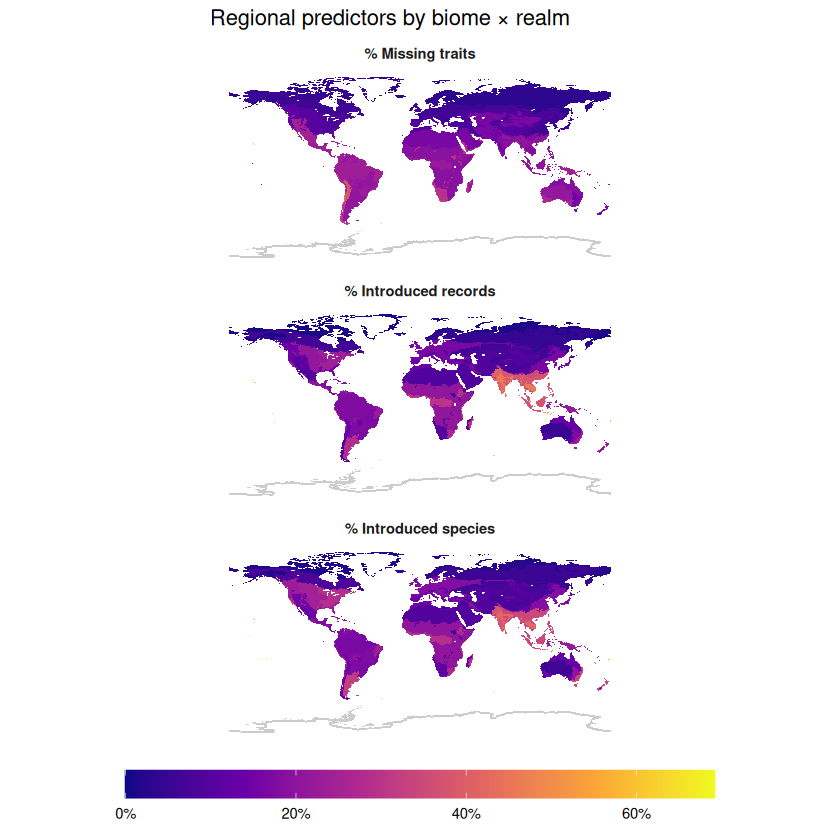

In [21]:
library(tidyr)

# ── Join all three covariates onto the spatial polygons ──────────────────────
map_data <- wwf_aggregated %>%
    left_join(regional_covars, by = c("bim_rlm" = "region")) %>%
    pivot_longer(
        cols      = c(mean_perc_na, mean_perc_introduced, mean_perc_introduced_sp),
        names_to  = "predictor",
        values_to = "value"
    ) %>%
    mutate(predictor = factor(predictor,
        levels = c("mean_perc_na", "mean_perc_introduced", "mean_perc_introduced_sp"),
        labels = c("% Missing traits", "% Introduced records", "% Introduced species")
    ))

# ── Global maps ──────────────────────────────────────────────────────────────
ggplot(map_data) +
    geom_sf(aes(fill = value), color = NA) +
    facet_wrap(~ predictor, ncol = 1) +
    scale_fill_viridis_c(
        option   = "plasma",
        na.value = "grey80",
        labels   = function(x) paste0(round(x), "%")
    ) +
    theme_minimal(base_size = 11) +
    theme(
        legend.position  = "bottom",
        legend.key.width = unit(2.5, "cm"),
        strip.text       = element_text(face = "bold"),
        panel.grid       = element_blank(),
        axis.text        = element_blank()
    ) +
    labs(title = "Regional predictors by biome × realm", fill = NULL)

In [22]:
# ── 1. Join vector lengths with all three covariates ─────────────────────────
regional_stats <- vector_lengths_df %>%
    left_join(regional_covars, by = "region") %>%
    filter(is.finite(vector_length))

# ── 2. Reshape to long ────────────────────────────────────────────────────────
regional_long <- regional_stats %>%
    pivot_longer(
        cols      = c(mean_perc_na, mean_perc_introduced, mean_perc_introduced_sp),
        names_to  = "predictor",
        values_to = "value"
    ) %>%
    mutate(predictor = factor(predictor,
        levels = c("mean_perc_na", "mean_perc_introduced", "mean_perc_introduced_sp"),
        labels = c("% Missing traits", "% Introduced records", "% Introduced species")
    ))

# ── 3. Plot ───────────────────────────────────────────────────────────────────
ggplot(regional_long, aes(x = value, y = vector_length)) +
    geom_point(alpha = 0.6, size = 2) +
    geom_smooth(method = "lm", se = TRUE, color = "firebrick") +
    facet_wrap(~ predictor, scales = "free_x", ncol = 3) +
    stat_cor(method = "pearson", label.x.npc = "left", label.y.npc = "top") +
    theme_minimal(base_size = 11) +
    theme(
        strip.text       = element_text(face = "bold"),
        panel.grid.minor = element_blank()
    ) +
    labs(
        x     = NULL,
        y     = "Regional vector length",
        title = "Trait shift magnitude vs. regional data properties"
    )

ERROR: Error in stat_cor(method = "pearson", label.x.npc = "left", label.y.npc = "top"): could not find function "stat_cor"


`geom_smooth()` using formula = 'y ~ x'


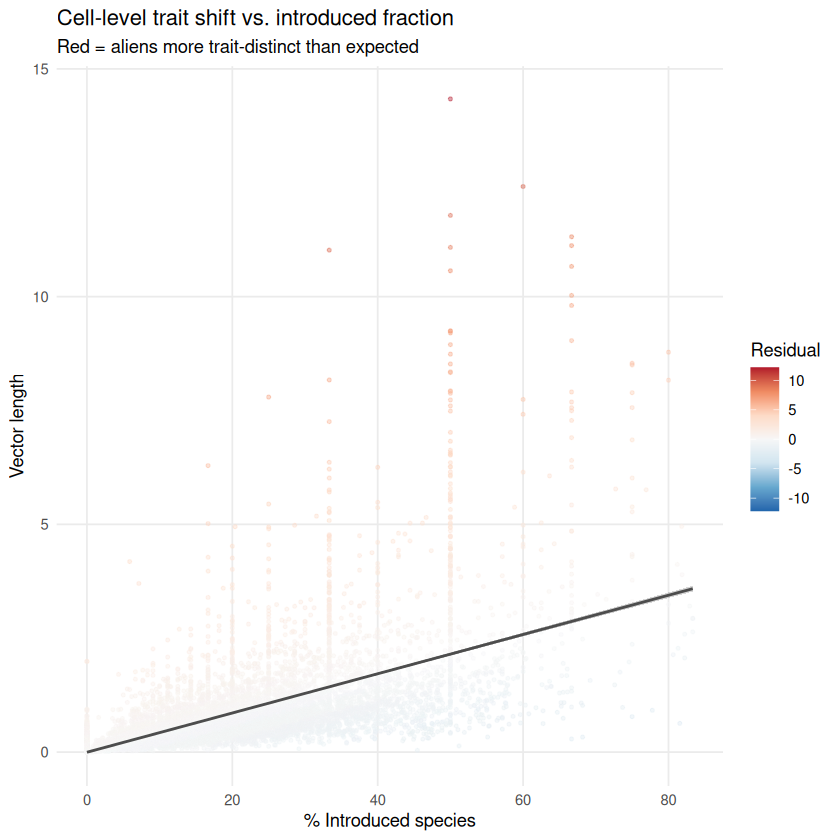

In [ ]:
# ── 1. Compute per-cell shift length and introduced share ─────────────────────
cell_level <- combined_data %>%
    filter(group %in% c("all", "native")) %>%
    select(h3_res3, group, PC1, PC2, PC3, count, count_sp, mean_perc_na, region) %>%
    pivot_wider(
        names_from  = group,
        values_from = c(PC1, PC2, PC3, count, count_sp, mean_perc_na)
    ) %>%
    mutate(
        # shift vector components (present - native)
        dPC1 = PC1_all - PC1_native,
        dPC2 = PC2_all - PC2_native,
        dPC3 = PC3_all - PC3_native,
        # shift length (||shift||)
        vector_length      = sqrt(dPC1^2 + dPC2^2 + dPC3^2),
        # introduced share
        perc_introduced_sp = pmax(0, (count_sp_all - count_sp_native) / count_sp_all * 100),
        perc_introduced    = pmax(0, (count_all    - count_native)    / count_all    * 100)
    ) %>%
    filter(is.finite(vector_length), is.finite(perc_introduced_sp),
           count_sp_all > 0)

# ── 2. Fit cell-level model and extract residuals ─────────────────────────────
mod_cell <- lm(vector_length ~ perc_introduced_sp, data = cell_level)

cell_level <- cell_level %>%
    mutate(residual = residuals(mod_cell))

# ── 3. Quick scatter to check ─────────────────────────────────────────────────
ggplot(cell_level, aes(x = perc_introduced_sp, y = vector_length)) +
    geom_point(aes(color = residual), alpha = 0.4, size = 0.8) +
    geom_smooth(method = "lm", se = TRUE, color = "grey30", linewidth = 0.8) +
    scale_color_distiller(
        palette = "RdBu",
        limits  = c(-max(abs(cell_level$residual), na.rm = TRUE),
                     max(abs(cell_level$residual), na.rm = TRUE)),
        name    = "Residual"
    ) +
    theme_minimal(base_size = 11) +
    theme(panel.grid.minor = element_blank()) +
    labs(
        x        = "% Introduced species",
        y        = "Vector length",
        title    = "Cell-level trait shift vs. introduced fraction",
        subtitle = "Red = aliens more trait-distinct than expected"
    )

In [65]:
cor.test(cell_level_filtered$perc_introduced, cell_level_filtered$vector_length)


	Pearson's product-moment correlation

data:  cell_level_filtered$perc_introduced and cell_level_filtered$vector_length
t = 68.568, df = 5385, p-value < 2.2e-16
alternative hypothesis: true correlation is not equal to 0
95 percent confidence interval:
 0.6682073 0.6967313
sample estimates:
      cor 
0.6827293 


`geom_smooth()` using formula = 'y ~ x'
Warning message:
“annotation$theme is not a valid theme.
Please use `theme()` to construct themes.”
`geom_smooth()` using formula = 'y ~ x'
Warning message:
“annotation$theme is not a valid theme.
Please use `theme()` to construct themes.”


pdf 
  2

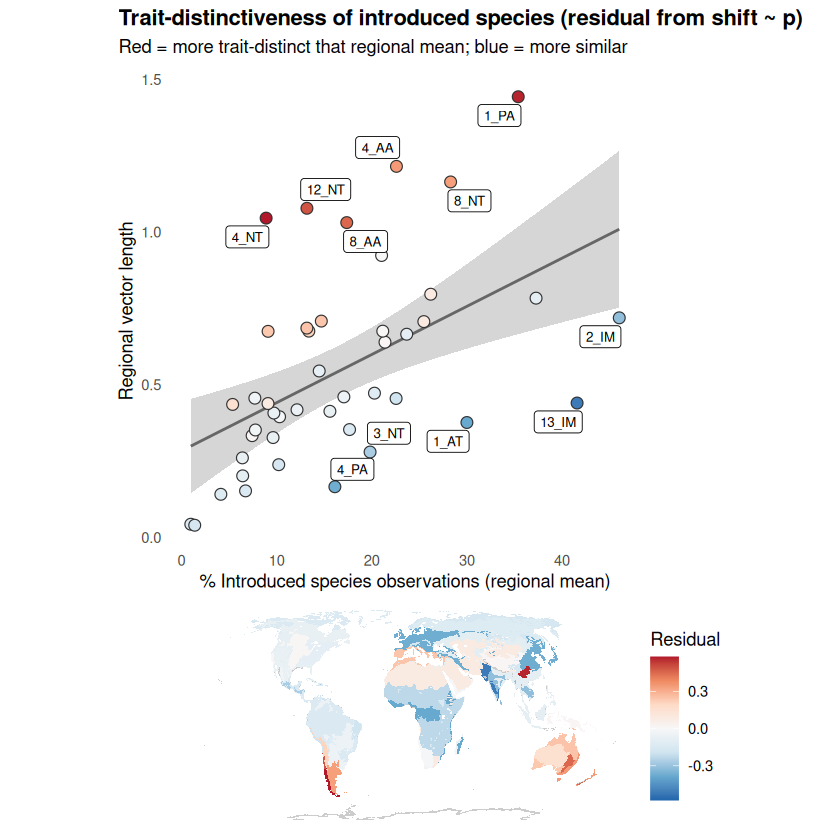

In [24]:
library(patchwork)
library(sf)

eqearth  <- "+proj=eqearth +datum=WGS84"
scale_lim <- max(abs(regional_stats$residual), na.rm = TRUE)

# ── Scatter ───────────────────────────────────────────────────────────────────
p_scatter <- ggplot(regional_stats, aes(x = mean_perc_introduced, y = vector_length)) +
    geom_smooth(method = "lm", se = TRUE, color = "grey40", linewidth = 0.8) +
    geom_point(aes(fill = residual), shape = 21, size = 3, color = "grey20") +
    scale_fill_distiller(
        palette = "RdBu",
        limits  = c(-scale_lim, scale_lim),
        oob     = scales::squish,
        name    = "Residual"
    ) +
    ggrepel::geom_label_repel(
        data = regional_stats %>%
            filter(abs(residual) > quantile(abs(residual), 0.75, na.rm = TRUE)),
        aes(label = region),
        size = 2.8, max.overlaps = 15
    ) +
    theme_minimal(base_size = 11) +
    theme(
        panel.grid  = element_blank(),
        legend.position = "none"
    ) +
    labs(
        x = "% Introduced species observations (regional mean)",
        y = "Regional vector length"
    )

p_map <- wwf_aggregated %>%
    left_join(regional_stats %>% select(region, residual),
              by = c("bim_rlm" = "region")) %>%
    st_transform(eqearth) %>%
    ggplot() +
    geom_sf(aes(fill = residual), color = NA) +
    scale_fill_distiller(
        palette  = "RdBu",
        limits   = c(-scale_lim, scale_lim),
        oob      = scales::squish,
        na.value = "grey80",
        name     = "Residual"
    ) +
    theme_void() +
    theme(
        legend.position  = "right"
    )

p_scatter / p_map +
    plot_annotation(
        title    = "Trait-distinctiveness of introduced species (residual from shift ~ p)",
        subtitle = "Red = more trait-distinct that regional mean; blue = more similar",
        theme    = theme(plot.title = element_text(face = "bold"))
    )


pdf("../../Results/Figures/trait_shift_vs_introduced.pdf", width = 10, height = 12)

p_scatter / p_map +
    plot_annotation(
        title    = "Trait-distinctiveness of introduced species (residual from shift ~ p)",
        subtitle = "Red = more trait-distinct that regional mean; blue = more similar",
        theme    = theme(plot.title = element_text(face = "bold"))
    )


dev.off()

## Calculate mean vector over all significant shifts

In [25]:
library(dplyr)

# Function to calculate angle (in degrees) between two 2D points
calc_angle <- function(x_start, y_start, x_end, y_end) {
  dx <- x_end - x_start
  dy <- y_end - y_start
  angle_rad <- atan2(dy, dx)
  angle_deg <- angle_rad * (180 / pi)
  return(angle_deg)
}

# Function to calculate Euclidean distance (vector length) between two 2D points
calc_length <- function(x_start, y_start, x_end, y_end) {
  sqrt((x_end - x_start)^2 + (y_end - y_start)^2)
}

# Calculate angles and lengths for each PC combination per region
vector_stats <- centroid_vectors %>%
  mutate(
    # PC1 vs PC2
    angle_PC1_PC2  = calc_angle(PC1_native, PC2_native, PC1_all, PC2_all),
    length_PC1_PC2 = calc_length(PC1_native, PC2_native, PC1_all, PC2_all),
    
    # PC1 vs PC3
    angle_PC1_PC3  = calc_angle(PC1_native, PC3_native, PC1_all, PC3_all),
    length_PC1_PC3 = calc_length(PC1_native, PC3_native, PC1_all, PC3_all),
    
    # PC3 vs PC2
    angle_PC3_PC2  = calc_angle(PC3_native, PC2_native, PC3_all, PC2_all),
    length_PC3_PC2 = calc_length(PC3_native, PC2_native, PC3_all, PC2_all)
  )

# --- Mean angle using circular statistics ---
# Simple arithmetic mean of angles is misleading near ±180°,
# so we average the unit vectors and recover the angle.
circular_mean_angle <- function(angles_deg) {
  angles_rad <- angles_deg * (pi / 180)
  mean_sin <- mean(sin(angles_rad), na.rm = TRUE)
  mean_cos <- mean(cos(angles_rad), na.rm = TRUE)
  mean_angle_rad <- atan2(mean_sin, mean_cos)
  mean_angle_deg <- mean_angle_rad * (180 / pi)
  return(mean_angle_deg)
}

# Summarise across all regions
summary_stats <- vector_stats %>%
  summarise(
    # Mean angles (circular)
    mean_angle_PC1_PC2  = circular_mean_angle(angle_PC1_PC2),
    mean_angle_PC1_PC3  = circular_mean_angle(angle_PC1_PC3),
    mean_angle_PC3_PC2  = circular_mean_angle(angle_PC3_PC2),
    
    # SD of angles (circular: resultant vector length ≈ concentration)
    sd_angle_PC1_PC2    = sd(angle_PC1_PC2,  na.rm = TRUE),
    sd_angle_PC1_PC3    = sd(angle_PC1_PC3,  na.rm = TRUE),
    sd_angle_PC3_PC2    = sd(angle_PC3_PC2,  na.rm = TRUE),
    
    # Mean vector lengths
    mean_length_PC1_PC2 = mean(length_PC1_PC2, na.rm = TRUE),
    mean_length_PC1_PC3 = mean(length_PC1_PC3, na.rm = TRUE),
    mean_length_PC3_PC2 = mean(length_PC3_PC2, na.rm = TRUE),
    
    # SD of lengths
    sd_length_PC1_PC2   = sd(length_PC1_PC2, na.rm = TRUE),
    sd_length_PC1_PC3   = sd(length_PC1_PC3, na.rm = TRUE),
    sd_length_PC3_PC2   = sd(length_PC3_PC2, na.rm = TRUE),
    
    n_regions = n()
  )

print(summary_stats)

# Optional: tidy long-format view
summary_long <- data.frame(
  PC_combination = c("PC1 vs PC2", "PC1 vs PC3", "PC3 vs PC2"),
  mean_angle_deg = c(summary_stats$mean_angle_PC1_PC2,
                     summary_stats$mean_angle_PC1_PC3,
                     summary_stats$mean_angle_PC3_PC2),
  sd_angle_deg   = c(summary_stats$sd_angle_PC1_PC2,
                     summary_stats$sd_angle_PC1_PC3,
                     summary_stats$sd_angle_PC3_PC2),
  mean_length    = c(summary_stats$mean_length_PC1_PC2,
                     summary_stats$mean_length_PC1_PC3,
                     summary_stats$mean_length_PC3_PC2),
  sd_length      = c(summary_stats$sd_length_PC1_PC2,
                     summary_stats$sd_length_PC1_PC3,
                     summary_stats$sd_length_PC3_PC2)
)

print(summary_long)

  mean_angle_PC1_PC2 mean_angle_PC1_PC3 mean_angle_PC3_PC2 sd_angle_PC1_PC2
1           97.06012          -103.3958           126.4612         56.96353
  sd_angle_PC1_PC3 sd_angle_PC3_PC2 mean_length_PC1_PC2 mean_length_PC1_PC3
1         72.01133         39.04637           0.4652966           0.3725197
  mean_length_PC3_PC2 sd_length_PC1_PC2 sd_length_PC1_PC3 sd_length_PC3_PC2
1            0.456384         0.3120937         0.2176433         0.3102644
  n_regions
1        45
  PC_combination mean_angle_deg sd_angle_deg mean_length sd_length
1     PC1 vs PC2       97.06012     56.96353   0.4652966 0.3120937
2     PC1 vs PC3     -103.39576     72.01133   0.3725197 0.2176433
3     PC3 vs PC2      126.46120     39.04637   0.4563840 0.3102644


## Plot in 2D trait space

In [26]:
library(ggplot2)
library(cowplot)
library(dplyr)
library(tibble)

# Master numeric group colors (1–13)
numeric_group_colors <- c(
  "1"  = "#4ae5ce",
  "2"  = "#bcbd22",
  "3"  = "#17becf",
  "4"  = "#33a02c",
  "5"  = "#fdbf6f",
  "6"  = "#e18e85",
  "7"  = "#cab2d6",
  "8"  = "#ff7f00",
  "9"  = "#a65628",
  "10" = "#37a2ee",
  "11" = "#f781bf",
  "12" = "#6a3d9a",
  "13" = "#d62728"
)

# Helper: extract numeric prefix from region code (e.g. "10_AT" -> "10")
get_region_color <- function(region_code) {
  num <- sub("_.*", "", region_code)
  color <- numeric_group_colors[num]
  ifelse(is.na(color), "#444444", color)
}

plot_centroid_vectors <- function(
  centroid_vectors,
  pc_x = 1,
  pc_y = 2,
  regions = NULL,
  show_labels = TRUE,
  title = NULL,
  output_file = NULL,
  width = 10,
  height = 7,
  dpi = 300
) {

  # Arrow gradient colors — defined inside so the function is self-contained
  arrow_colors <- c(
    "#fc8d62",
    "#b02f2c",
    "#2F86AC",
    "#2ed5c9",
    "#fc8d62"
  )

  # Column names
  x_native <- paste0("PC", pc_x, "_native")
  x_all    <- paste0("PC", pc_x, "_all")
  y_native <- paste0("PC", pc_y, "_native")
  y_all    <- paste0("PC", pc_y, "_all")

  # Filter regions
  if (!is.null(regions)) {
    centroid_vectors <- centroid_vectors %>%
      filter(region %in% regions)
  }

  # Calculate arrow angles and label colors
  centroid_vectors <- centroid_vectors %>%
    mutate(
      angle       = atan2(
        .data[[y_all]] - .data[[y_native]],
        .data[[x_all]] - .data[[x_native]]
      ),
      angle_deg   = (angle * 180 / pi) %% 360,
      label_color = get_region_color(region)
    )

  # Default title
  if (is.null(title)) {
    title <- paste0("Centroid Vectors: PC", pc_x, " vs PC", pc_y)
  }

  # Main plot
  p <- ggplot(centroid_vectors) +

    geom_hline(yintercept = 0, color = "lightgrey", linewidth = 0.3) +
    geom_vline(xintercept = 0, color = "lightgrey", linewidth = 0.3) +

    geom_segment(
      aes(
        x    = .data[[x_native]],
        y    = .data[[y_native]],
        xend = .data[[x_all]],
        yend = .data[[y_all]],
        color = angle_deg
      ),
      arrow     = arrow(length = unit(0.13, "inches")),
      linewidth = 1
    ) +

    scale_color_gradientn(
      colors = arrow_colors,
      limits = c(0, 360),
      breaks = c(0, 90, 180, 270, 360),
      labels = c("0°", "90°", "180°", "270°", "360°"),
      name   = "Arrow Angle"
    ) +

    coord_equal() +
    theme_minimal() +
    theme(panel.grid = element_blank()) +
    labs(
      title = title,
      x     = paste0("PC", pc_x),
      y     = paste0("PC", pc_y),
      color = "Angle (Degrees)"
    )

  # Labels with per-region colors (drawn outside aes to avoid scale conflict)
  if (show_labels) {
    for (r in unique(centroid_vectors$region)) {
      row <- centroid_vectors %>% filter(region == r)
      p <- p +
        geom_text(
          data        = row,
          aes(
            x     = .data[[x_all]],
            y     = .data[[y_all]],
            label = region
          ),
          color       = row$label_color,
          hjust       = -0.2,
          vjust       = -0.2,
          size        = 3,
          inherit.aes = FALSE
        )
    }
  }

  # Circular legend
  circle_data <- tibble(
    angle = seq(0, 2 * pi, length.out = 100),
    x     = cos(angle),
    y     = sin(angle),
    color = angle * 180 / pi
  )

  circular_legend <- ggplot(circle_data, aes(x = x, y = y, fill = color)) +
    geom_tile() +
    coord_fixed() +
    scale_fill_gradientn(
      colors = arrow_colors,
      limits = c(0, 360),
      breaks = c(0, 90, 180, 270, 360),
      labels = c("0°", "90°", "180°", "270°", "360°"),
      name   = "Angle"
    ) +
    theme_void() +
    theme(legend.position = "none")

  # Combine main plot and circular legend
  final_plot <- ggdraw() +
    draw_plot(p, 0, 0, 0.8, 1) +
    draw_plot(circular_legend, 0.8, 0.3, 0.2, 0.4)

  # Save if requested
  if (!is.null(output_file)) {
    ggsave(
      filename = output_file,
      plot     = final_plot,
      width    = width,
      height   = height,
      dpi      = dpi
    )
  }

  return(final_plot)
}


Attaching package: ‘cowplot’


The following object is masked from ‘package:patchwork’:

    align_plots




### PC1 and PC2

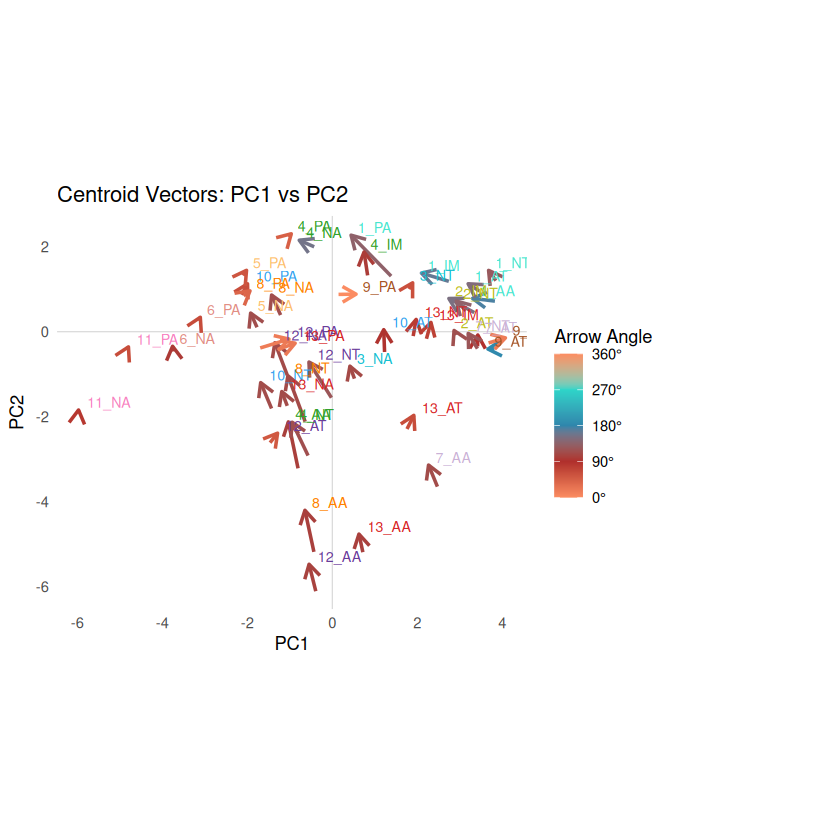

In [36]:
final_plot <- plot_centroid_vectors(
  centroid_vectors,
  pc_x = 1,
  pc_y = 2,
  show_labels = TRUE,
  regions = unique(combined_data$region)
)

print(final_plot)
ggsave(filename = "~/Func_Neo_Phytes/Results/Figures/centroid_vectors_angle_GBIF_wcvp_all_Olsen_CS_log10_notrim_missTree_nolabels.svg", plot = final_plot, width = 10, height = 7, dpi = 300)
ggsave(filename = "~/Func_Neo_Phytes/Results/Figures/centroid_vectors_angle_GBIF_wcvp_all_Olsen_CS_log10_notrim_missTree_nolabels.png", plot = final_plot, width = 10, height = 7, dpi = 300)


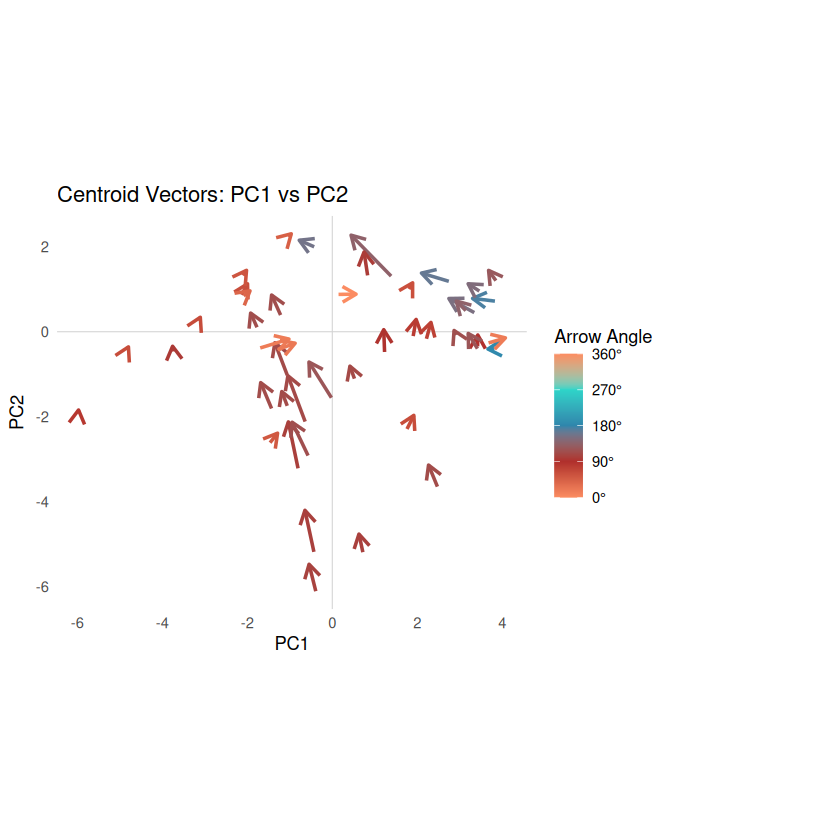

In [28]:
final_plot <- plot_centroid_vectors(
  centroid_vectors,
  pc_x = 1,
  pc_y = 2,
  show_labels = FALSE,
  regions = unique(combined_data$region)
)

print(final_plot)
ggsave(filename = "~/Func_Neo_Phytes/Results/Figures/centroid_vectors_angle_GBIF_wcvp_all_Olsen_CS_log10_notrim_missTree_nolabels.png", plot = final_plot, width = 10, height = 7, dpi = 300)


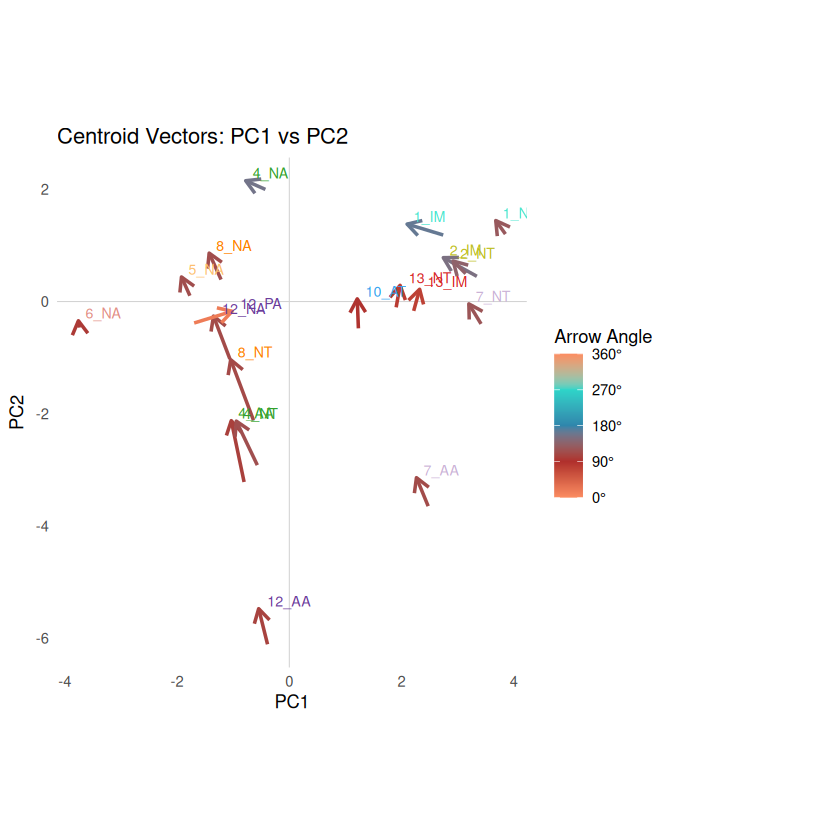

In [29]:
# only regions with significant shifts

final_plot <- plot_centroid_vectors(
  centroid_vectors,
  pc_x = 1,
  pc_y = 2,
  show_labels = TRUE,
  regions = unique(combined_results_gbif$region)
)
print(final_plot)
ggsave(filename = "~/Func_Neo_Phytes/Results/Figures/centroid_vectors_angle_GBIF_wcvp_all_significant_Olsen_CS_log10_notrim_missTree.svg", plot = final_plot, width = 10, height = 7, dpi = 300)
ggsave(filename = "~/Func_Neo_Phytes/Results/Figures/centroid_vectors_angle_GBIF_wcvp_all_significant_Olsen_CS_log10_notrim_missTree.png", plot = final_plot, width = 10, height = 7, dpi = 300)



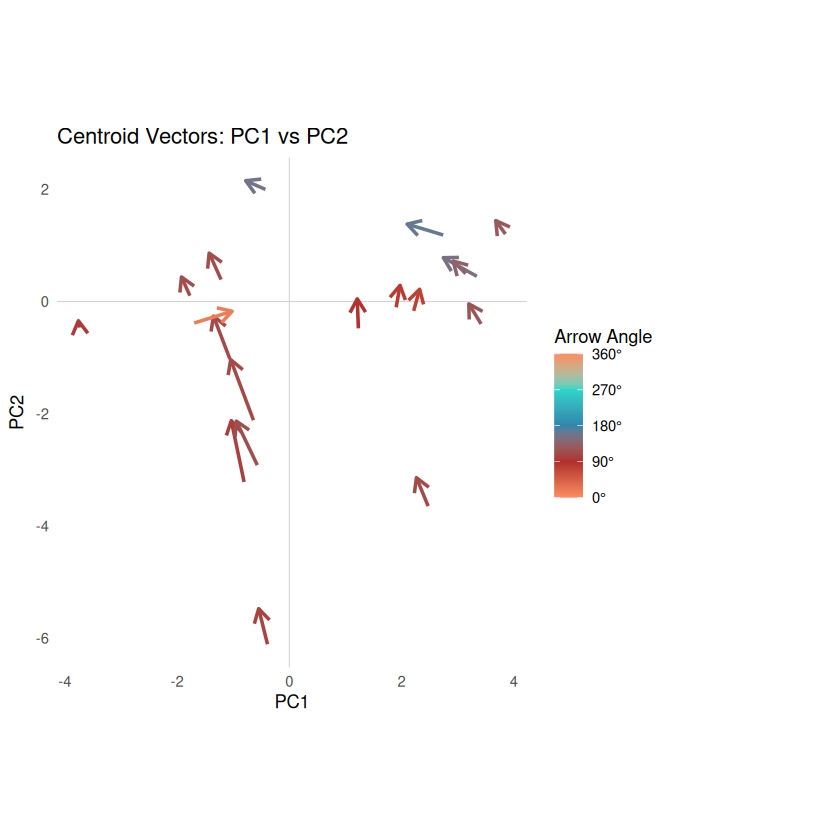

In [30]:
# only regions with significant shifts

final_plot <- plot_centroid_vectors(
  centroid_vectors,
  pc_x = 1,
  pc_y = 2,
  show_labels = FALSE,
  regions = unique(combined_results_gbif$region)
)
print(final_plot)
ggsave(filename = "~/Func_Neo_Phytes/Results/Figures/centroid_vectors_angle_GBIF_wcvp_all_significant_Olsen_CS_log10_notrim_missTree_nolabels.png", plot = final_plot, width = 10, height = 7, dpi = 300)


### PC 2 and 3

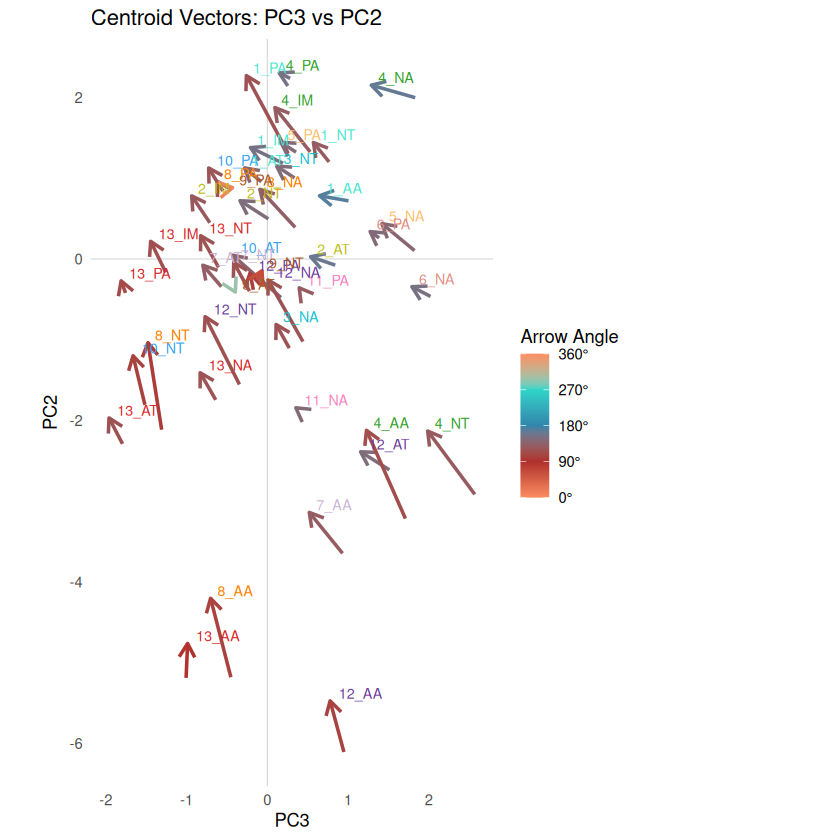

In [31]:
final_plot <- plot_centroid_vectors(
  centroid_vectors,
  pc_x = 3,
  pc_y = 2,
  show_labels = TRUE,
  regions = unique(combined_data$region)
)

print(final_plot)
ggsave(filename = "~/Func_Neo_Phytes/Results/Figures/centroid_vectors_angle_GBIF_wcvp_all_Olsen_CS_log10_notrim_missTree_PC23.svg", plot = final_plot, width = 10, height = 7, dpi = 300)
ggsave(filename = "~/Func_Neo_Phytes/Results/Figures/centroid_vectors_angle_GBIF_wcvp_all_Olsen_CS_log10_notrim_missTree_PC23.png", plot = final_plot, width = 10, height = 7, dpi = 300)


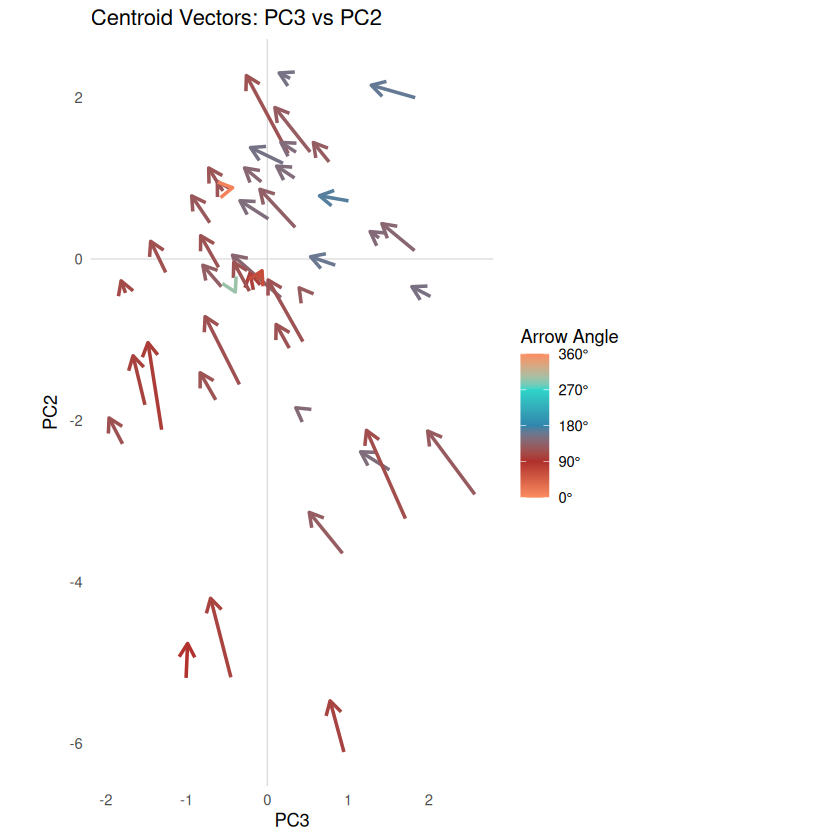

In [32]:
plot_centroid_vectors(
  centroid_vectors,
  pc_x = 3,
  pc_y = 2,
  show_labels = FALSE,
  regions = unique(combined_data$region)
)

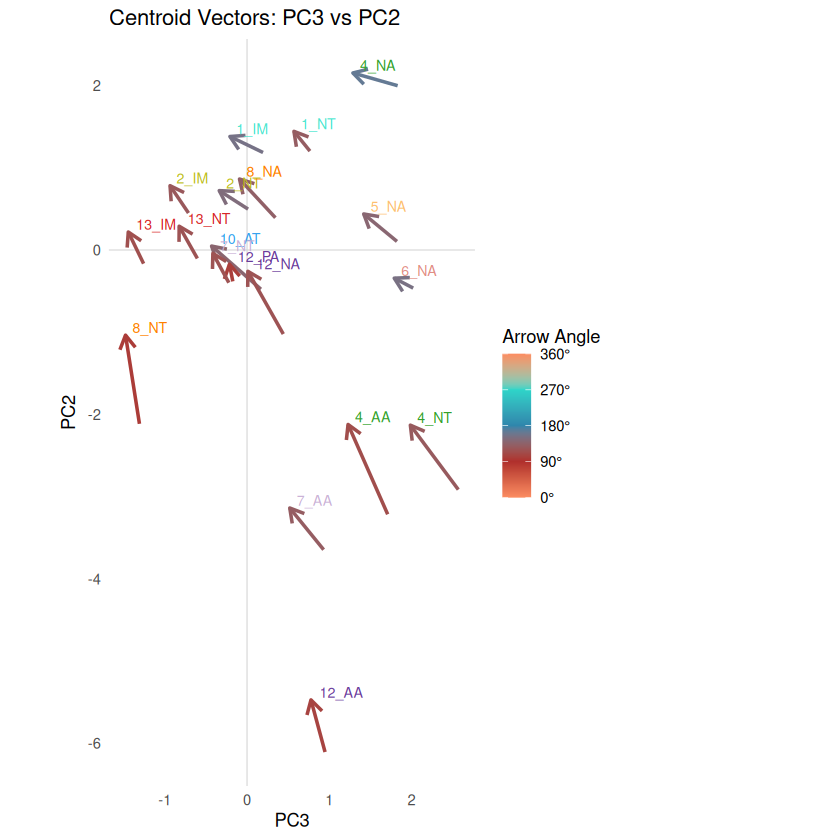

In [33]:
final_plot <- plot_centroid_vectors(
  centroid_vectors,
  pc_x = 3,
  pc_y = 2,
  show_labels = TRUE,
  regions = unique(combined_results_gbif$region)
)
print(final_plot)
ggsave(filename = "~/Func_Neo_Phytes/Results/Figures/centroid_vectors_angle_GBIF_wcvp_all_significant_Olsen_CS_log10_notrim_missTree_3_2.svg", plot = final_plot, width = 10, height = 7, dpi = 300)
ggsave(filename = "~/Func_Neo_Phytes/Results/Figures/centroid_vectors_angle_GBIF_wcvp_all_significant_Olsen_CS_log10_notrim_missTree_3_2.png", plot = final_plot, width = 10, height = 7, dpi = 300)


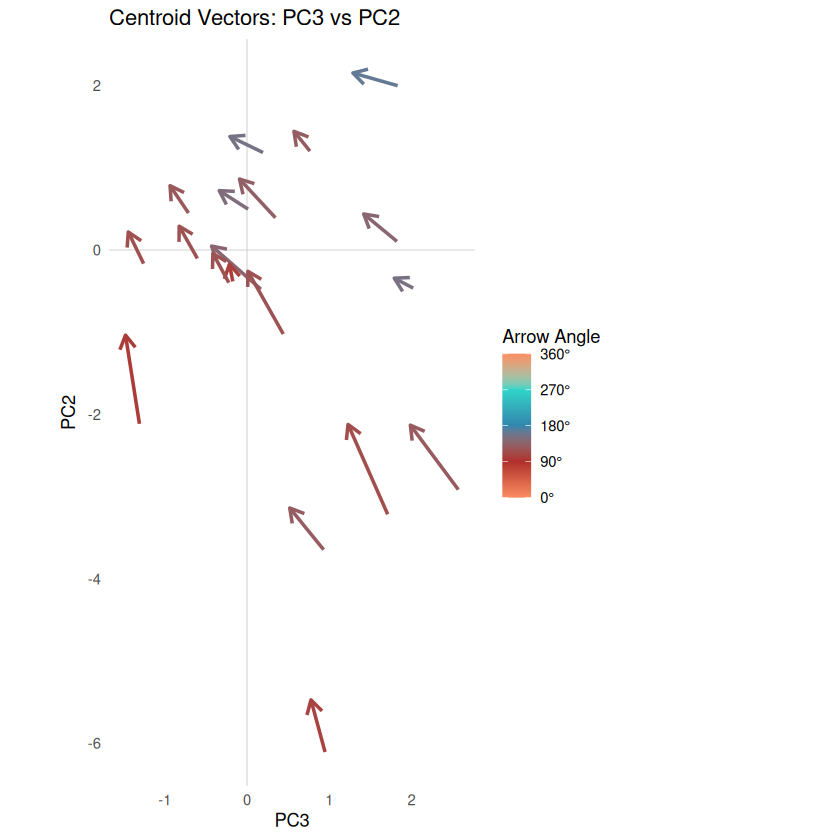

In [34]:
final_plot <- plot_centroid_vectors(
  centroid_vectors,
  pc_x = 3,
  pc_y = 2,
  show_labels = FALSE,
  regions = unique(combined_results_gbif$region)
)
print(final_plot)
ggsave(filename = "~/Func_Neo_Phytes/Results/Figures/centroid_vectors_angle_GBIF_wcvp_all_significant_Olsen_CS_log10_notrim_missTree_3_2_nolabels.png", plot = final_plot, width = 10, height = 7, dpi = 300)


### PC 1 and 3

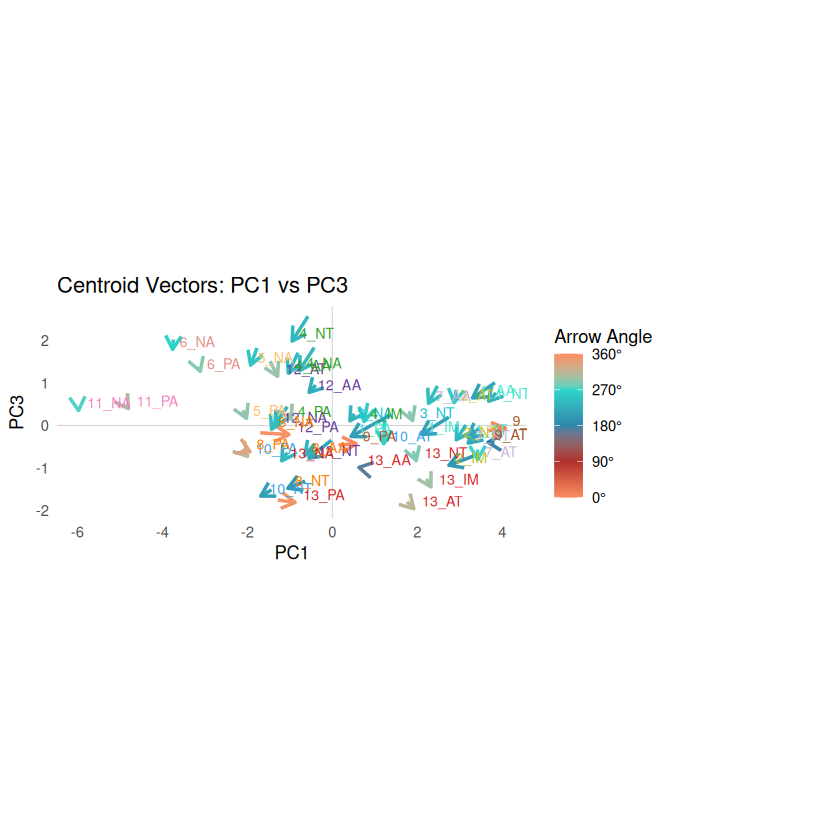

In [22]:
plot_centroid_vectors(
  centroid_vectors,
  pc_x = 1,
  pc_y = 3,
  show_labels = TRUE,
  regions = unique(combined_data$region)
)    

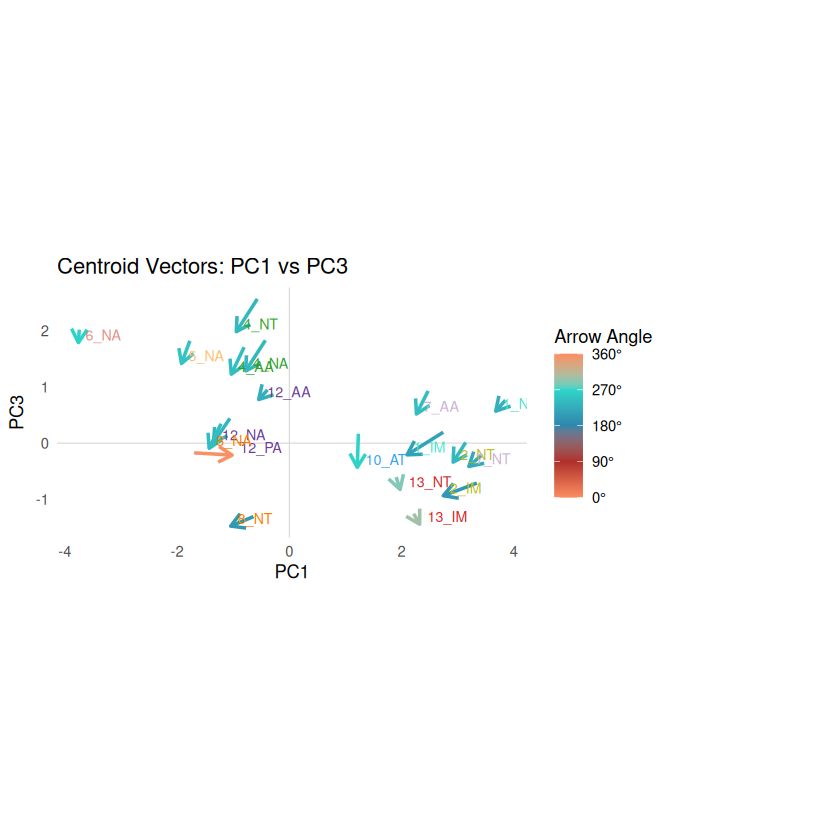

In [23]:
plot_centroid_vectors(
  centroid_vectors,
  pc_x = 1,
  pc_y = 3,
  show_labels = TRUE,
  regions = unique(combined_results_gbif$region)
)    

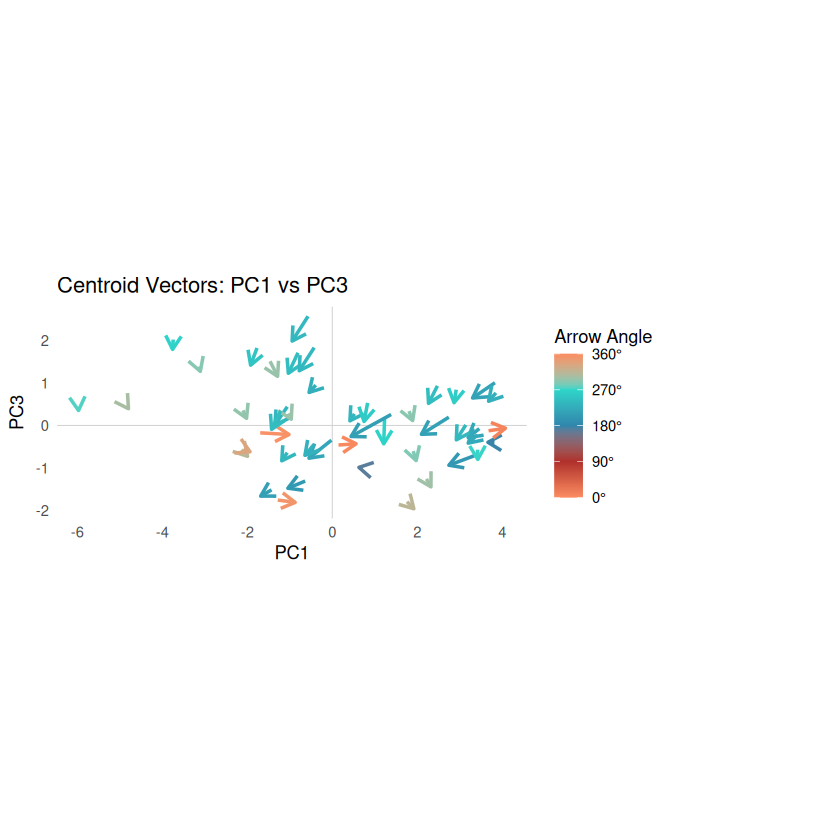

In [24]:
plot_centroid_vectors(
  centroid_vectors,
  pc_x = 1,
  pc_y = 3,
  show_labels = FALSE,
  regions = unique(combined_data$region)
)    

### PC 3 and 4

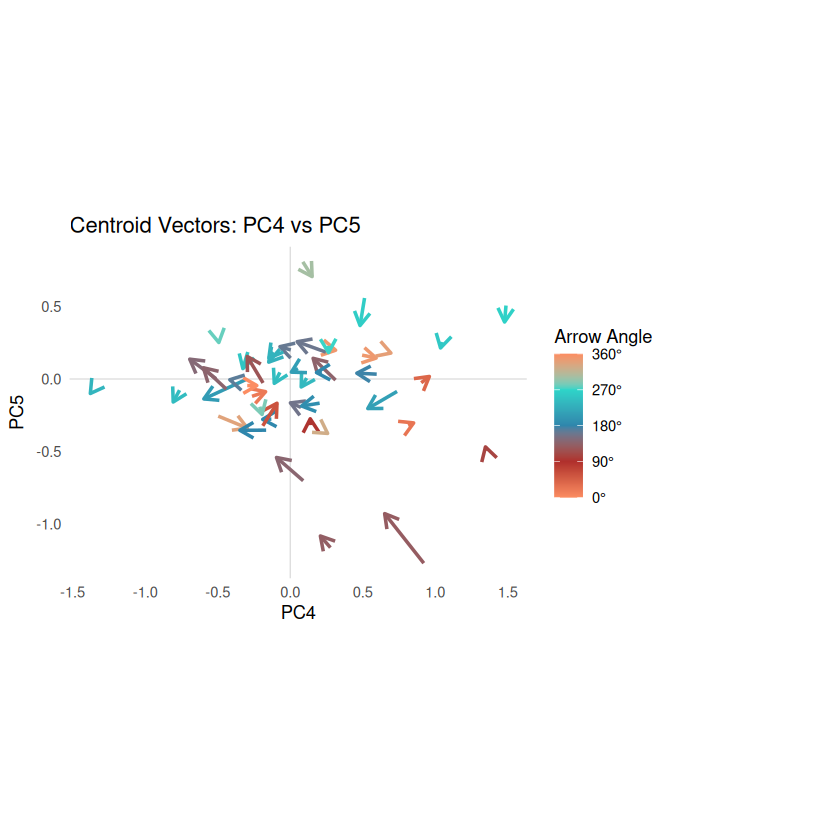

In [25]:
final_plot <- plot_centroid_vectors(
  centroid_vectors,
  pc_x = 4,
  pc_y = 5,
  show_labels = FALSE,
  regions = unique(combined_data$region)
)    

print(final_plot)
ggsave(filename = "~/Func_Neo_Phytes/Results/Figures/centroid_vectors_angle_GBIF_wcvp_all_significant_Olsen_CS_log10_notrim_missTree_4_5_nolabels.png", plot = final_plot, width = 10, height = 7, dpi = 300)


In [35]:
# Filter and print regions where significance_PC1, significance_PC2, or significance_PC3 is not empty
print(combined_results_gbif$region[combined_results_gbif$significance_PC1 != ""])

print(combined_results_gbif$region[combined_results_gbif$significance_PC2 != ""])

print(combined_results_gbif$region[combined_results_gbif$significance_PC3 != ""])


[1] "1_IM"  "2_IM"  "4_NA"  "12_PA"
 [1] "1_IM"  "1_NT"  "2_IM"  "4_AA"  "4_NT"  "5_NA"  "7_AA"  "7_NT"  "8_NA" 
[10] "8_NT"  "10_AT" "12_AA" "12_NA" "13_IM" "13_NT"
 [1] "1_IM"  "1_NT"  "2_IM"  "2_NT"  "4_AA"  "4_NA"  "5_NA"  "6_NA"  "7_AA" 
[10] "8_NA"  "10_AT"


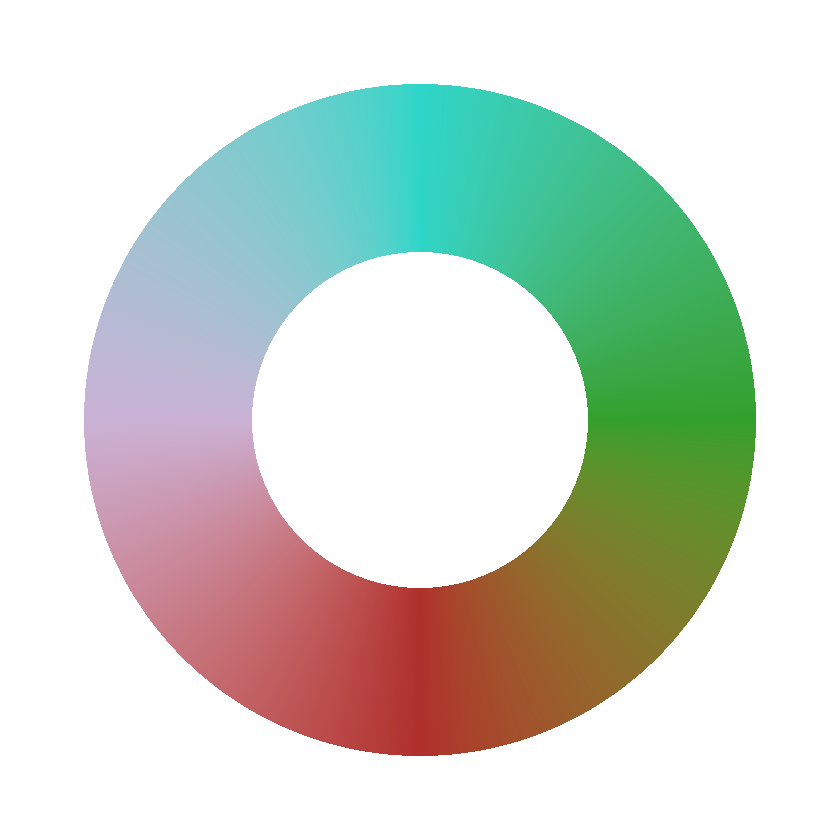

In [71]:
library(ggplot2)

# Create test data
data <- data.frame(
    category = paste0("Category_", 1:1000),
    count = 1:1000  # Counts from 1 to 500
)

# Compute percentages
data$fraction <- data$count / sum(data$count)

# Compute the cumulative percentages (top of each rectangle)
data$ymax <- cumsum(data$fraction)

# Compute the bottom of each rectangle
data$ymin <- c(0, head(data$ymax, n = -1))

# Compute label position
data$labelPosition <- (data$ymax + data$ymin) / 2

# Compute a good label
data$label <- paste0(data$category, "\n value: ", data$count)

# Add a continuous variable for color mapping
data$color_value <- (data$ymax + data$ymin) / 2 * 360  # Map to degrees (0-360)

# Custom color palette
colors = c( "#2ed5c9" , "#33a02c", "#b02f2c", "#cab2d6",  "#2ed5c9" )

ggplot(data, aes(ymax = ymax, ymin = ymin, xmax = 4, xmin = 3, fill = color_value)) +
  geom_rect() +
  scale_fill_gradientn(colors = colors, limits = c(0, 360)) +
  coord_polar(theta = "y") +
  xlim(c(2, 4)) +
  theme_void() +
  theme(legend.position = "none")

#save as printable png
ggsave(filename = "~/Func_Neo_Phytes/Results/Figures/circular_barplot.png", width = 10, height = 7, dpi = 300)  

# Regional plot 2D representation of trait space shift 

## Biplots in different regions

### Level plot with no loadings


In [27]:
library(dplyr)
library(ggplot2)
library(cowplot)
library(h3)
library(sf)

# Function to perform analysis and visualization
perform_analysis <- function(filtered_data, polygon, h3_res = 3) {


  p <- ggplot(filtered_data, aes(x = PC1, y = PC2, group = group)) +
    stat_density_2d(geom = "polygon", aes(alpha = ..level.., fill = group), bins = 10) +
    scale_alpha_continuous(
    range = c(0.05, 0.4),
    guide = "none"
  ) +
    scale_fill_manual(values = c("all" = "#fc8d62", "native" = "#2ed5c9")) +  # Custom colors for groups
    #coord_cartesian(xlim = xlim_padded, ylim = ylim_padded) +  # add padded limits here
    theme_minimal() +
    theme(panel.grid = element_blank(), legend.position = "right",
      axis.title = element_text(size = 14),  # Increase font size for axis labels
      axis.text = element_text(size = 14),  # Increase font size for axis numbers
      panel.border = element_rect(color = "darkgrey", fill = NA, linewidth = 1)) +  # Add box around plot
    theme(panel.grid = element_blank(), legend.position = "right") +
    ggtitle(i)
  
  # Add vector from "native" centroid to "all" centroid
  centroids <- filtered_data %>%
    group_by(group) %>%
    summarise(PC1 = mean(PC1, na.rm = TRUE),
              PC2 = mean(PC2, na.rm = TRUE),
              .groups = "drop")

  centroid_native <- centroids %>% filter(group == "native")
  centroid_all <- centroids %>% filter(group == "all")

  p <- p +
    geom_segment(
      aes(x = centroid_native$PC1, y = centroid_native$PC2,
          xend = centroid_all$PC1, yend = centroid_all$PC2),
      color = "dimgrey", linewidth = 1, arrow = arrow(length = unit(0.2, "inches"))
    )
  # Add grey line at 0,0
  p <- p +
    geom_hline(yintercept = 0, color = "dimgrey", linetype = "dashed") +
    geom_vline(xintercept = 0, color = "dimgrey", linetype = "dashed")
  # Add density curves to the sides (x and y axes)
  xdens <- axis_canvas(p, axis = "x") + 
    geom_density(data = filtered_data, aes(x = PC1, fill = group), 
                 alpha = 0.3, size = 0.5, adjust = 1.5, color = NA) +
    scale_fill_manual(values = c("all" = "#fc8d62", "native" = "#2ed5c9")) +
    geom_vline(data = filtered_data %>% group_by(group) %>% summarise(median_PC1 = median(PC1, na.rm = TRUE)),
           aes(xintercept = median_PC1, color = group),
           linetype = "solid", size = 1) +
    scale_color_manual(values = c("all" = "#fc8d62", "native" = "#2ed5c9"))

  ydens <- axis_canvas(p, axis = "y", coord_flip = TRUE) + 
    geom_density(data = filtered_data, aes(x = PC2, fill = group), 
                 alpha = 0.3, size = 0.5, adjust = 1.5, color = NA) +
    scale_fill_manual(values = c("all" = "#fc8d62", "native" = "#2ed5c9")) +
    geom_vline(data = filtered_data %>% group_by(group) %>% summarise(median_PC2 = median(PC2, na.rm = TRUE)),
               aes(xintercept = median_PC2, color = group),
               linetype = "solid", size = 1) +
    scale_color_manual(values = c("all" = "#fc8d62", "native" = "#2ed5c9")) +
    coord_flip()
  
  # Combine the density plot with the density curves
  final_plot <- p %>%
    insert_xaxis_grob(xdens, grid::unit(1, "in"), position = "top") %>%
    insert_yaxis_grob(ydens, grid::unit(1, "in"), position = "right") %>%
    ggdraw()
  
  # Show the final combined plot

  return(final_plot)
}



polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

Warning message:
“The dot-dot notation (`..level..`) was deprecated in ggplot2 3.4.0.
ℹ Please use `after_stat(level)` instead.”
Warning message:
“Using `size` aesthetic for lines was deprecated in ggplot2 3.4.0.
ℹ Please use `linewidth` instead.”
Warning message:
“Removed 63 rows containing non-finite outside the scale range
(`stat_density()`).”
Warning message:
“Removed 42 rows containing non-finite outside the scale range
(`stat_density()`).”
polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

Warning message:
“Removed 76 rows containing non-finite outside the scale range
(`stat_density()`).”
Warning message:
“Removed 85 rows containing non-finite outside the scale range
(`stat_density()`).”


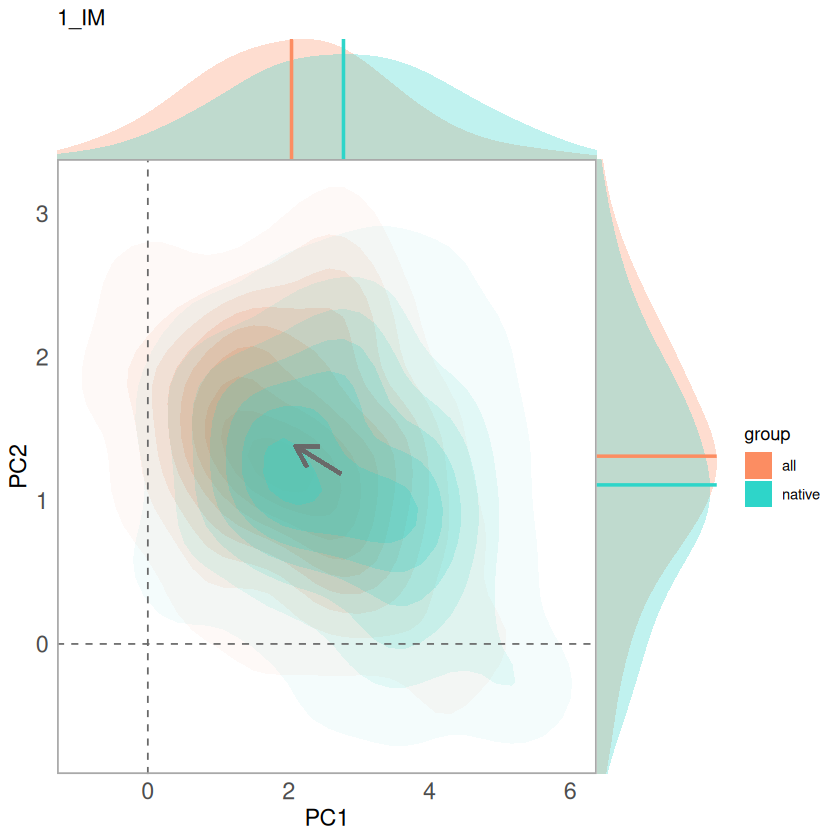

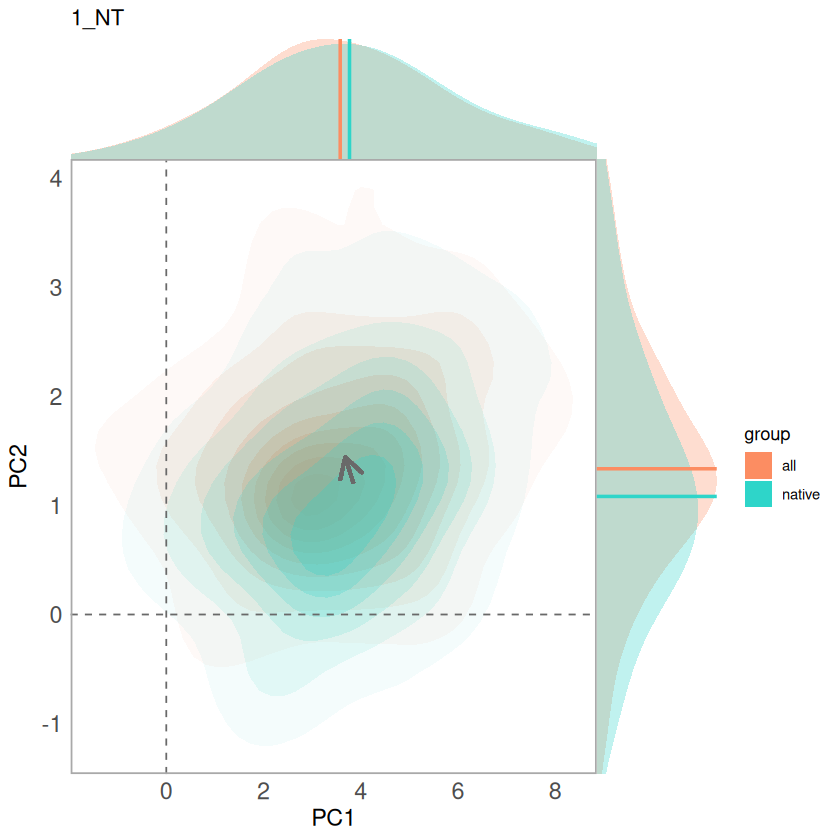

polygon has holes

Warning message:
“Removed 7 rows containing non-finite outside the scale range
(`stat_density()`).”
Warning message:
“Removed 9 rows containing non-finite outside the scale range
(`stat_density()`).”


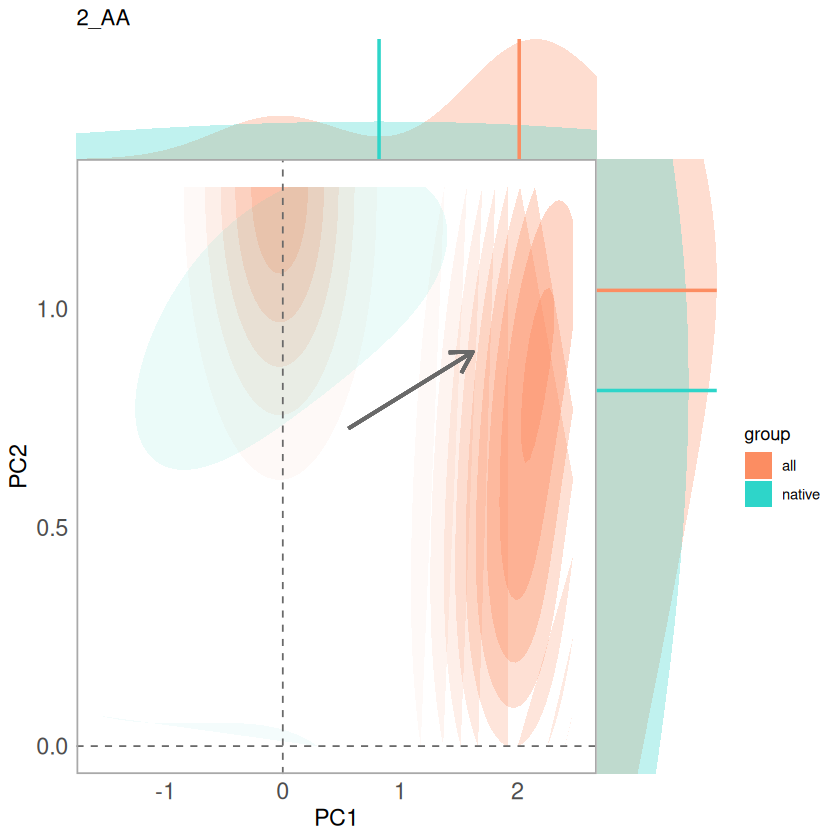

polygon has holes

polygon has holes

polygon has holes



polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

Warning message:
“Removed 6 rows containing non-finite outside the scale range
(`stat_density()`).”
Warning message:
“Removed 9 rows containing non-finite outside the scale range
(`stat_density()`).”


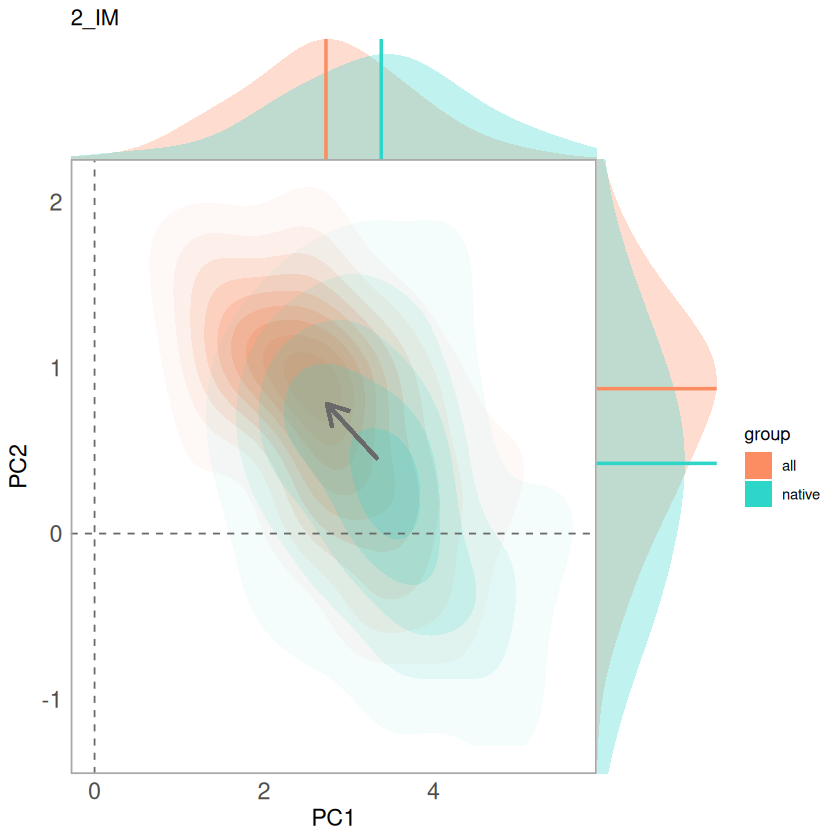

polygon has holes



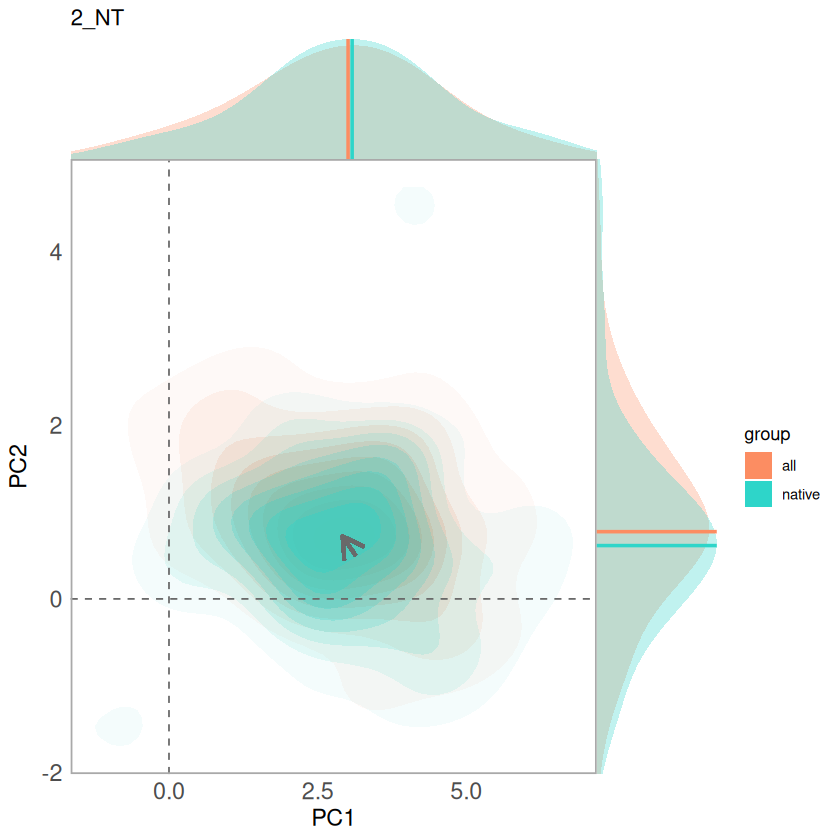

polygon has holes

polygon has holes

Warning message:
“Removed 1 row containing non-finite outside the scale range (`stat_density()`).”
Warning message:
“Removed 6 rows containing non-finite outside the scale range
(`stat_density()`).”


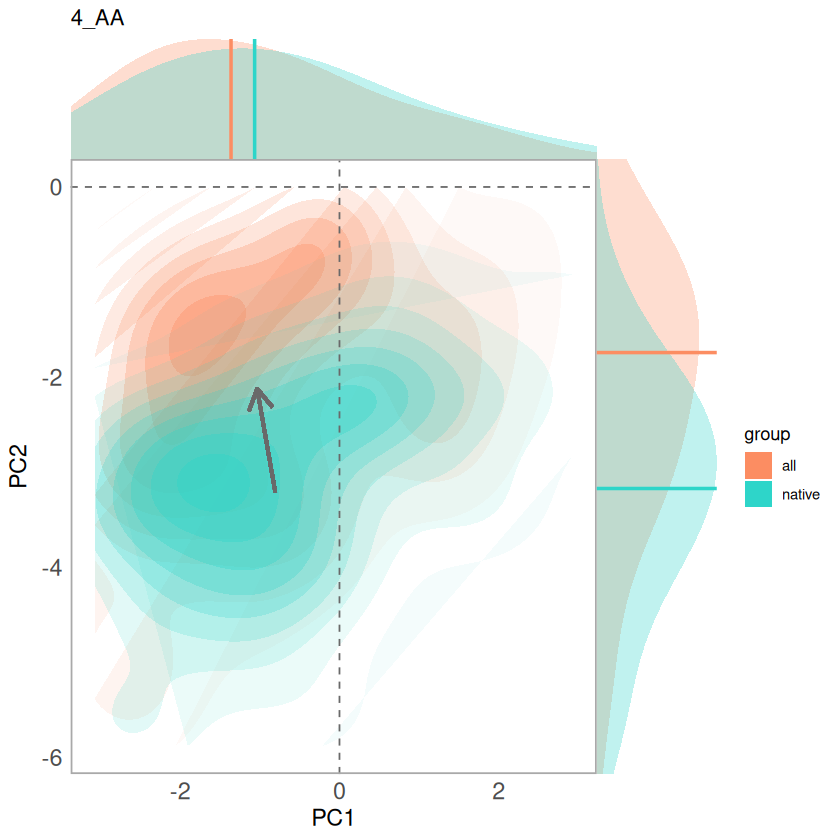

polygon has holes



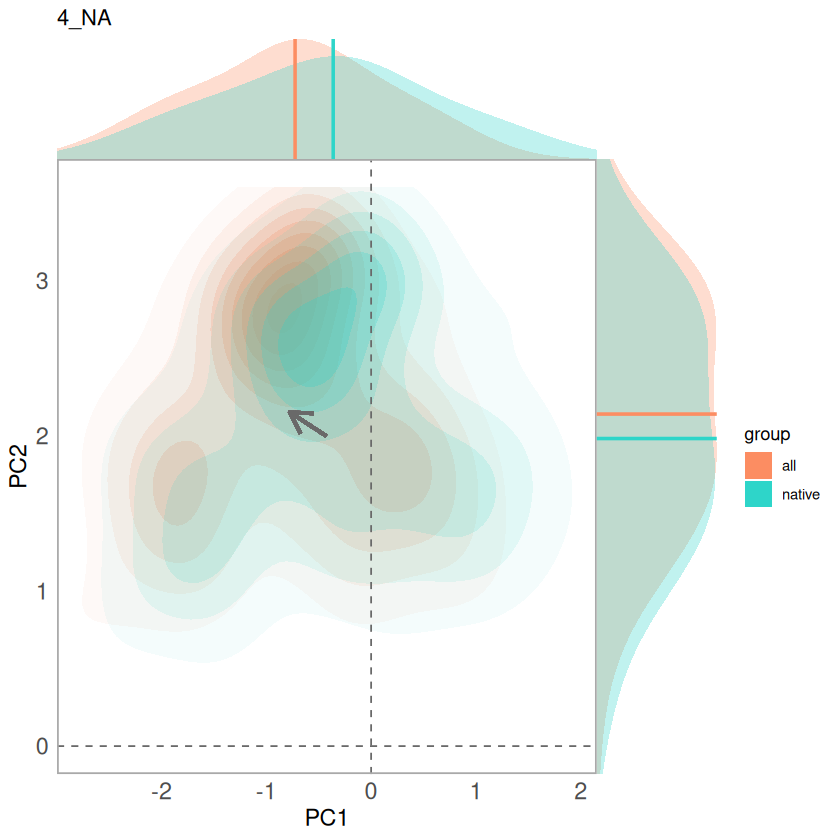

polygon has holes

polygon has holes

Warning message:
“Removed 10 rows containing non-finite outside the scale range
(`stat_density()`).”
Warning message:
“Removed 2 rows containing non-finite outside the scale range
(`stat_density()`).”


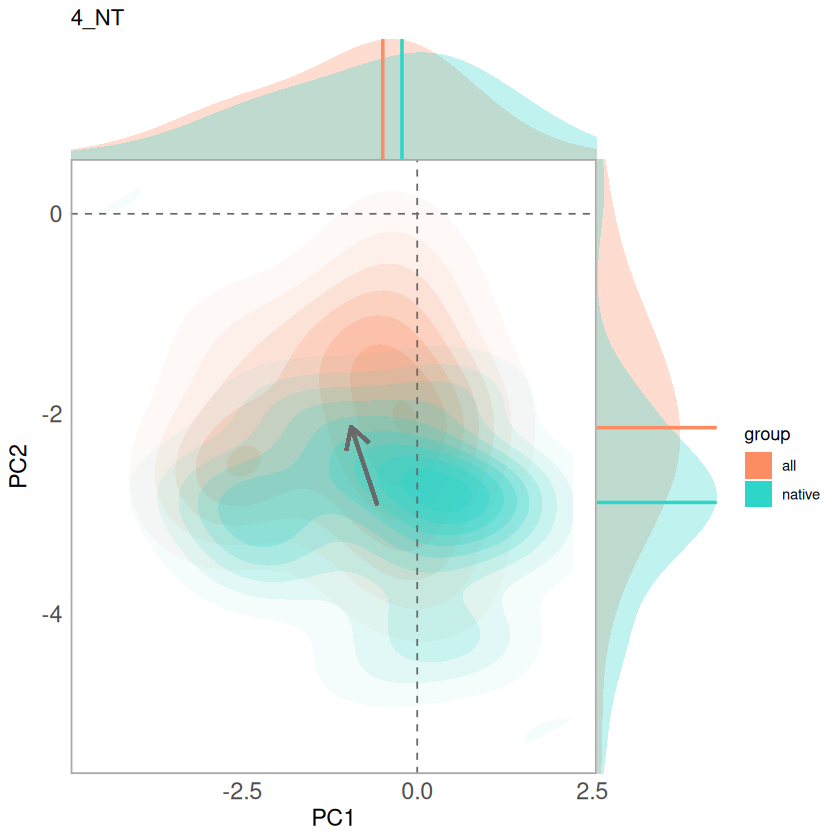

polygon has holes

Warning message:
“Removed 39 rows containing non-finite outside the scale range
(`stat_density()`).”
Warning message:
“Removed 14 rows containing non-finite outside the scale range
(`stat_density()`).”
Warning message:
“Removed 14 rows containing non-finite outside the scale range
(`stat_density()`).”
Warning message:
“Removed 12 rows containing non-finite outside the scale range
(`stat_density()`).”


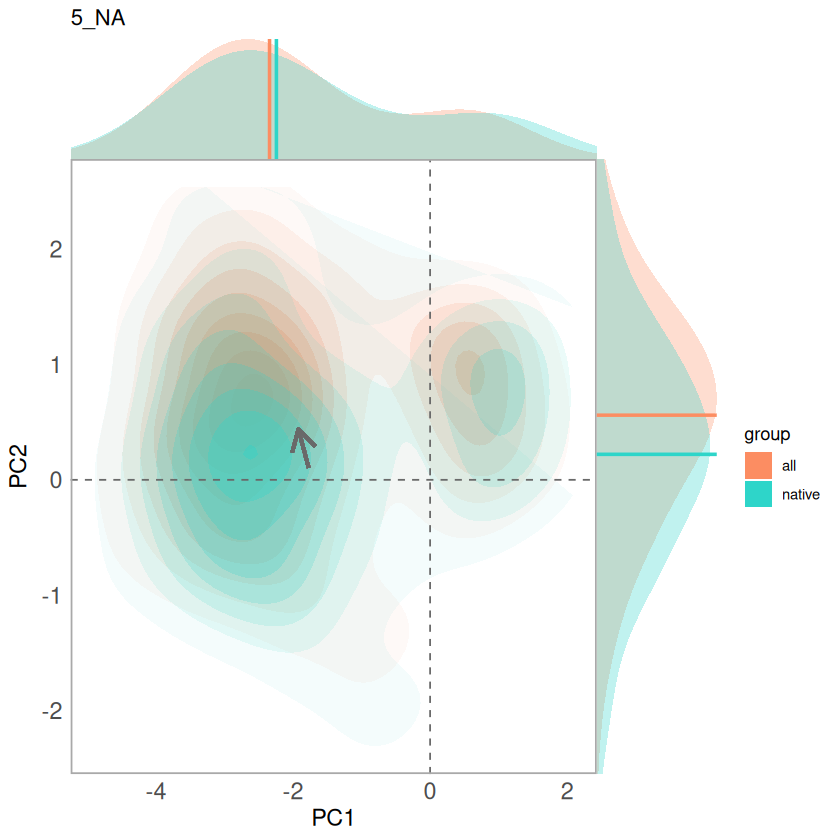

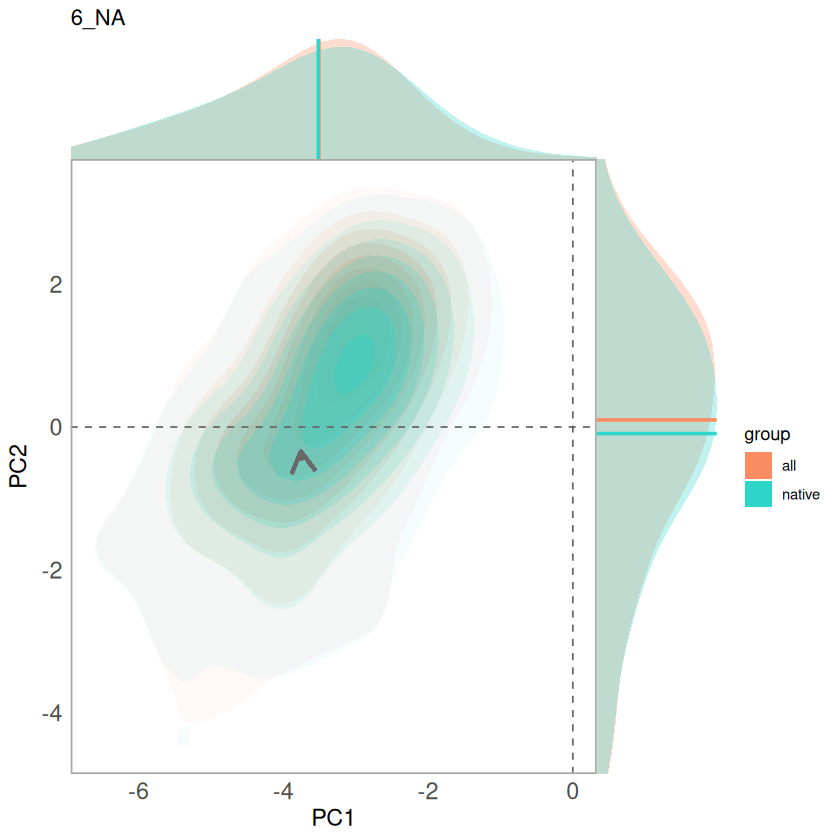

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

Warning message:
“Removed 22 rows containing non-finite outside the scale range
(`stat_density()`).”
Warning message:
“Removed 12 rows containing non-finite outside the scale range
(`stat_density()`).”


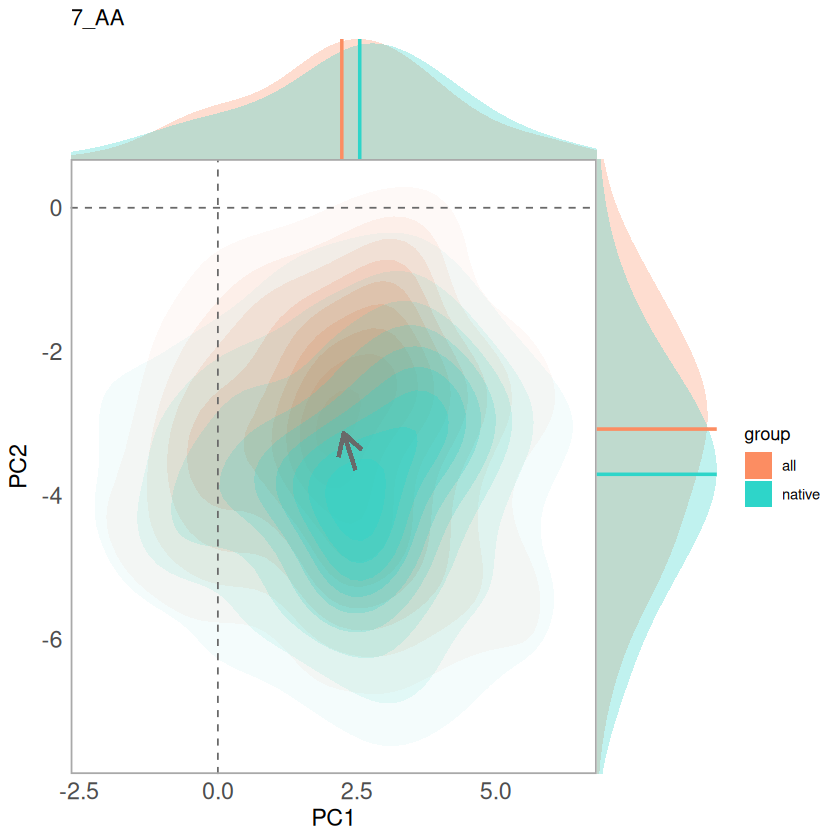

polygon has holes

polygon has holes

Warning message:
“Removed 2 rows containing non-finite outside the scale range
(`stat_density()`).”
Warning message:
“Removed 2 rows containing non-finite outside the scale range
(`stat_density()`).”
Warning message:
“Removed 4 rows containing non-finite outside the scale range
(`stat_density()`).”


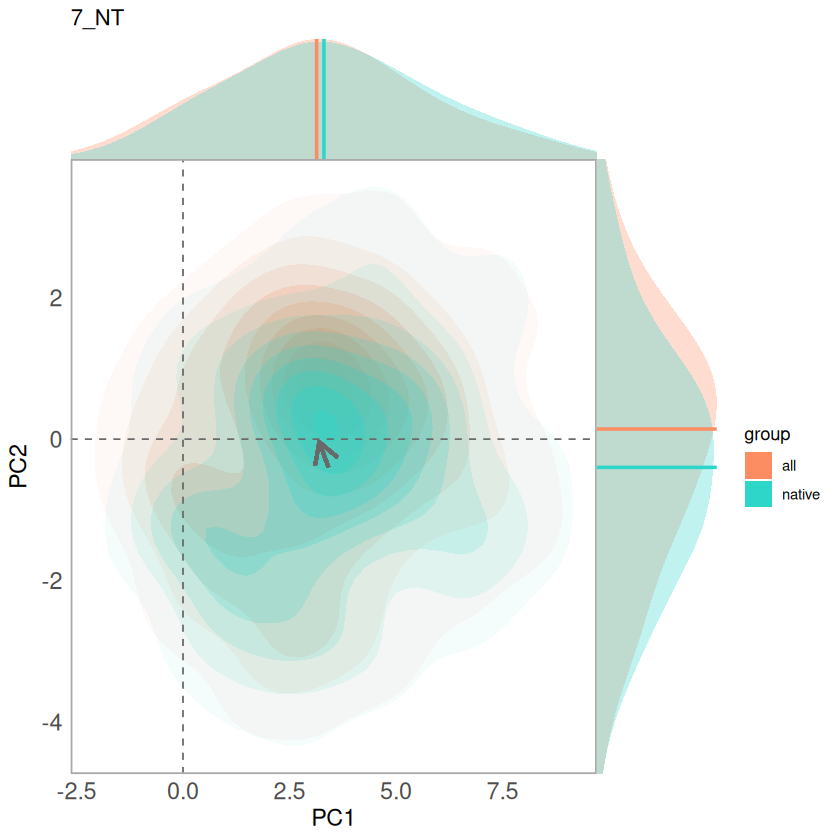

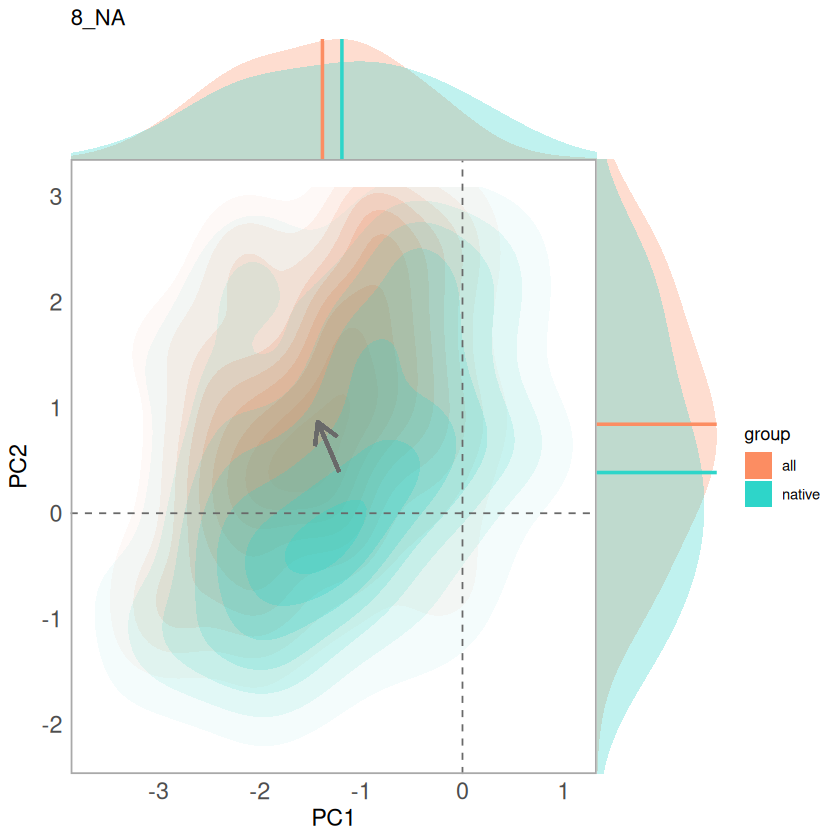

polygon has holes

polygon has holes

Warning message:
“Removed 2 rows containing non-finite outside the scale range
(`stat_density()`).”
Warning message:
“Removed 1 row containing non-finite outside the scale range (`stat_density()`).”
Warning message:
“Removed 4 rows containing non-finite outside the scale range
(`stat_density()`).”


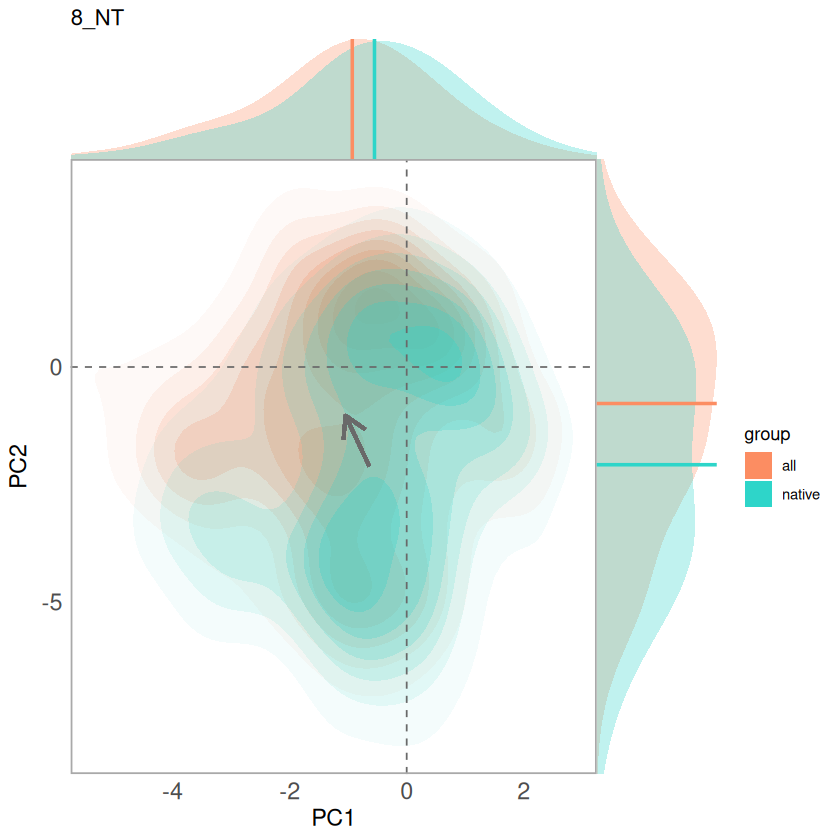

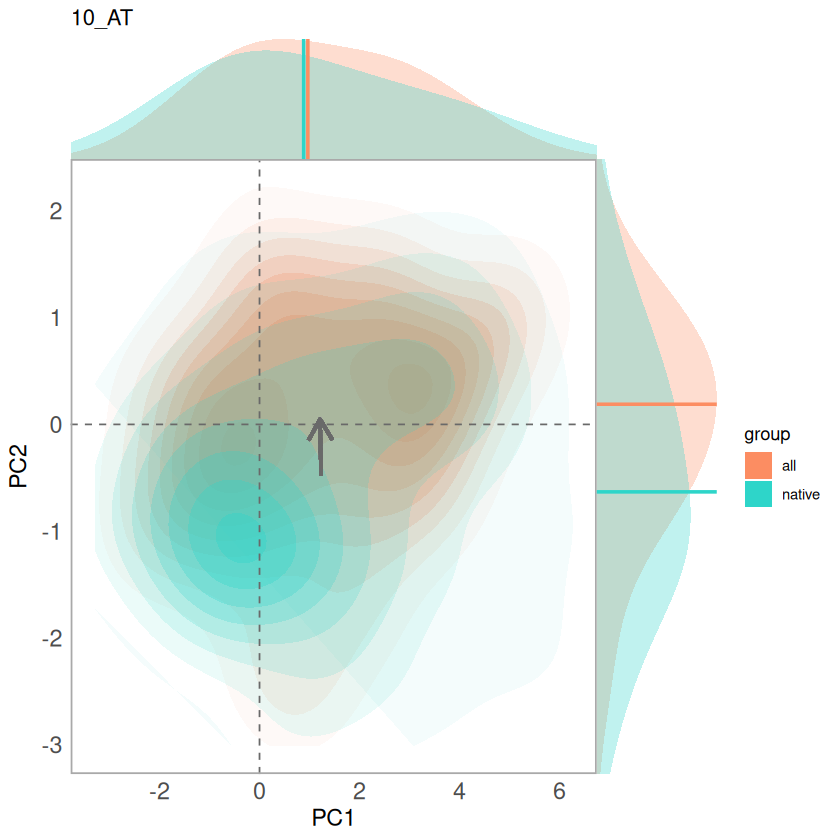

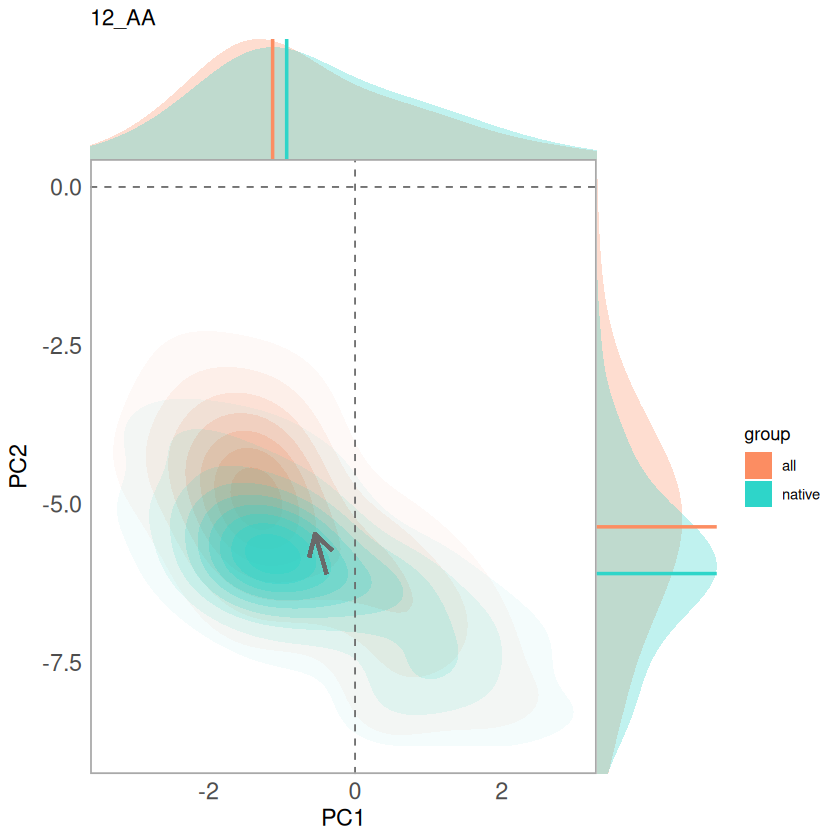

polygon has holes

polygon has holes

polygon has holes

polygon has holes

Warning message:
“Removed 11 rows containing non-finite outside the scale range
(`stat_density()`).”
Warning message:
“Removed 8 rows containing non-finite outside the scale range
(`stat_density()`).”


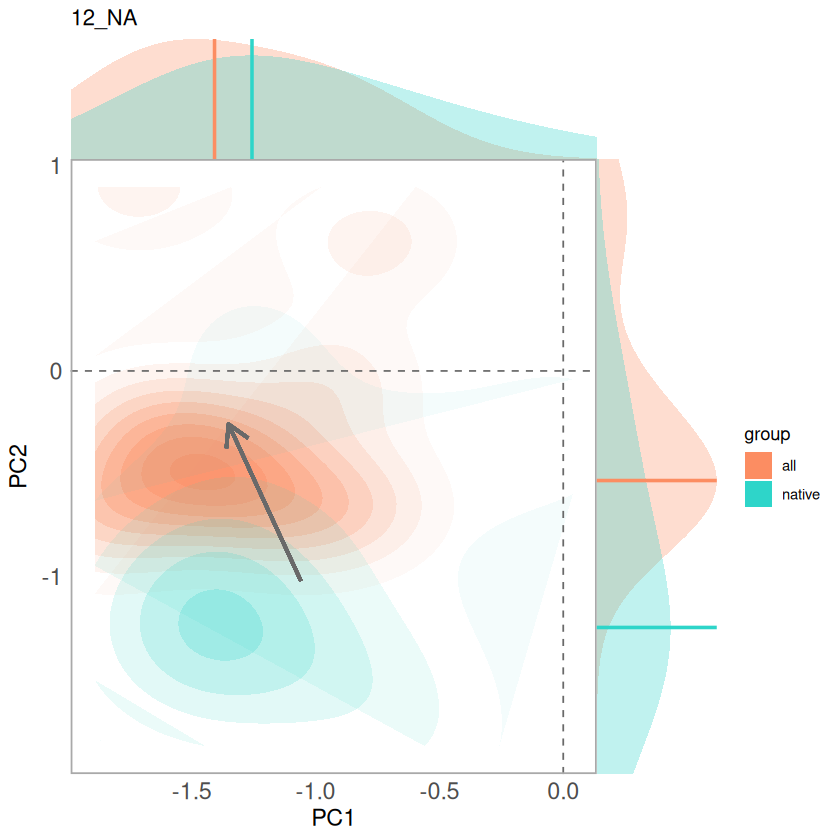

polygon has holes

Warning message:
“Removed 7 rows containing non-finite outside the scale range
(`stat_density()`).”
Warning message:
“Removed 13 rows containing non-finite outside the scale range
(`stat_density()`).”


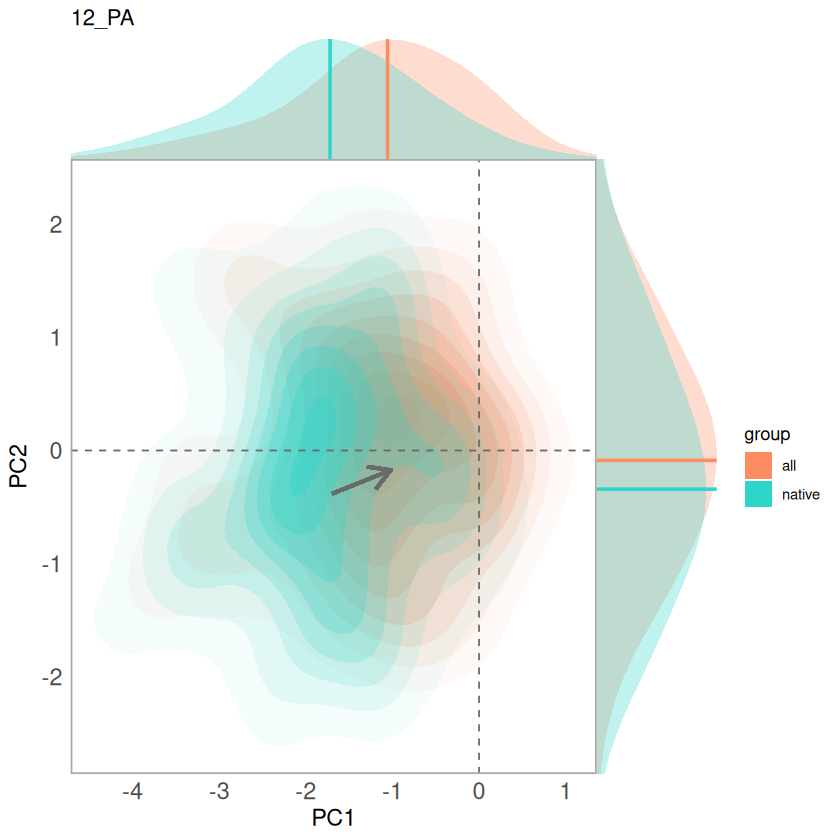

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

Warning message:
“Removed 7 rows containing non-finite outside the scale range
(`stat_density()`).”
Warning message:
“Removed 4 rows containing non-finite outside the scale range
(`stat_density()`).”


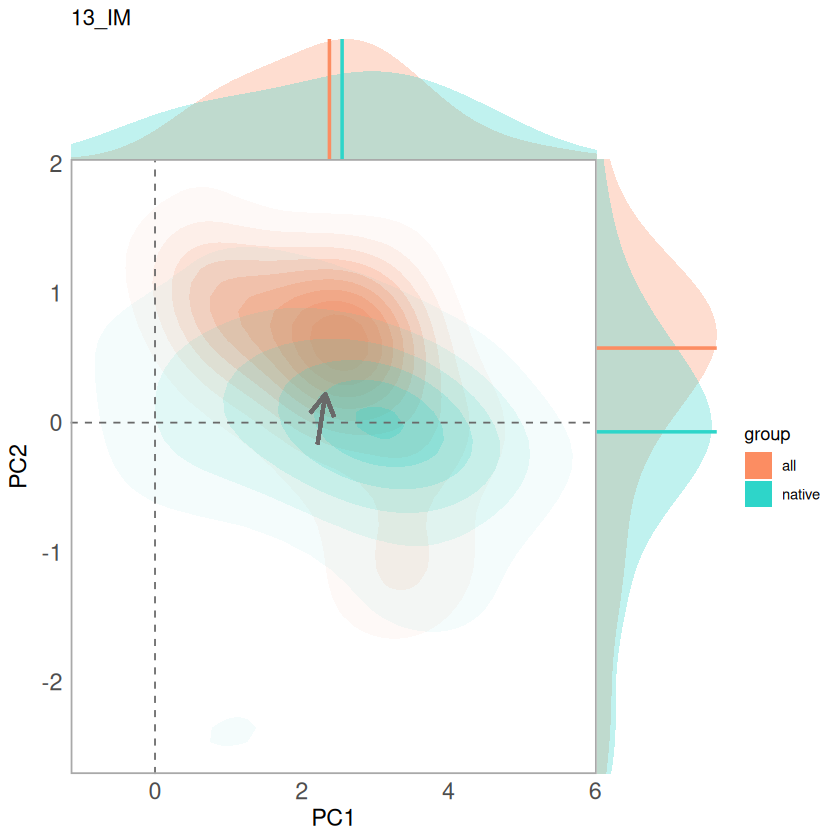

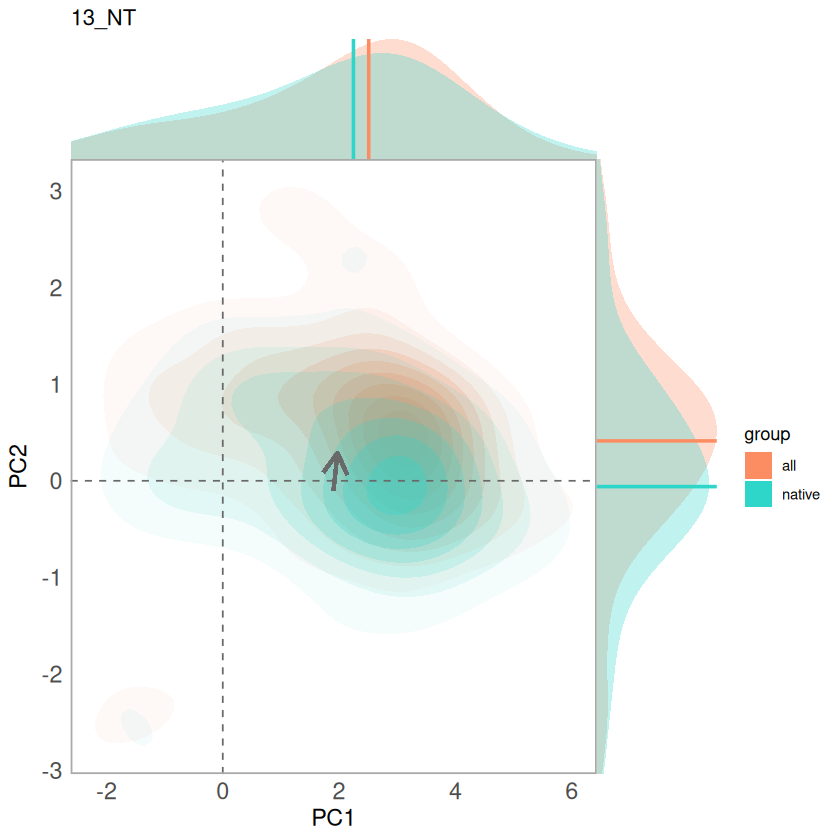

In [28]:
for (i in combined_results_gbif$region) {
  f <- wwf_aggregated[wwf_aggregated$bim_rlm == i, ]
  region_cells <- h3::polyfill(f, res = 3)
  filtered_data <- combined_data %>%
  filter(h3_res3 %in% region_cells)
  sub_plot <- perform_analysis(filtered_data, f)
  
  #pdf(file = paste0("~/Func_Neo_Phytes/Results/Figures/pca_", i, "_densities_biplot_wcvp_Olsen.pdf"),
  png(file = paste0("~/Func_Neo_Phytes/Results/Figures/pca_", i, "_biplot_CS_log10_missTree_density.png"),
      width = 10, height = 7, units = "in", res = 300)
  print(sub_plot)
  dev.off()
  
  print(sub_plot)
  
}

In [31]:

library(dplyr)
library(ggplot2)
library(cowplot)
library(h3)
library(sf)
library(MASS)




# ============================================================
# 2. Main analysis / plotting function
# ============================================================

perform_analysis_points <- function(
  filtered_data,
  polygon,
  h3_res = 3
) {



  # ----------------------------------------------------------
  # Main PC1 / PC2 plot
  # ----------------------------------------------------------

p <- ggplot(
  filtered_data,
  aes(x = PC1, y = PC2)
) +

  geom_point(
    aes(color = group),
    alpha = 0.7,
    size = 1
  ) +

  scale_color_manual(
    values = c(
      "all" = "#fc8d62",
      "native" = "#2ed5c9"
    )
  ) +

  theme_minimal() +

    theme(
      panel.grid = element_blank(),
      legend.position = "right",

      axis.title = element_text(
        size = 14
      ),

      axis.text = element_text(
        size = 14
      ),

      panel.border = element_rect(
        color = "darkgrey",
        fill = NA,
        linewidth = 1
      )
    ) +

    ggtitle(i)



  # ----------------------------------------------------------
  # Calculate centroids
  # ----------------------------------------------------------

  centroids <- filtered_data %>%

    group_by(group) %>%

    summarise(
      PC1 = mean(
        PC1,
        na.rm = TRUE
      ),

      PC2 = mean(
        PC2,
        na.rm = TRUE
      ),

      .groups = "drop"
    )


  centroid_native <- centroids %>%
    filter(group == "native")


  centroid_all <- centroids %>%
    filter(group == "all")



  # ----------------------------------------------------------
  # Add vector from native centroid to all centroid
  # ----------------------------------------------------------

  p <- p +

    geom_segment(
      aes(
        x = centroid_native$PC1,
        y = centroid_native$PC2,

        xend = centroid_all$PC1,
        yend = centroid_all$PC2
      ),

      color = "dimgrey",

      linewidth = 1,

      arrow = arrow(
        length = unit(
          0.2,
          "inches"
        )
      )
    )



  # ----------------------------------------------------------
  # Add lines at PC1 = 0 and PC2 = 0
  # ----------------------------------------------------------

  p <- p +

    geom_hline(
      yintercept = 0,
      color = "dimgrey",
      linetype = "dashed"
    ) +

    geom_vline(
      xintercept = 0,
      color = "dimgrey",
      linetype = "dashed"
    )



  # ----------------------------------------------------------
  # X-axis marginal density
  # ----------------------------------------------------------

  xdens <- axis_canvas(
    p,
    axis = "x"
  ) +

    geom_density(
      data = filtered_data,

      aes(
        x = PC1,
        fill = group
      ),

      alpha = 0.3,

      linewidth = 0.5,

      adjust = 1.5,

      color = NA
    ) +

    scale_fill_manual(
      values = c(
        "all" = "#fc8d62",
        "native" = "#2ed5c9"
      )
    ) +

    # Median lines
    geom_vline(
      data = filtered_data %>%

        group_by(group) %>%

        summarise(
          median_PC1 = median(
            PC1,
            na.rm = TRUE
          )
        ),

      aes(
        xintercept = median_PC1,
        color = group
      ),

      linetype = "solid",

      linewidth = 1
    ) +

    scale_color_manual(
      values = c(
        "all" = "#fc8d62",
        "native" = "#2ed5c9"
      )
    )



  # ----------------------------------------------------------
  # Y-axis marginal density
  # ----------------------------------------------------------

  ydens <- axis_canvas(
    p,
    axis = "y",
    coord_flip = TRUE
  ) +

    geom_density(
      data = filtered_data,

      aes(
        x = PC2,
        fill = group
      ),

      alpha = 0.3,

      linewidth = 0.5,

      adjust = 1.5,

      color = NA
    ) +

    scale_fill_manual(
      values = c(
        "all" = "#fc8d62",
        "native" = "#2ed5c9"
      )
    ) +

    # Median lines
    geom_vline(
      data = filtered_data %>%

        group_by(group) %>%

        summarise(
          median_PC2 = median(
            PC2,
            na.rm = TRUE
          )
        ),

      aes(
        xintercept = median_PC2,
        color = group
      ),

      linetype = "solid",

      linewidth = 1
    ) +

    scale_color_manual(
      values = c(
        "all" = "#fc8d62",
        "native" = "#2ed5c9"
      )
    ) +

    coord_flip()



  # ----------------------------------------------------------
  # Combine central plot + marginal densities
  # ----------------------------------------------------------

  final_plot <- p %>%

    insert_xaxis_grob(
      xdens,
      grid::unit(
        1,
        "in"
      ),
      position = "top"
    ) %>%

    insert_yaxis_grob(
      ydens,
      grid::unit(
        1,
        "in"
      ),
      position = "right"
    ) %>%

    ggdraw()



  # ----------------------------------------------------------
  # Return plot
  # ----------------------------------------------------------

  return(final_plot)

}


Warning message in geom_segment(aes(x = centroid_native$PC1, y = centroid_native$PC2, :
“All aesthetics have length 1, but the data has 14 rows.
ℹ Please consider using `annotate()` or provide this layer with data containing
  a single row.”
Warning message in geom_segment(aes(x = centroid_native$PC1, y = centroid_native$PC2, :
“All aesthetics have length 1, but the data has 14 rows.
ℹ Please consider using `annotate()` or provide this layer with data containing
  a single row.”
Warning message in geom_segment(aes(x = centroid_native$PC1, y = centroid_native$PC2, :
“All aesthetics have length 1, but the data has 14 rows.
ℹ Please consider using `annotate()` or provide this layer with data containing
  a single row.”
polygon has holes

polygon has holes

Warning message in geom_segment(aes(x = centroid_native$PC1, y = centroid_native$PC2, :
“All aesthetics have length 1, but the data has 120 rows.
ℹ Please consider using `annotate()` or provide this layer with data containing
  a single

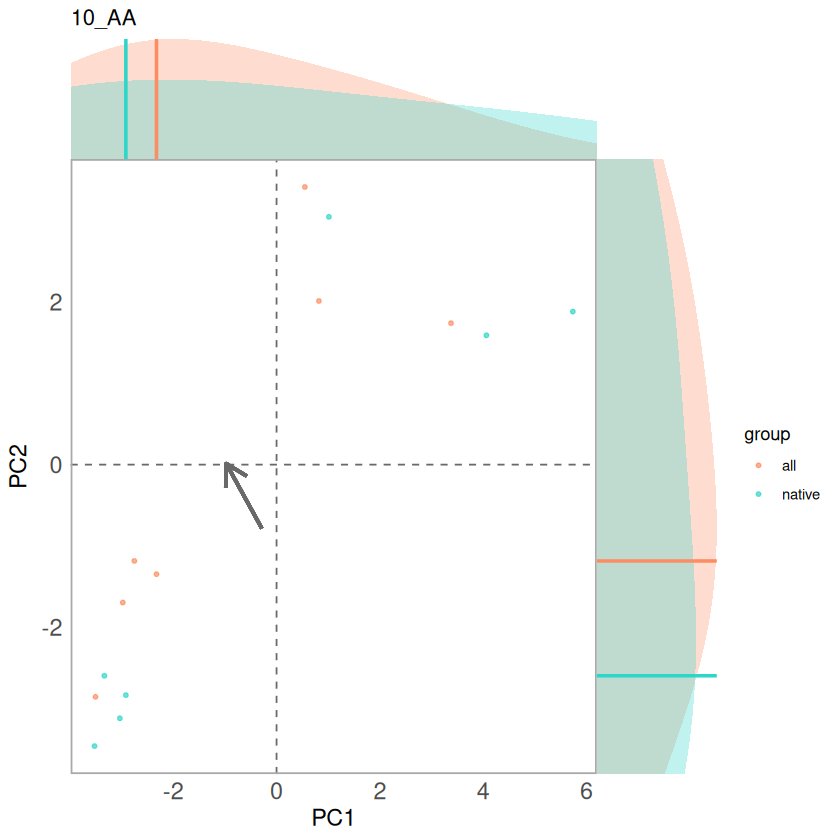

Warning message in geom_segment(aes(x = centroid_native$PC1, y = centroid_native$PC2, :
“All aesthetics have length 1, but the data has 2 rows.
ℹ Please consider using `annotate()` or provide this layer with data containing
  a single row.”
Warning message in geom_segment(aes(x = centroid_native$PC1, y = centroid_native$PC2, :
“All aesthetics have length 1, but the data has 2 rows.
ℹ Please consider using `annotate()` or provide this layer with data containing
  a single row.”
Warning message:
“Groups with fewer than two data points have been dropped.”
Warning message:
“Groups with fewer than two data points have been dropped.”
Warning message:
“Removed 2 rows containing missing values or values outside the scale range
(`geom_density()`).”
Warning message:
“Groups with fewer than two data points have been dropped.”
Warning message:
“Groups with fewer than two data points have been dropped.”


Warning message:
“Removed 2 rows containing missing values or values outside the scale range
(`geom_density()`).”
Warning message in geom_segment(aes(x = centroid_native$PC1, y = centroid_native$PC2, :
“All aesthetics have length 1, but the data has 2 rows.
ℹ Please consider using `annotate()` or provide this layer with data containing
  a single row.”


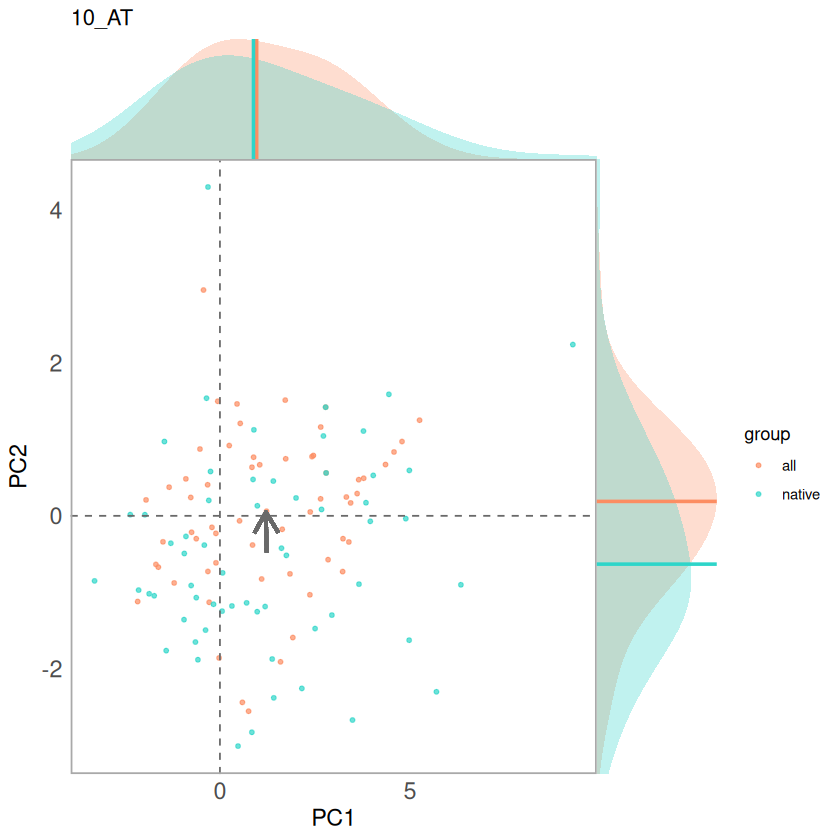

polygon has holes

Warning message in geom_segment(aes(x = centroid_native$PC1, y = centroid_native$PC2, :
“All aesthetics have length 1, but the data has 132 rows.
ℹ Please consider using `annotate()` or provide this layer with data containing
  a single row.”
Warning message in geom_segment(aes(x = centroid_native$PC1, y = centroid_native$PC2, :
“All aesthetics have length 1, but the data has 132 rows.
ℹ Please consider using `annotate()` or provide this layer with data containing
  a single row.”
Warning message in geom_segment(aes(x = centroid_native$PC1, y = centroid_native$PC2, :
“All aesthetics have length 1, but the data has 132 rows.
ℹ Please consider using `annotate()` or provide this layer with data containing
  a single row.”


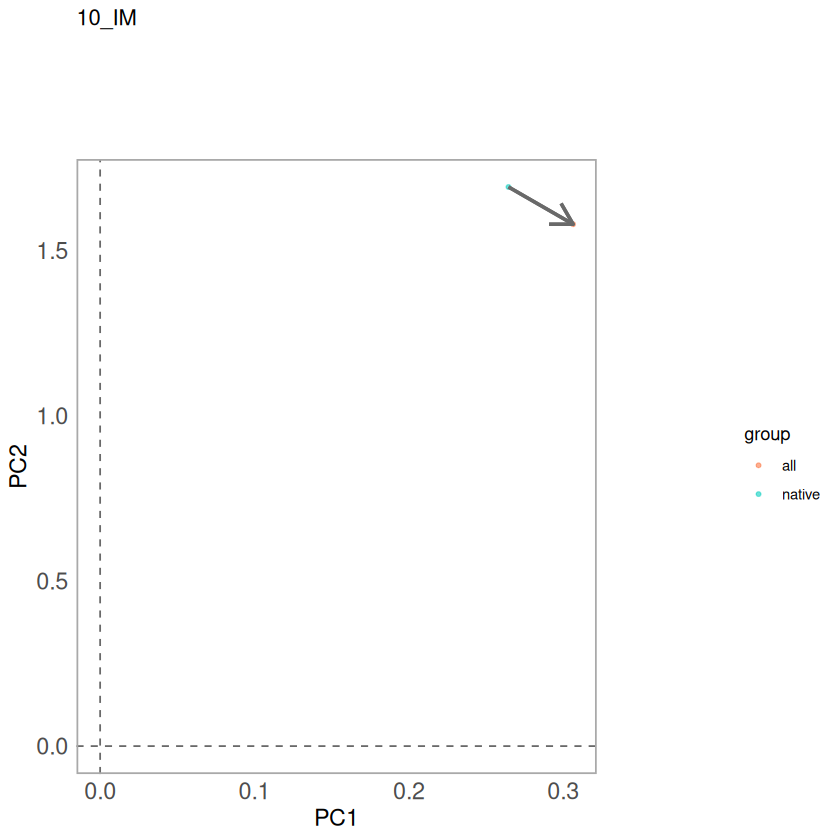

polygon has holes

polygon has holes

Warning message in geom_segment(aes(x = centroid_native$PC1, y = centroid_native$PC2, :
“All aesthetics have length 1, but the data has 374 rows.
ℹ Please consider using `annotate()` or provide this layer with data containing
  a single row.”
Warning message in geom_segment(aes(x = centroid_native$PC1, y = centroid_native$PC2, :
“All aesthetics have length 1, but the data has 374 rows.
ℹ Please consider using `annotate()` or provide this layer with data containing
  a single row.”
Warning message in geom_segment(aes(x = centroid_native$PC1, y = centroid_native$PC2, :
“All aesthetics have length 1, but the data has 374 rows.
ℹ Please consider using `annotate()` or provide this layer with data containing
  a single row.”


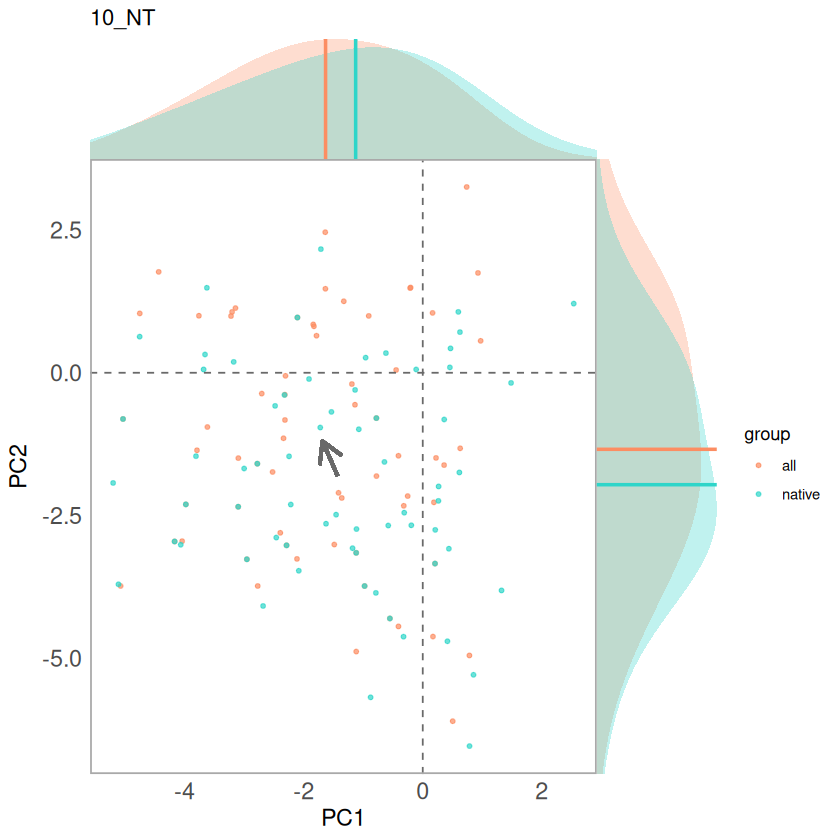

Warning message:
“No shared levels found between `names(values)` of the manual scale and the
data's colour values.”
Warning message:
“No shared levels found between `names(values)` of the manual scale and the
data's colour values.”
Warning message:
“No shared levels found between `names(values)` of the manual scale and the
data's fill values.”
Warning message:
“No shared levels found between `names(values)` of the manual scale and the
data's colour values.”
Warning message:
“No shared levels found between `names(values)` of the manual scale and the
data's fill values.”
Warning message:
“No shared levels found between `names(values)` of the manual scale and the
data's colour values.”
Warning message:
“No shared levels found between `names(values)` of the manual scale and the
data's colour values.”


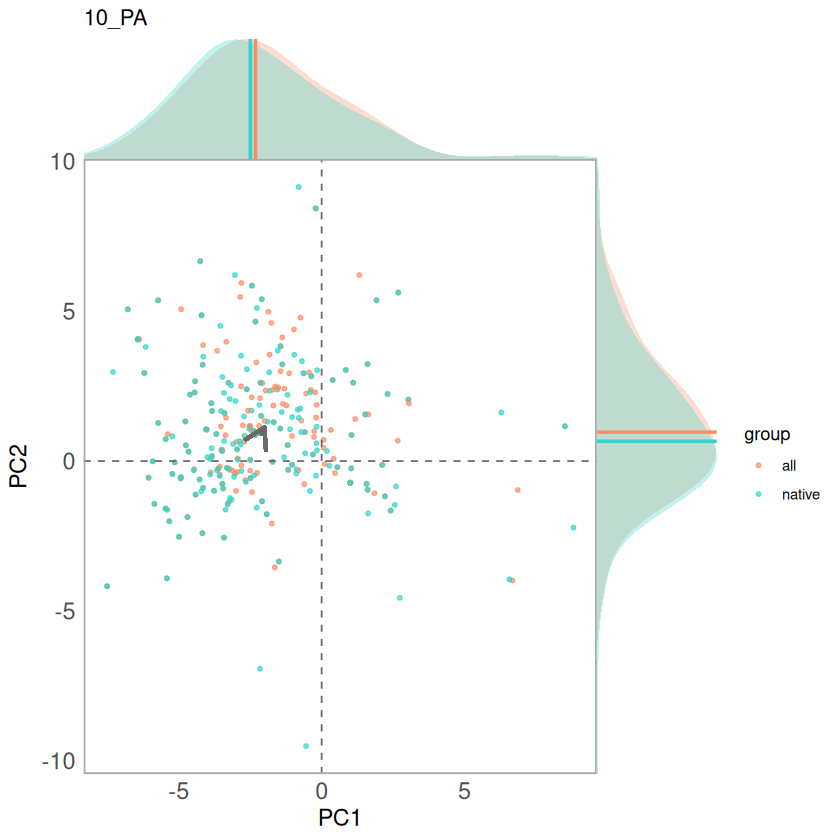

Warning message:
“No shared levels found between `names(values)` of the manual scale and the
data's colour values.”
Warning message:
“No shared levels found between `names(values)` of the manual scale and the
data's colour values.”
Warning message:
“No shared levels found between `names(values)` of the manual scale and the
data's fill values.”
Warning message:
“No shared levels found between `names(values)` of the manual scale and the
data's colour values.”
Warning message:
“No shared levels found between `names(values)` of the manual scale and the
data's fill values.”
Warning message:
“No shared levels found between `names(values)` of the manual scale and the
data's colour values.”
Warning message:
“No shared levels found between `names(values)` of the manual scale and the
data's colour values.”


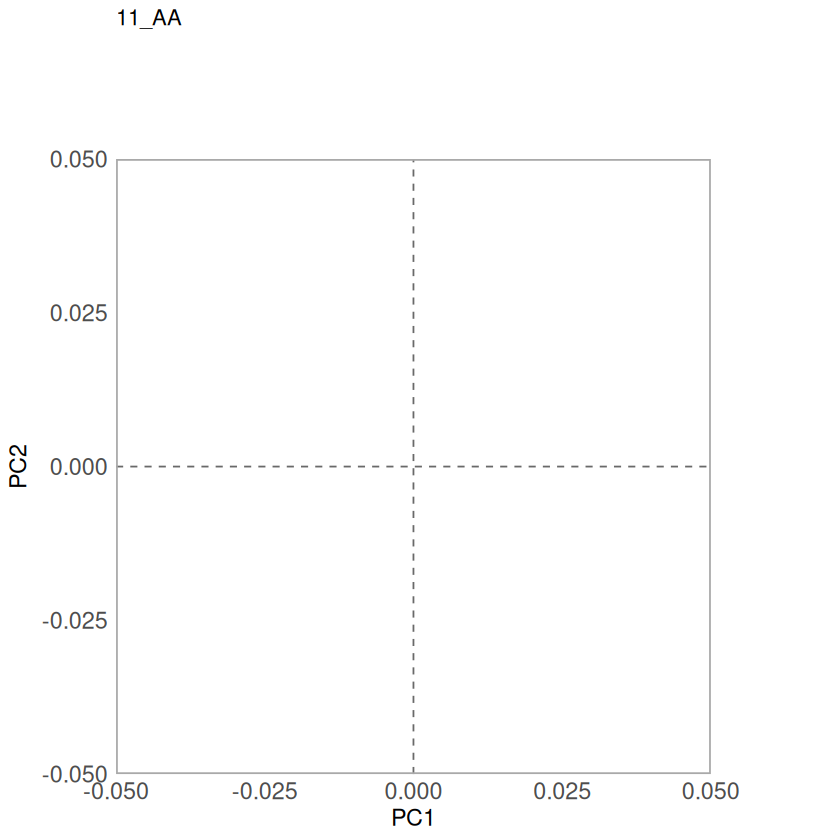

polygon has holes

Warning message in geom_segment(aes(x = centroid_native$PC1, y = centroid_native$PC2, :
“All aesthetics have length 1, but the data has 442 rows.
ℹ Please consider using `annotate()` or provide this layer with data containing
  a single row.”
Warning message in geom_segment(aes(x = centroid_native$PC1, y = centroid_native$PC2, :
“All aesthetics have length 1, but the data has 442 rows.
ℹ Please consider using `annotate()` or provide this layer with data containing
  a single row.”
Warning message in geom_segment(aes(x = centroid_native$PC1, y = centroid_native$PC2, :
“All aesthetics have length 1, but the data has 442 rows.
ℹ Please consider using `annotate()` or provide this layer with data containing
  a single row.”


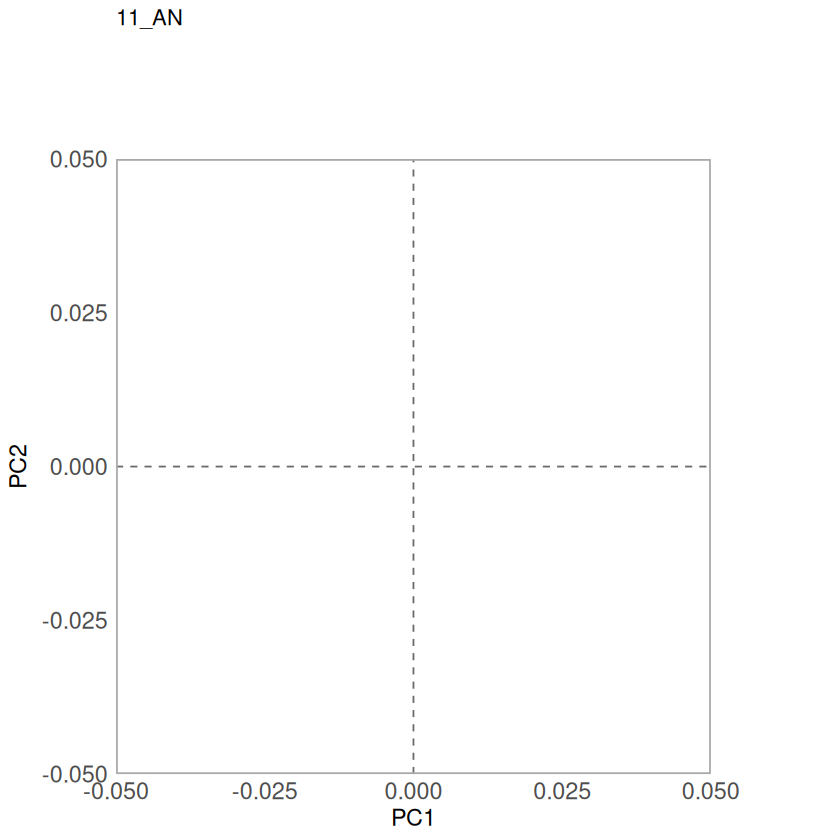

polygon has holes

Warning message in geom_segment(aes(x = centroid_native$PC1, y = centroid_native$PC2, :
“All aesthetics have length 1, but the data has 374 rows.
ℹ Please consider using `annotate()` or provide this layer with data containing
  a single row.”
Warning message in geom_segment(aes(x = centroid_native$PC1, y = centroid_native$PC2, :
“All aesthetics have length 1, but the data has 374 rows.
ℹ Please consider using `annotate()` or provide this layer with data containing
  a single row.”
Warning message in geom_segment(aes(x = centroid_native$PC1, y = centroid_native$PC2, :
“All aesthetics have length 1, but the data has 374 rows.
ℹ Please consider using `annotate()` or provide this layer with data containing
  a single row.”


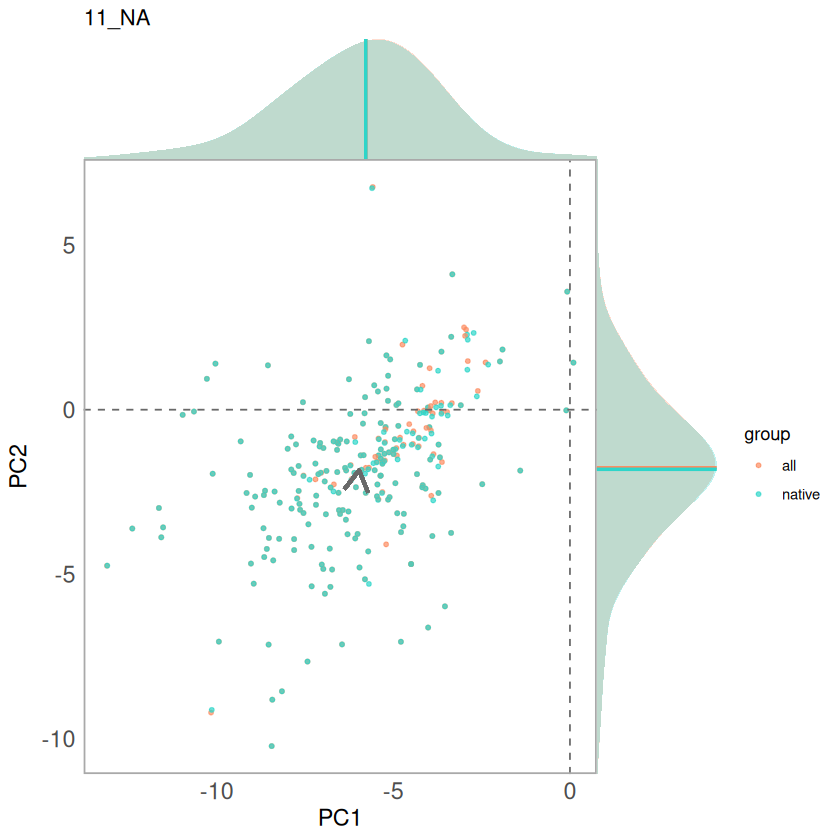

Warning message in geom_segment(aes(x = centroid_native$PC1, y = centroid_native$PC2, :
“All aesthetics have length 1, but the data has 140 rows.
ℹ Please consider using `annotate()` or provide this layer with data containing
  a single row.”
Warning message in geom_segment(aes(x = centroid_native$PC1, y = centroid_native$PC2, :
“All aesthetics have length 1, but the data has 140 rows.
ℹ Please consider using `annotate()` or provide this layer with data containing
  a single row.”
Warning message in geom_segment(aes(x = centroid_native$PC1, y = centroid_native$PC2, :
“All aesthetics have length 1, but the data has 140 rows.
ℹ Please consider using `annotate()` or provide this layer with data containing
  a single row.”


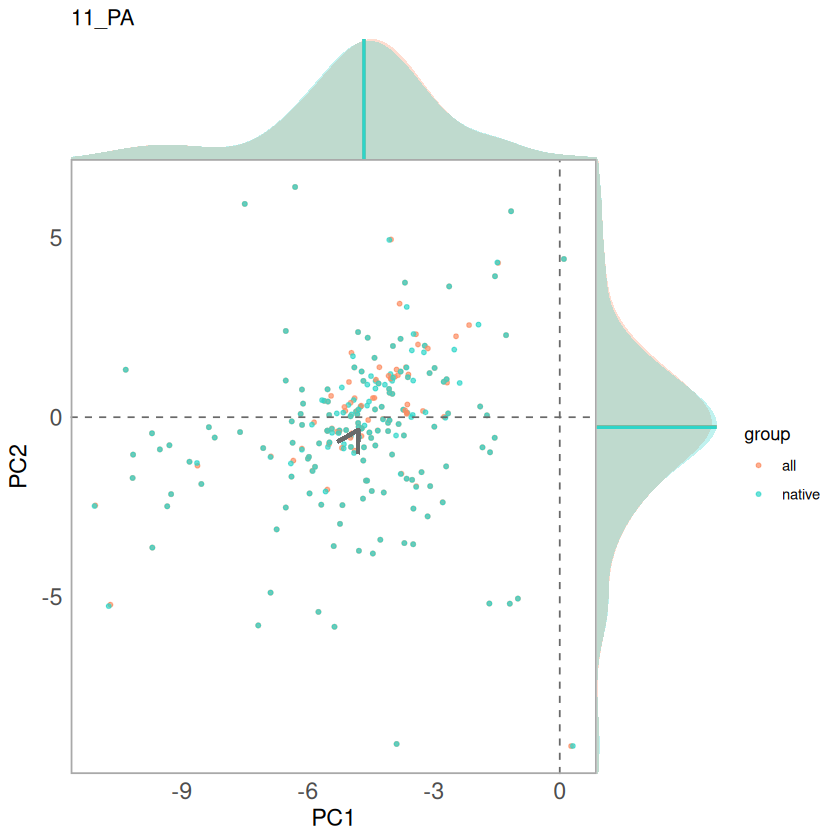

polygon has holes

Warning message in geom_segment(aes(x = centroid_native$PC1, y = centroid_native$PC2, :
“All aesthetics have length 1, but the data has 20 rows.
ℹ Please consider using `annotate()` or provide this layer with data containing
  a single row.”
Warning message in geom_segment(aes(x = centroid_native$PC1, y = centroid_native$PC2, :
“All aesthetics have length 1, but the data has 20 rows.
ℹ Please consider using `annotate()` or provide this layer with data containing
  a single row.”
Warning message in geom_segment(aes(x = centroid_native$PC1, y = centroid_native$PC2, :
“All aesthetics have length 1, but the data has 20 rows.
ℹ Please consider using `annotate()` or provide this layer with data containing
  a single row.”


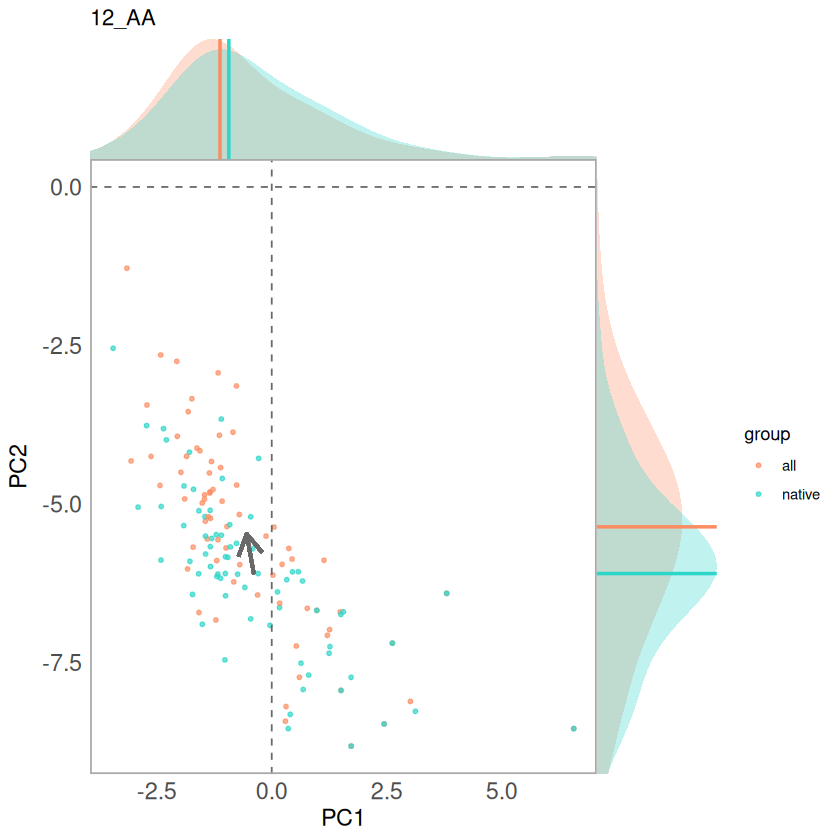

Warning message in geom_segment(aes(x = centroid_native$PC1, y = centroid_native$PC2, :
“All aesthetics have length 1, but the data has 22 rows.
ℹ Please consider using `annotate()` or provide this layer with data containing
  a single row.”
Warning message in geom_segment(aes(x = centroid_native$PC1, y = centroid_native$PC2, :
“All aesthetics have length 1, but the data has 22 rows.
ℹ Please consider using `annotate()` or provide this layer with data containing
  a single row.”
Warning message in geom_segment(aes(x = centroid_native$PC1, y = centroid_native$PC2, :
“All aesthetics have length 1, but the data has 22 rows.
ℹ Please consider using `annotate()` or provide this layer with data containing
  a single row.”


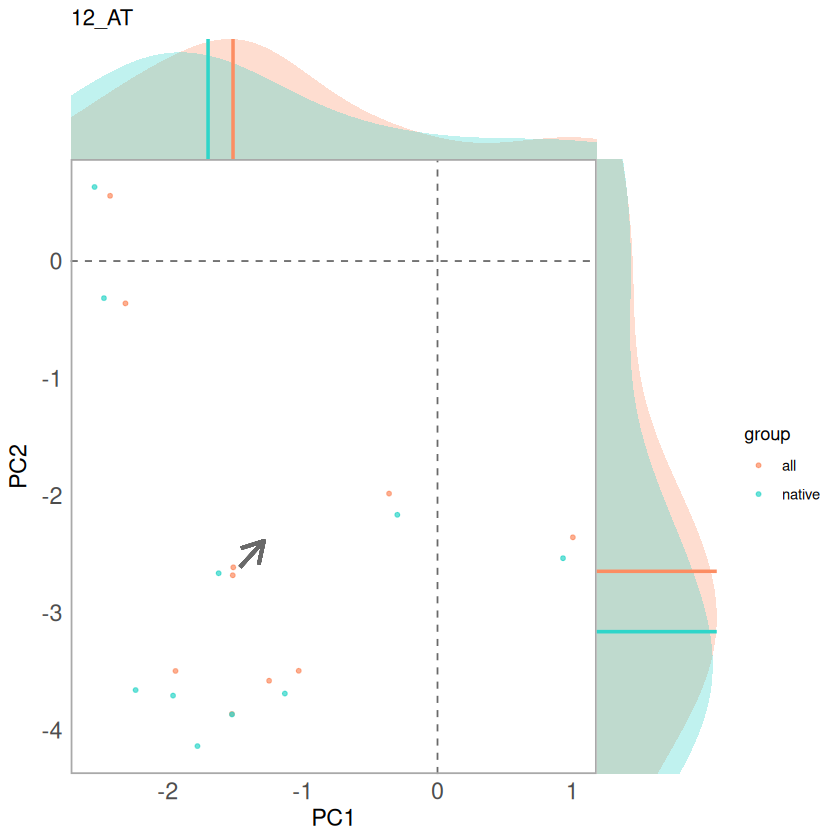

Warning message in geom_segment(aes(x = centroid_native$PC1, y = centroid_native$PC2, :
“All aesthetics have length 1, but the data has 28 rows.
ℹ Please consider using `annotate()` or provide this layer with data containing
  a single row.”
Warning message in geom_segment(aes(x = centroid_native$PC1, y = centroid_native$PC2, :
“All aesthetics have length 1, but the data has 28 rows.
ℹ Please consider using `annotate()` or provide this layer with data containing
  a single row.”
Warning message in geom_segment(aes(x = centroid_native$PC1, y = centroid_native$PC2, :
“All aesthetics have length 1, but the data has 28 rows.
ℹ Please consider using `annotate()` or provide this layer with data containing
  a single row.”


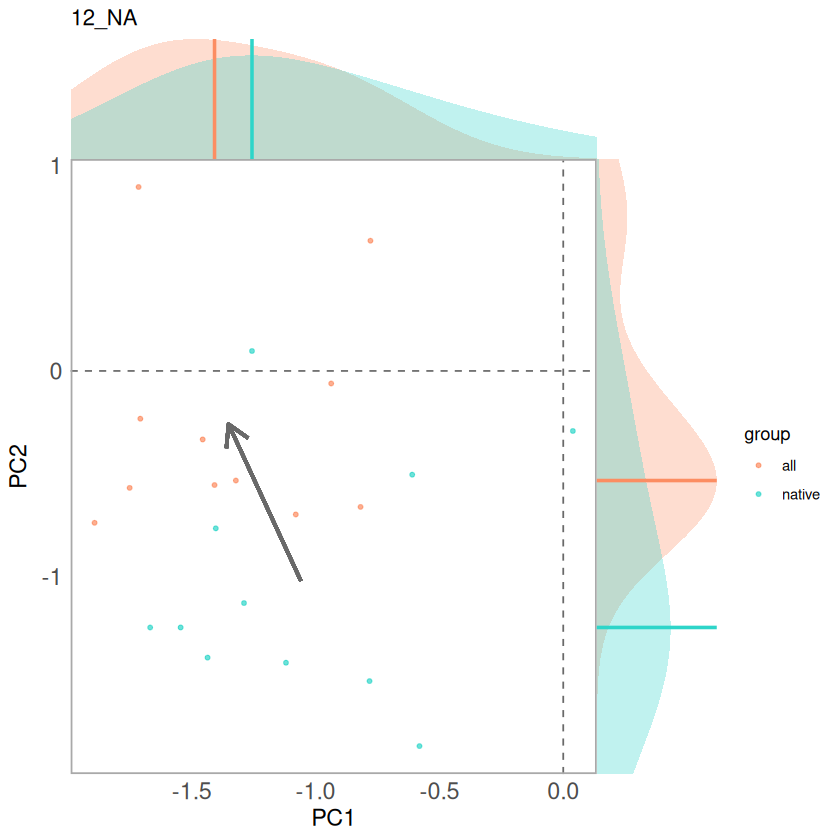

polygon has holes

polygon has holes

polygon has holes

polygon has holes

Warning message in geom_segment(aes(x = centroid_native$PC1, y = centroid_native$PC2, :
“All aesthetics have length 1, but the data has 320 rows.
ℹ Please consider using `annotate()` or provide this layer with data containing
  a single row.”
Warning message in geom_segment(aes(x = centroid_native$PC1, y = centroid_native$PC2, :
“All aesthetics have length 1, but the data has 320 rows.
ℹ Please consider using `annotate()` or provide this layer with data containing
  a single row.”
Warning message in geom_segment(aes(x = centroid_native$PC1, y = centroid_native$PC2, :
“All aesthetics have length 1, but the data has 320 rows.
ℹ Please consider using `annotate()` or provide this layer with data containing
  a single row.”


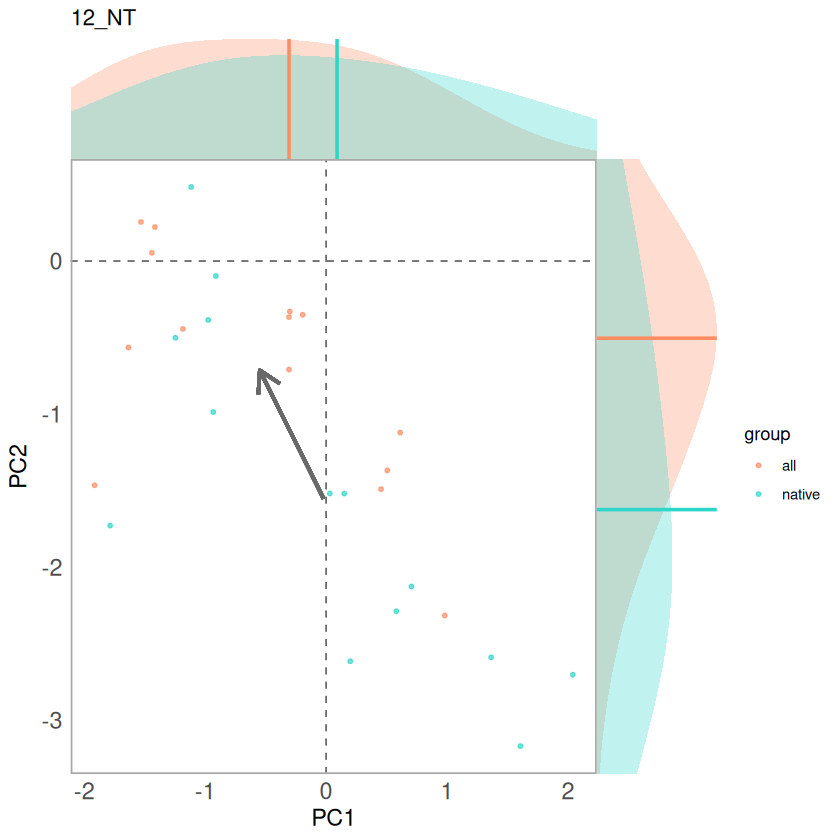

Warning message in geom_segment(aes(x = centroid_native$PC1, y = centroid_native$PC2, :
“All aesthetics have length 1, but the data has 516 rows.
ℹ Please consider using `annotate()` or provide this layer with data containing
  a single row.”
Warning message in geom_segment(aes(x = centroid_native$PC1, y = centroid_native$PC2, :
“All aesthetics have length 1, but the data has 516 rows.
ℹ Please consider using `annotate()` or provide this layer with data containing
  a single row.”
Warning message in geom_segment(aes(x = centroid_native$PC1, y = centroid_native$PC2, :
“All aesthetics have length 1, but the data has 516 rows.
ℹ Please consider using `annotate()` or provide this layer with data containing
  a single row.”


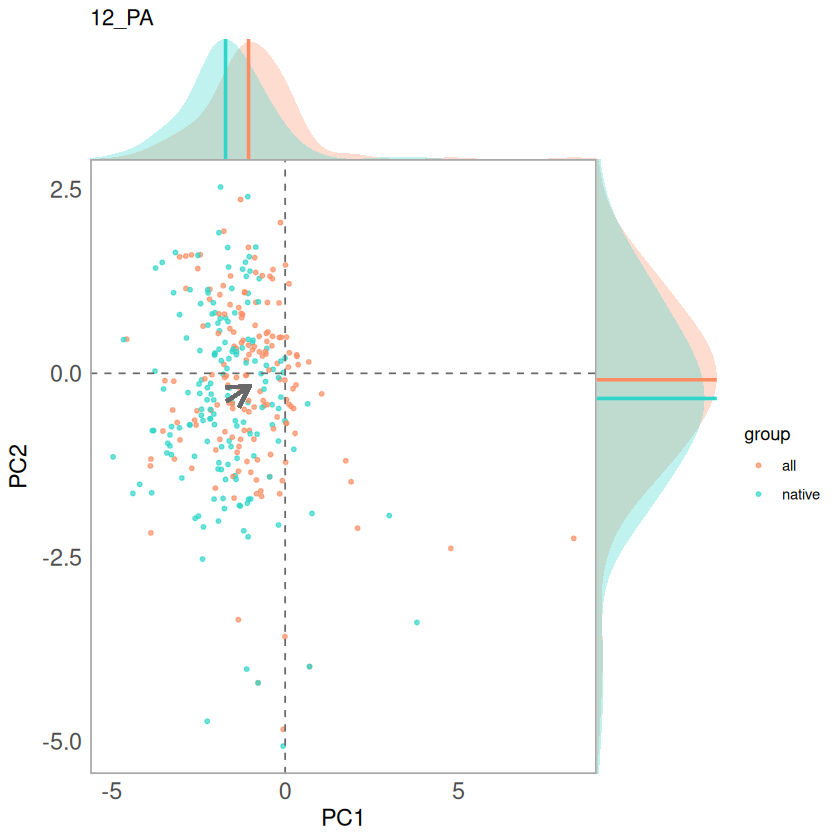

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

Warning message in geom_segment(aes(x = centroid_native$PC1, y = centroid_native$PC2, :
“All aesthetics have length 1, but the data has 334 rows.
ℹ Please consider using `annotate()` or provide this layer with data containing
  a single row.”
Warning message in geom_segment(aes(x = centroid_native$PC1, y = centroid_native$PC2, :
“All aesthetics have length 1, but the data has 334 rows.
ℹ Please consider using `annotate()` or provide this layer with data containing
  a single row.”
Warning message in geom_segment(aes(x = centroid_native$PC1, y = centroid_native$PC2, :
“All aesthetics have length 1, but the data has 334 rows.
ℹ Please consider using `annotate()` or provide this layer with data containing
  a single row.”


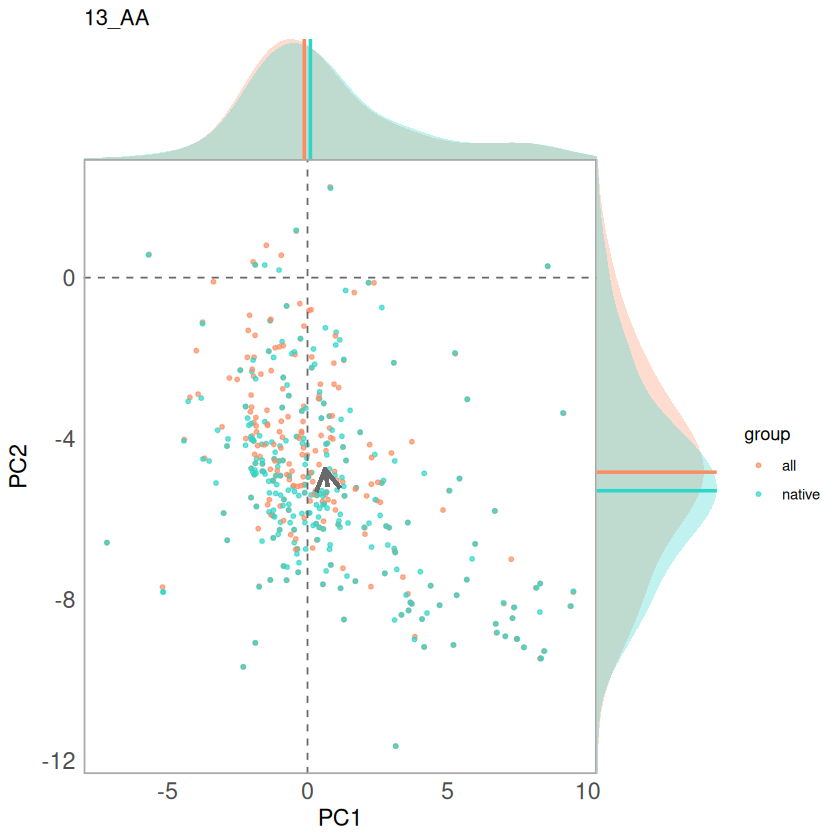

polygon has holes

Warning message in geom_segment(aes(x = centroid_native$PC1, y = centroid_native$PC2, :
“All aesthetics have length 1, but the data has 172 rows.
ℹ Please consider using `annotate()` or provide this layer with data containing
  a single row.”
Warning message in geom_segment(aes(x = centroid_native$PC1, y = centroid_native$PC2, :
“All aesthetics have length 1, but the data has 172 rows.
ℹ Please consider using `annotate()` or provide this layer with data containing
  a single row.”
Warning message in geom_segment(aes(x = centroid_native$PC1, y = centroid_native$PC2, :
“All aesthetics have length 1, but the data has 172 rows.
ℹ Please consider using `annotate()` or provide this layer with data containing
  a single row.”


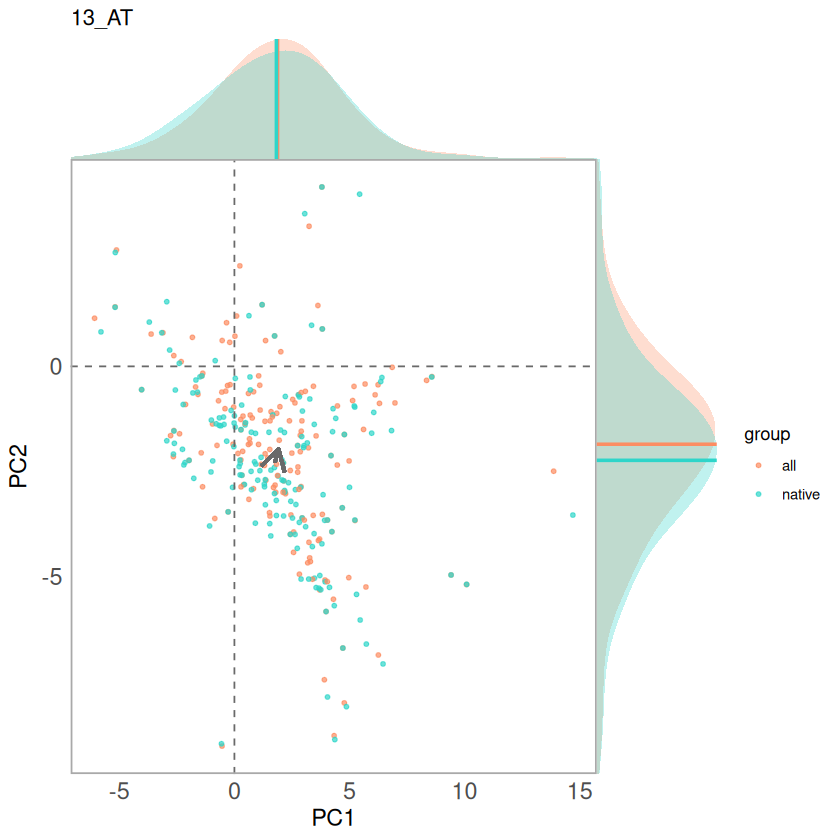

polygon has holes

polygon has holes

polygon has holes

Warning message in geom_segment(aes(x = centroid_native$PC1, y = centroid_native$PC2, :
“All aesthetics have length 1, but the data has 338 rows.
ℹ Please consider using `annotate()` or provide this layer with data containing
  a single row.”
Warning message in geom_segment(aes(x = centroid_native$PC1, y = centroid_native$PC2, :
“All aesthetics have length 1, but the data has 338 rows.
ℹ Please consider using `annotate()` or provide this layer with data containing
  a single row.”
Warning message in geom_segment(aes(x = centroid_native$PC1, y = centroid_native$PC2, :
“All aesthetics have length 1, but the data has 338 rows.
ℹ Please consider using `annotate()` or provide this layer with data containing
  a single row.”


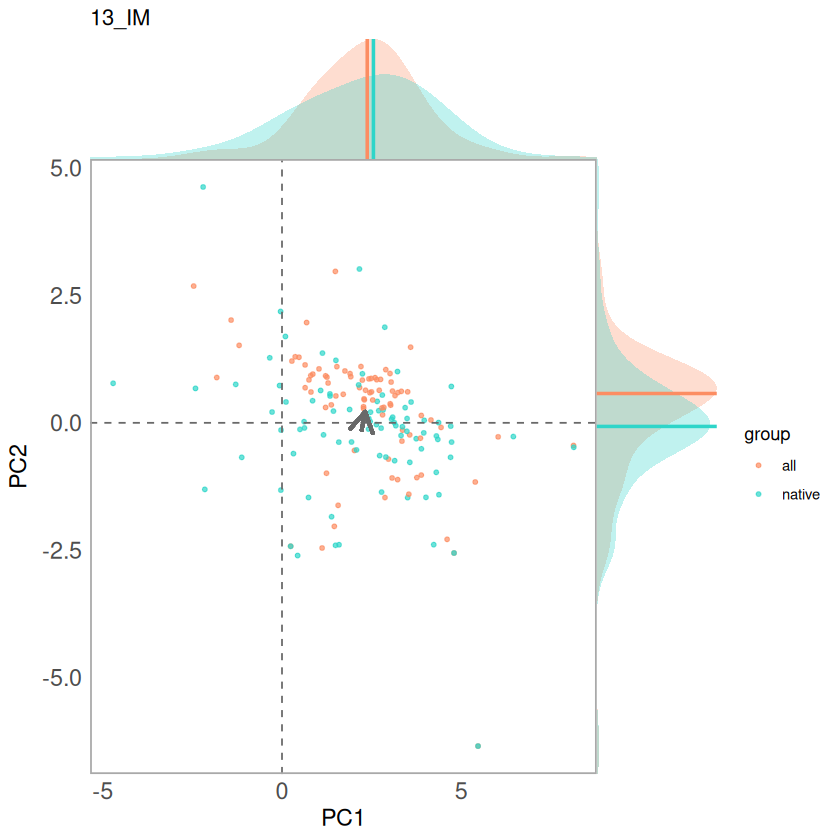

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

Warning message in geom_segment(aes(x = centroid_native$PC1, y = centroid_native$PC2, :
“All aesthetics have length 1, but the data has 170 rows.
ℹ Please consider using `annotate()` or provide this layer with data containing
  a single row.”
Warning message in geom_segment(aes(x = centroid_native$PC1, y = centroid_native$PC2, :
“All aesthetics have length 1, but the data has 170 rows.
ℹ Please consider using `annotate()` or provide this layer with data containing
  a single row.”
Warning message in geom_segment(aes(x = centroid_native$PC1, y = centroid_native$PC2, :
“All aesthetics have length 1, but the data has 170 rows.
ℹ Please consider using `annotate()` or provide this layer with data containing
  a single row.”


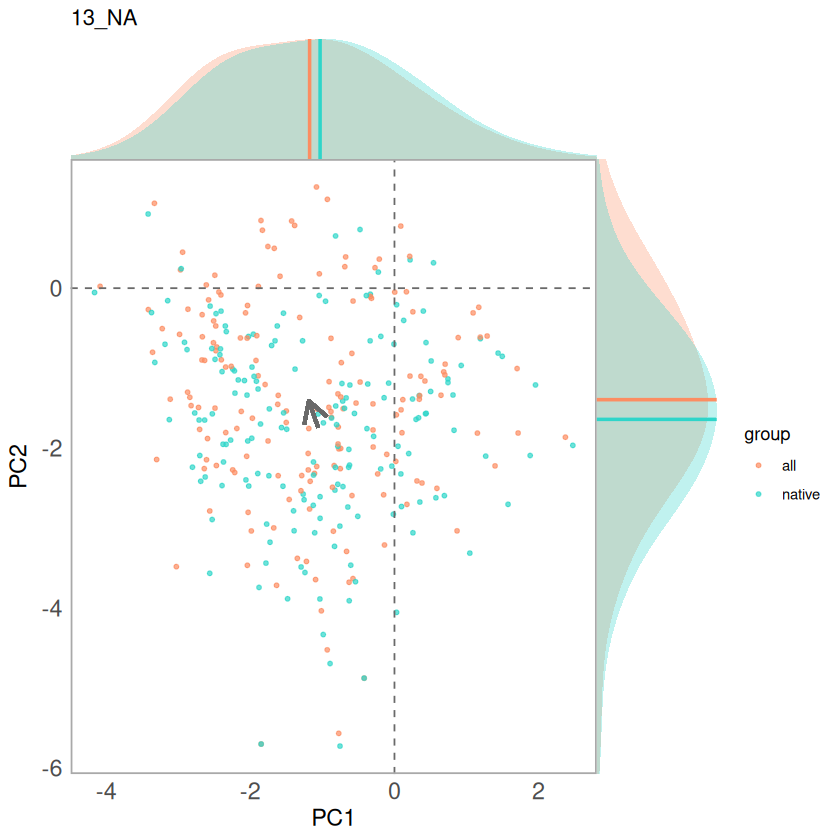

polygon has holes

polygon has holes

Warning message in geom_segment(aes(x = centroid_native$PC1, y = centroid_native$PC2, :
“All aesthetics have length 1, but the data has 1276 rows.
ℹ Please consider using `annotate()` or provide this layer with data containing
  a single row.”
Warning message in geom_segment(aes(x = centroid_native$PC1, y = centroid_native$PC2, :
“All aesthetics have length 1, but the data has 1276 rows.
ℹ Please consider using `annotate()` or provide this layer with data containing
  a single row.”
Warning message in geom_segment(aes(x = centroid_native$PC1, y = centroid_native$PC2, :
“All aesthetics have length 1, but the data has 1276 rows.
ℹ Please consider using `annotate()` or provide this layer with data containing
  a single row.”


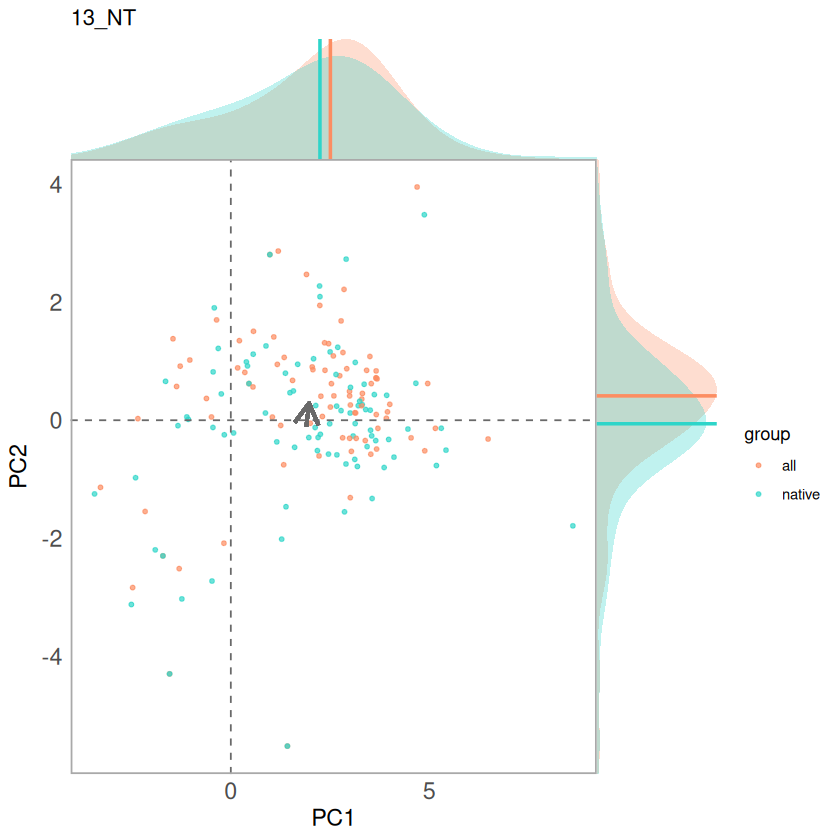

Warning message in geom_segment(aes(x = centroid_native$PC1, y = centroid_native$PC2, :
“All aesthetics have length 1, but the data has 2 rows.
ℹ Please consider using `annotate()` or provide this layer with data containing
  a single row.”
Warning message in geom_segment(aes(x = centroid_native$PC1, y = centroid_native$PC2, :
“All aesthetics have length 1, but the data has 2 rows.
ℹ Please consider using `annotate()` or provide this layer with data containing
  a single row.”
Warning message:
“Groups with fewer than two data points have been dropped.”
Warning message:
“Groups with fewer than two data points have been dropped.”
Warning message:
“Removed 2 rows containing missing values or values outside the scale range
(`geom_density()`).”
Warning message:
“Groups with fewer than two data points have been dropped.”
Warning message:
“Groups with fewer than two data points have been dropped.”
Warning message:
“Removed 2 rows containing missing values or values outside the scale range
(`g

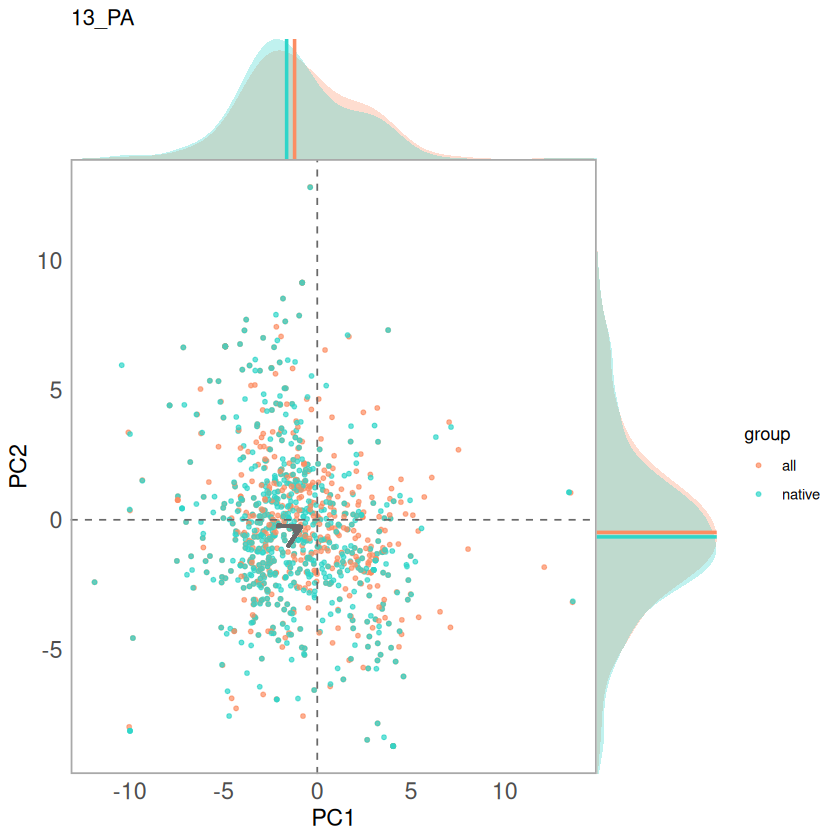

Warning message in geom_segment(aes(x = centroid_native$PC1, y = centroid_native$PC2, :
“All aesthetics have length 1, but the data has 8 rows.
ℹ Please consider using `annotate()` or provide this layer with data containing
  a single row.”
Warning message in geom_segment(aes(x = centroid_native$PC1, y = centroid_native$PC2, :
“All aesthetics have length 1, but the data has 8 rows.
ℹ Please consider using `annotate()` or provide this layer with data containing
  a single row.”
Warning message in geom_segment(aes(x = centroid_native$PC1, y = centroid_native$PC2, :
“All aesthetics have length 1, but the data has 8 rows.
ℹ Please consider using `annotate()` or provide this layer with data containing
  a single row.”


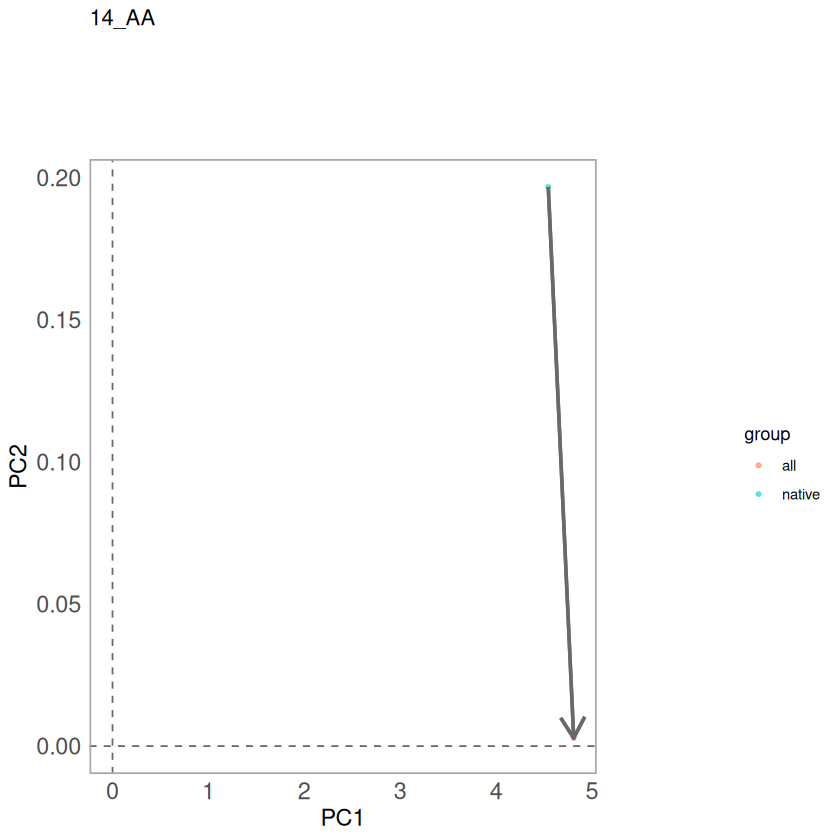

polygon has holes

polygon has holes

polygon has holes

Warning message in geom_segment(aes(x = centroid_native$PC1, y = centroid_native$PC2, :
“All aesthetics have length 1, but the data has 12 rows.
ℹ Please consider using `annotate()` or provide this layer with data containing
  a single row.”
Warning message in geom_segment(aes(x = centroid_native$PC1, y = centroid_native$PC2, :
“All aesthetics have length 1, but the data has 12 rows.
ℹ Please consider using `annotate()` or provide this layer with data containing
  a single row.”
Warning message in geom_segment(aes(x = centroid_native$PC1, y = centroid_native$PC2, :
“All aesthetics have length 1, but the data has 12 rows.
ℹ Please consider using `annotate()` or provide this layer with data containing
  a single row.”


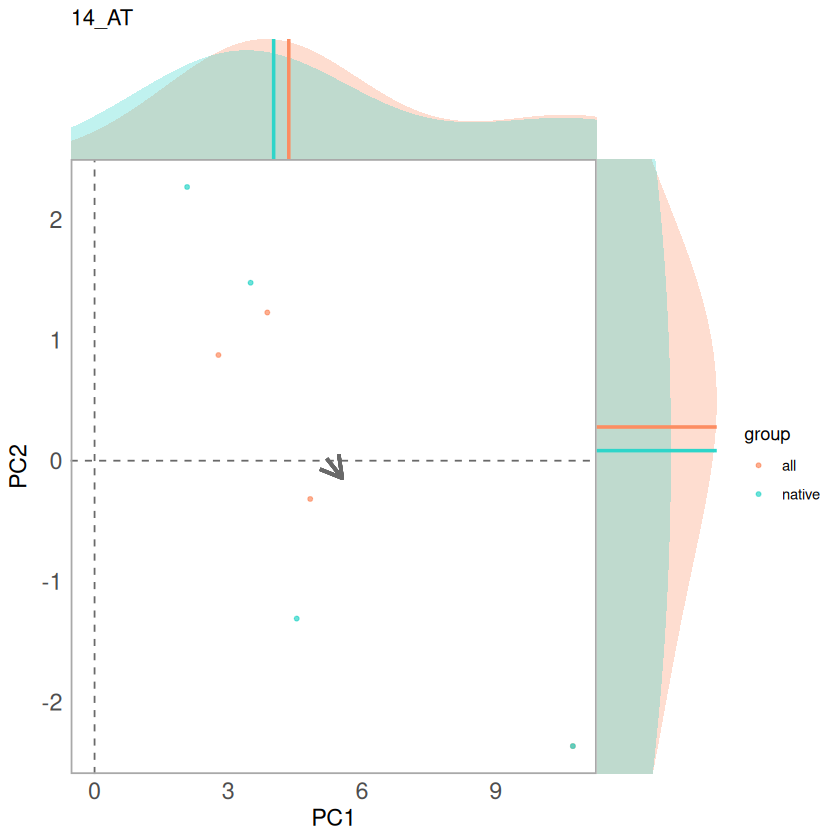

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

Warning message in geom_segment(aes(x = centroid_native$PC1, y = centroid_native$PC2, :
“All aesthetics have length 1, but the data has 14 rows.
ℹ Please consider using `annotate()` or provide this layer with data containing
  a single row.”
Warning message in geom_segment(aes(x = centroid_native$PC1, y = centroid_native$PC2, :
“All aesthetics have length 1, but the data has 14 rows.
ℹ Please consider using `annotate()` or provide this layer with data containing
  a single row.”
Warning message in geom_segment(aes(x = centroid_native$PC1, y = centroid_native$PC2, :
“All aesthetics have length 1, but the data has 14 rows.
ℹ Please consider using `annotate()` or provide this layer with data containing
  a single row.”


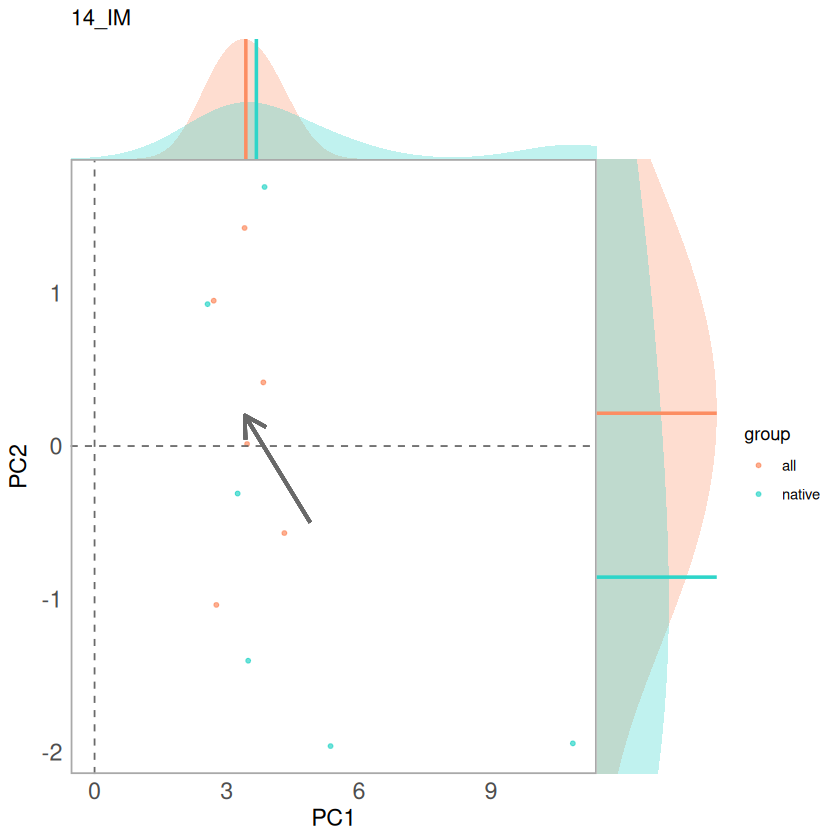

polygon has holes

Warning message in geom_segment(aes(x = centroid_native$PC1, y = centroid_native$PC2, :
“All aesthetics have length 1, but the data has 130 rows.
ℹ Please consider using `annotate()` or provide this layer with data containing
  a single row.”
Warning message in geom_segment(aes(x = centroid_native$PC1, y = centroid_native$PC2, :
“All aesthetics have length 1, but the data has 130 rows.
ℹ Please consider using `annotate()` or provide this layer with data containing
  a single row.”
Warning message in geom_segment(aes(x = centroid_native$PC1, y = centroid_native$PC2, :
“All aesthetics have length 1, but the data has 130 rows.
ℹ Please consider using `annotate()` or provide this layer with data containing
  a single row.”


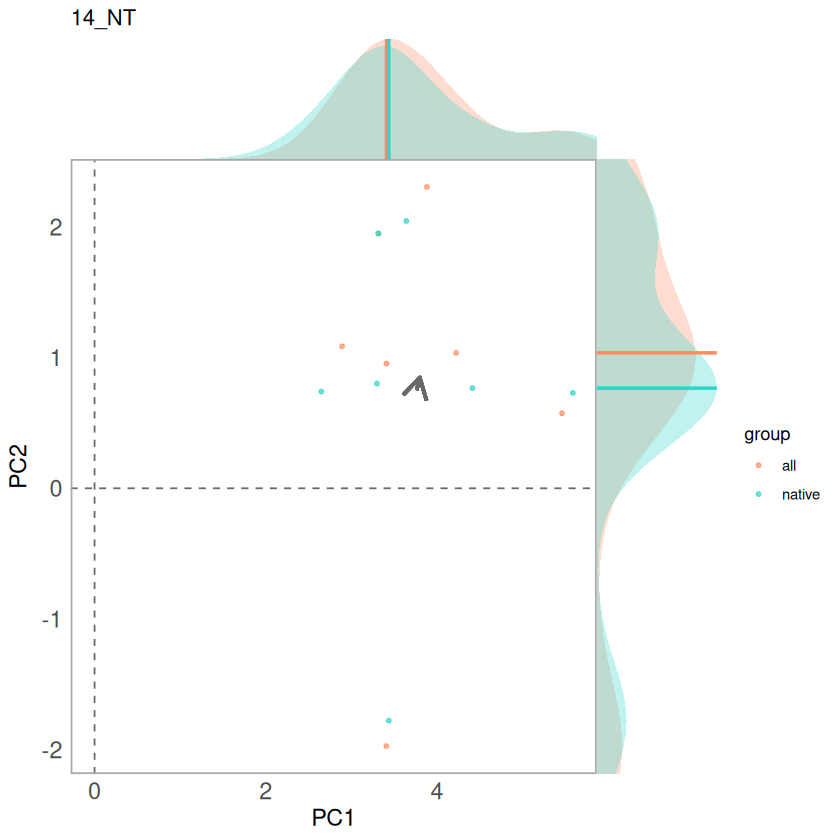

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

Warning message in geom_segment(aes(x = centroid_native$PC1, y = centroid_native$PC2, :
“All aesthetics have length 1, but the data has 398 rows.
ℹ Please consider using `annotate()` or provide this layer with data containing
  a single row.”
Warning message in geom_segment(aes(x = centroid_native$PC1, y = centroid_native$PC2, :
“All aesthetics have length 1, but the data has 398 rows.
ℹ Please consider using `annotate()` or provide this layer with data containing
  a single row.”
Warning message in geom_segment(aes(x = centroid_native$PC1, y = centroid_native$PC2, :
“All aesthetics have length 1, but the data has 398 rows.
ℹ Please consider using `annotate()` or provide this layer with data containing
  a single row.”


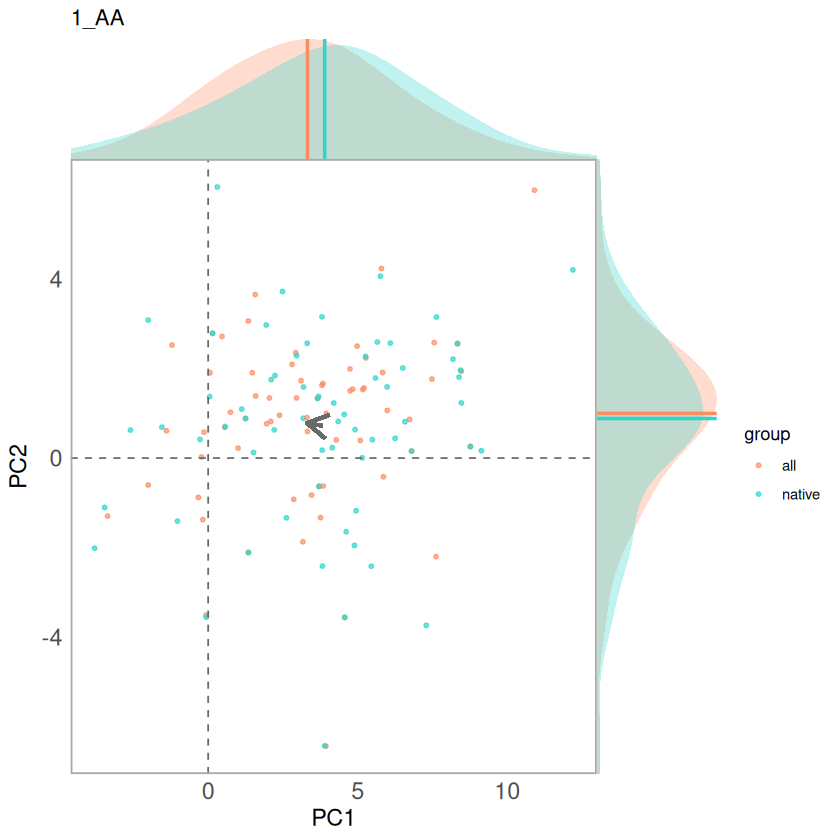

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

Warning message in geom_segment(aes(x = centroid_native$PC1, y = centroid_native$PC2, :
“All aesthetics have length 1, but the data has 784 rows.
ℹ Please consider using `annotate()` or provide this layer with data containing
  a single row.”
Warning message in geom_segment(aes(x = centroid_native$PC1, y = centroid_native$PC2, :
“All aesthetics have length 1, but the data has 784 rows.
ℹ Please consider using `annotate()` or provide this layer with data containing
  a single row.”
Warning message in geom_segment(aes(x = centroid_native$PC1, y = centroid_native$PC2, :
“All aesthetics have length 1, but the data has 784 rows.
ℹ Please consider using `annotate()` or provide this layer with data containing
  a single row.”


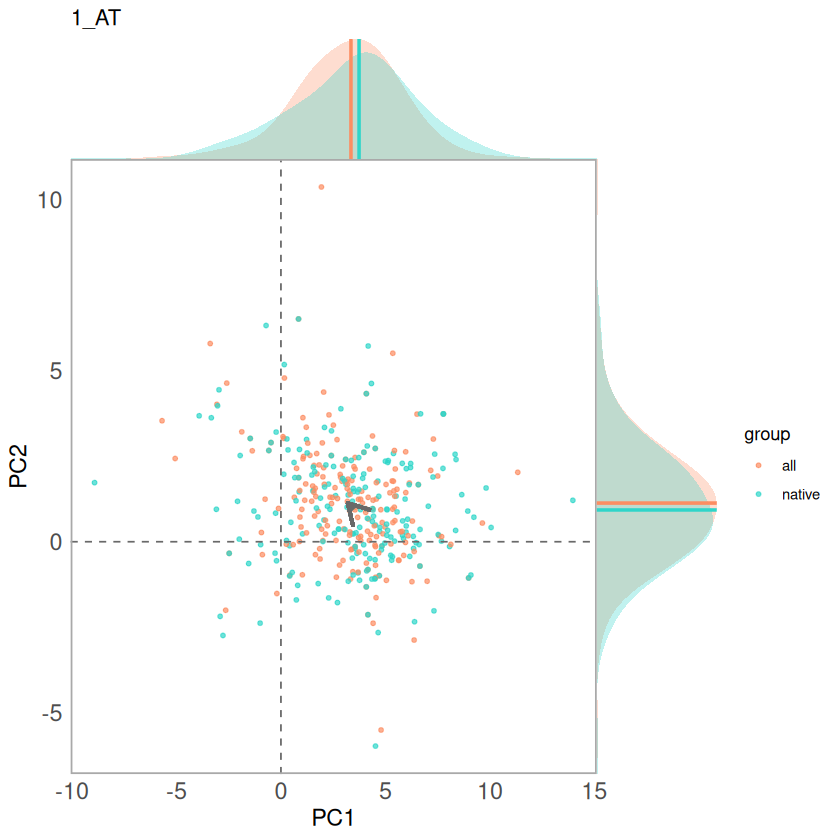

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

Warning message in geom_segment(aes(x = centroid_native$PC1, y = centroid_native$PC2, :
“All aesthetics have length 1, but the data has 1050 rows.
ℹ Please consider using `annotate()` or provide this layer with data containing
  a single row.”
Warning message in geom_segment(aes(x = centroid_native$PC1, y = centroid_native$PC2, :
“All aesthetics have length 1, but the data has 1050 rows.
ℹ Please consider using `annotate()` or provide this layer with data containing
  a single row.”
Warning message in geom_segment(aes(x = centroid_native$PC1, y = centroid_native$PC2, :
“All aesthetics have length 1, but the data has 1050 rows.
ℹ Please consider using `annotate()` or provide this layer with data containing
  a single row.”


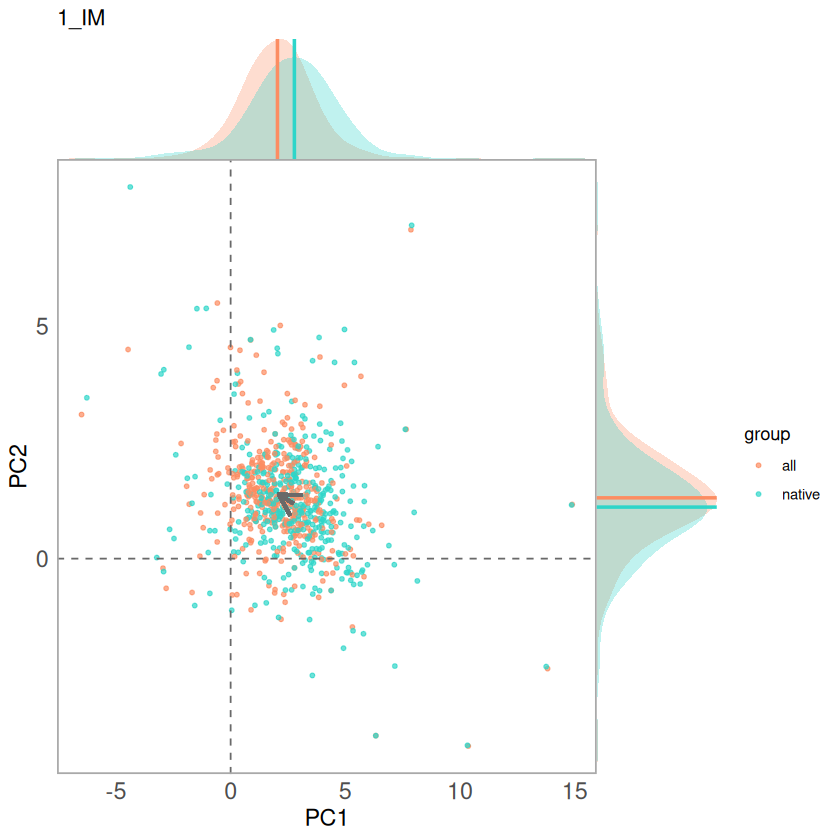

Warning message in geom_segment(aes(x = centroid_native$PC1, y = centroid_native$PC2, :
“All aesthetics have length 1, but the data has 10 rows.
ℹ Please consider using `annotate()` or provide this layer with data containing
  a single row.”
Warning message in geom_segment(aes(x = centroid_native$PC1, y = centroid_native$PC2, :
“All aesthetics have length 1, but the data has 10 rows.
ℹ Please consider using `annotate()` or provide this layer with data containing
  a single row.”
Warning message in geom_segment(aes(x = centroid_native$PC1, y = centroid_native$PC2, :
“All aesthetics have length 1, but the data has 10 rows.
ℹ Please consider using `annotate()` or provide this layer with data containing
  a single row.”


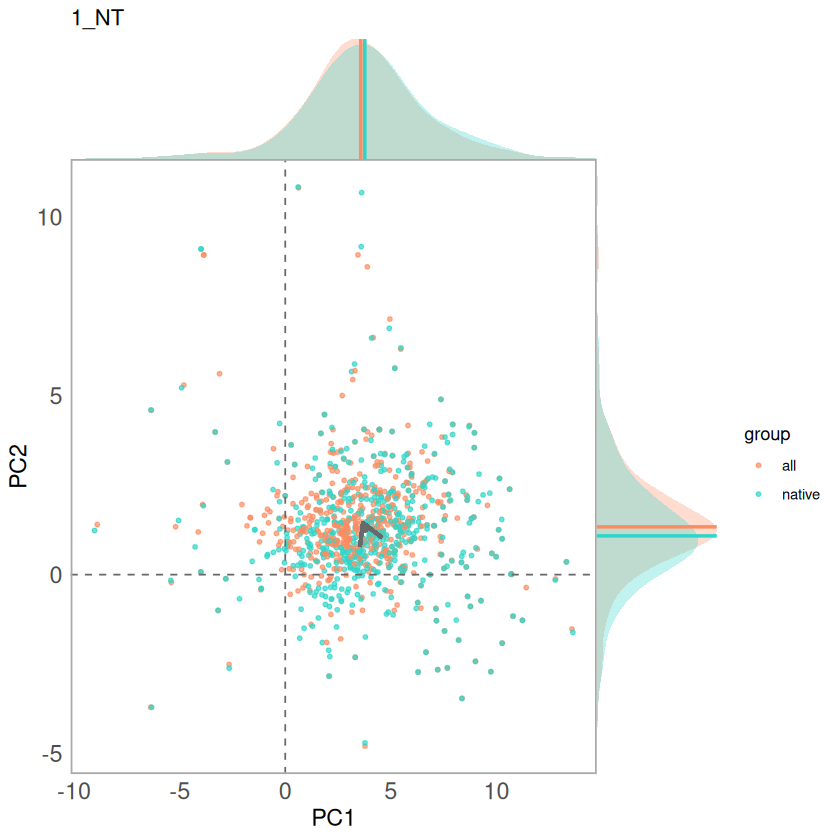

Warning message in geom_segment(aes(x = centroid_native$PC1, y = centroid_native$PC2, :
“All aesthetics have length 1, but the data has 84 rows.
ℹ Please consider using `annotate()` or provide this layer with data containing
  a single row.”
Warning message in geom_segment(aes(x = centroid_native$PC1, y = centroid_native$PC2, :
“All aesthetics have length 1, but the data has 84 rows.
ℹ Please consider using `annotate()` or provide this layer with data containing
  a single row.”
Warning message in geom_segment(aes(x = centroid_native$PC1, y = centroid_native$PC2, :
“All aesthetics have length 1, but the data has 84 rows.
ℹ Please consider using `annotate()` or provide this layer with data containing
  a single row.”


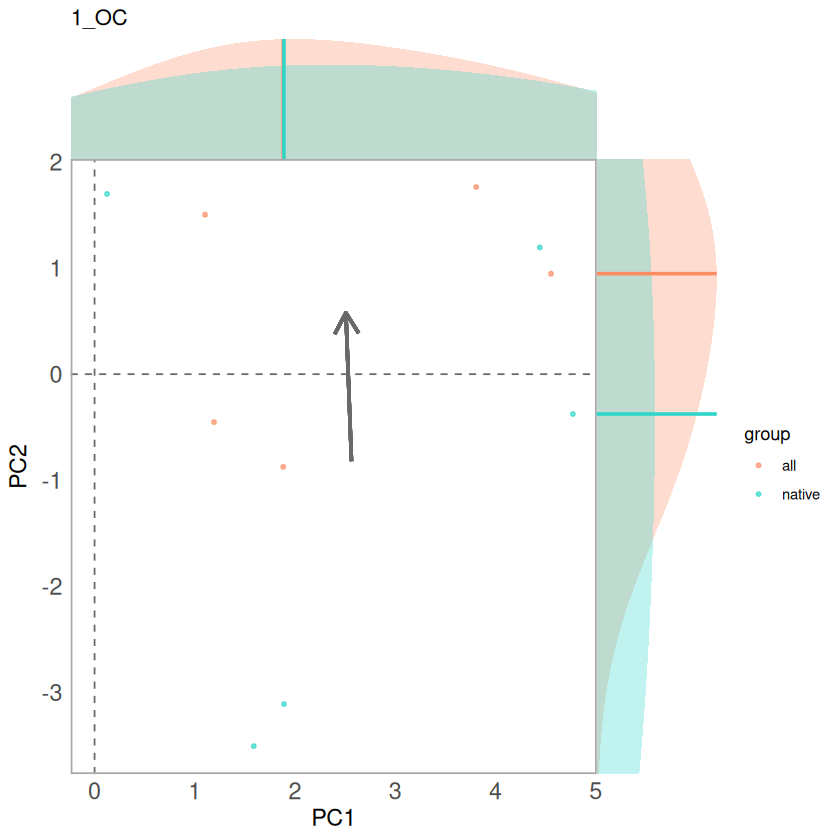

Warning message in geom_segment(aes(x = centroid_native$PC1, y = centroid_native$PC2, :
“All aesthetics have length 1, but the data has 8 rows.
ℹ Please consider using `annotate()` or provide this layer with data containing
  a single row.”
Warning message in geom_segment(aes(x = centroid_native$PC1, y = centroid_native$PC2, :
“All aesthetics have length 1, but the data has 8 rows.
ℹ Please consider using `annotate()` or provide this layer with data containing
  a single row.”
Warning message in geom_segment(aes(x = centroid_native$PC1, y = centroid_native$PC2, :
“All aesthetics have length 1, but the data has 8 rows.
ℹ Please consider using `annotate()` or provide this layer with data containing
  a single row.”


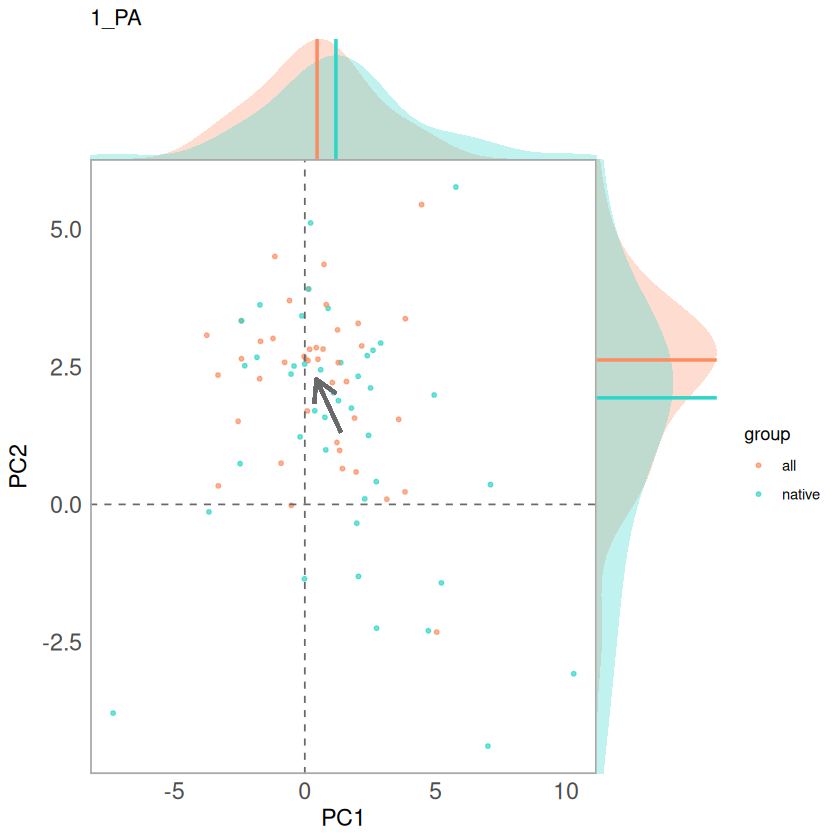

polygon has holes

polygon has holes

Warning message in geom_segment(aes(x = centroid_native$PC1, y = centroid_native$PC2, :
“All aesthetics have length 1, but the data has 32 rows.
ℹ Please consider using `annotate()` or provide this layer with data containing
  a single row.”
Warning message in geom_segment(aes(x = centroid_native$PC1, y = centroid_native$PC2, :
“All aesthetics have length 1, but the data has 32 rows.
ℹ Please consider using `annotate()` or provide this layer with data containing
  a single row.”
Warning message in geom_segment(aes(x = centroid_native$PC1, y = centroid_native$PC2, :
“All aesthetics have length 1, but the data has 32 rows.
ℹ Please consider using `annotate()` or provide this layer with data containing
  a single row.”


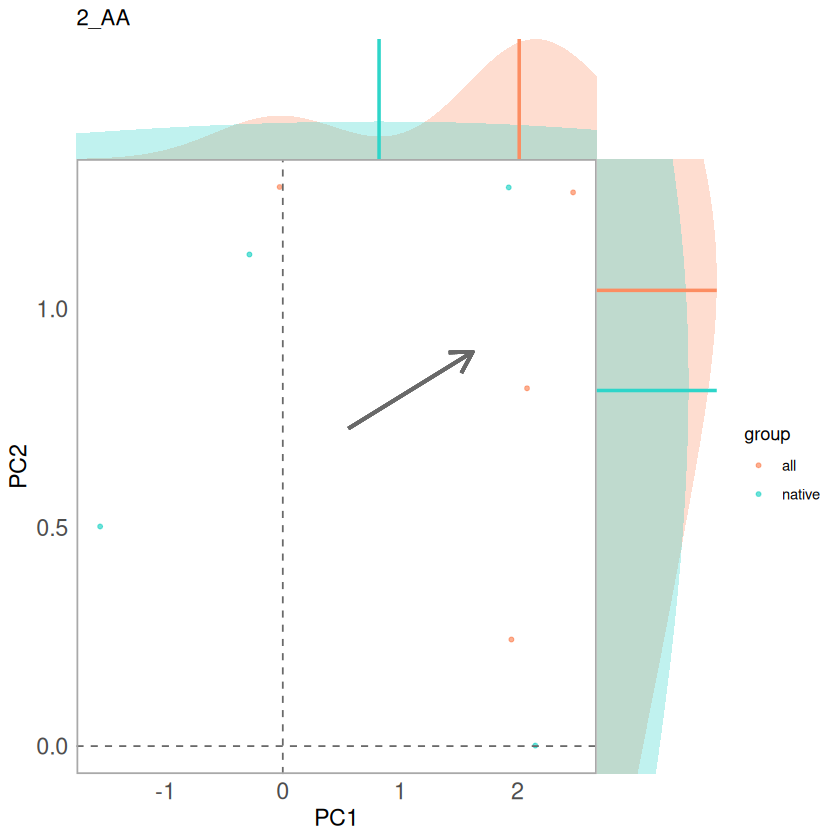

polygon has holes

Warning message in geom_segment(aes(x = centroid_native$PC1, y = centroid_native$PC2, :
“All aesthetics have length 1, but the data has 238 rows.
ℹ Please consider using `annotate()` or provide this layer with data containing
  a single row.”
Warning message in geom_segment(aes(x = centroid_native$PC1, y = centroid_native$PC2, :
“All aesthetics have length 1, but the data has 238 rows.
ℹ Please consider using `annotate()` or provide this layer with data containing
  a single row.”
Warning message in geom_segment(aes(x = centroid_native$PC1, y = centroid_native$PC2, :
“All aesthetics have length 1, but the data has 238 rows.
ℹ Please consider using `annotate()` or provide this layer with data containing
  a single row.”


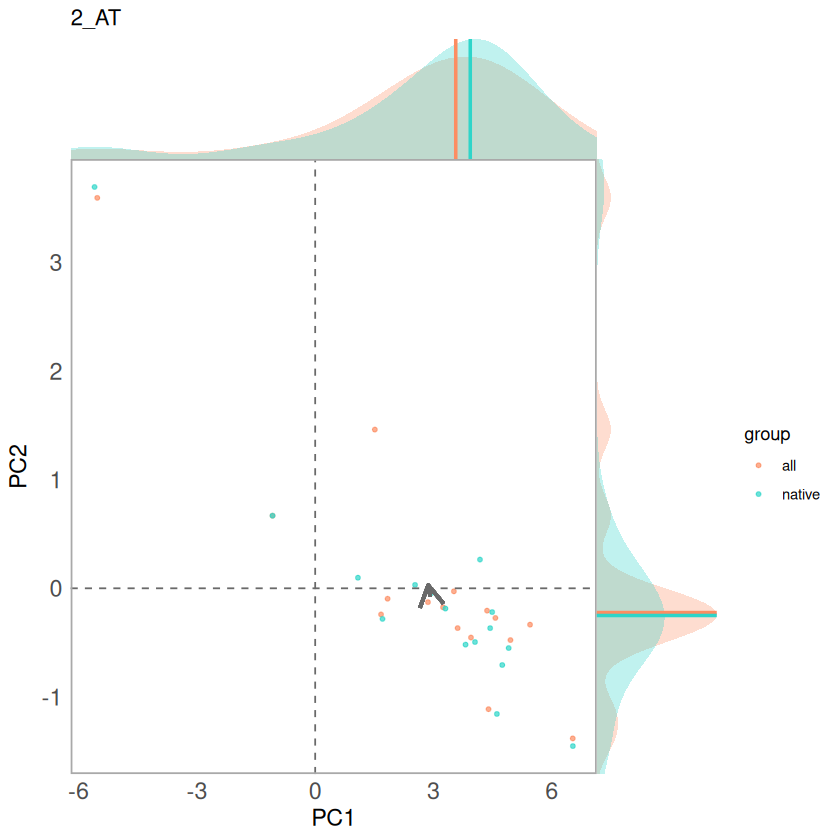

polygon has holes

polygon has holes

Warning message in geom_segment(aes(x = centroid_native$PC1, y = centroid_native$PC2, :
“All aesthetics have length 1, but the data has 8 rows.
ℹ Please consider using `annotate()` or provide this layer with data containing
  a single row.”
Warning message in geom_segment(aes(x = centroid_native$PC1, y = centroid_native$PC2, :
“All aesthetics have length 1, but the data has 8 rows.
ℹ Please consider using `annotate()` or provide this layer with data containing
  a single row.”
Warning message in geom_segment(aes(x = centroid_native$PC1, y = centroid_native$PC2, :
“All aesthetics have length 1, but the data has 8 rows.
ℹ Please consider using `annotate()` or provide this layer with data containing
  a single row.”


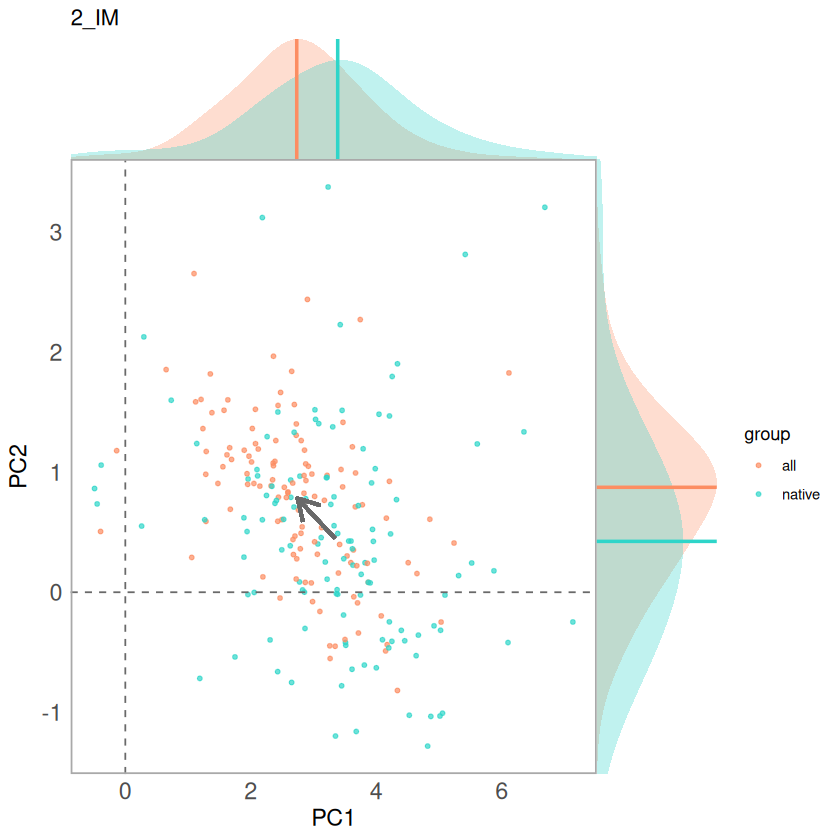

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

Warning message in geom_segment(aes(x = centroid_native$PC1, y = centroid_native$PC2, :
“All aesthetics have length 1, but the data has 172 rows.
ℹ Please consider using `annotate()` or provide this layer with data containing
  a single row.”
Warning message in geom_segment(aes(x = centroid_native$PC1, y = centroid_native$PC2, :
“All aesthetics have length 1, but the data has 172 rows.
ℹ Please consider using `annotate()` or provide this layer with data containing
  a single row.”
Warning message in geom_segment(aes(x = centroid_native$PC1, y = centroid_native$PC2, :
“All aesthetics have length 1, but the data has 172 rows.
ℹ Please consider using `annotate()` or provide this layer with 

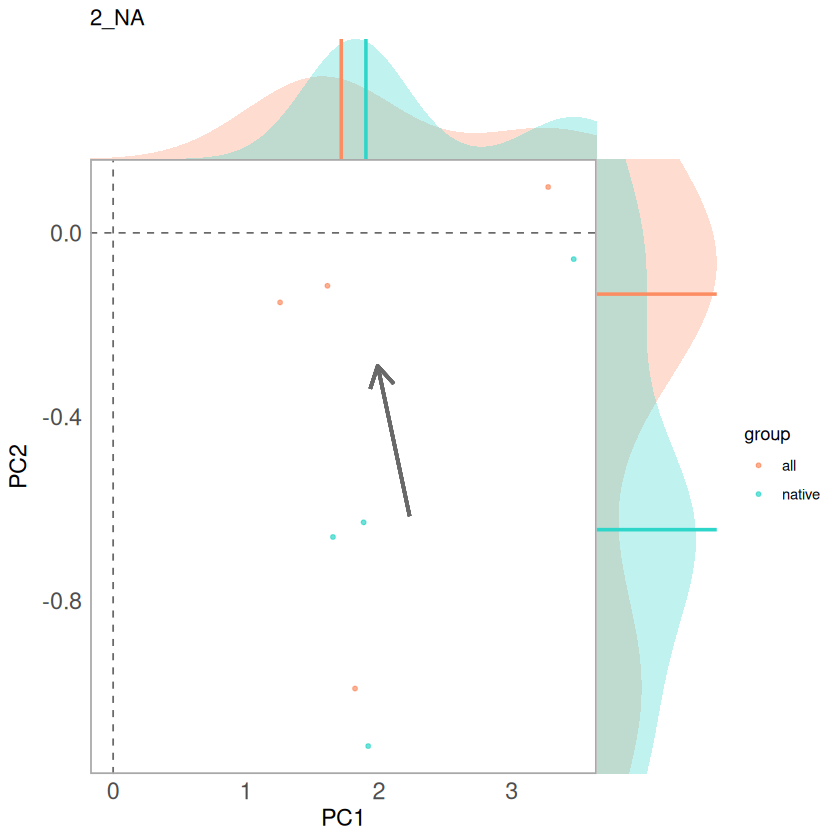

polygon has holes

polygon has holes

Warning message in geom_segment(aes(x = centroid_native$PC1, y = centroid_native$PC2, :
“All aesthetics have length 1, but the data has 2 rows.
ℹ Please consider using `annotate()` or provide this layer with data containing
  a single row.”
Warning message in geom_segment(aes(x = centroid_native$PC1, y = centroid_native$PC2, :
“All aesthetics have length 1, but the data has 2 rows.
ℹ Please consider using `annotate()` or provide this layer with data containing
  a single row.”
Warning message:
“Groups with fewer than two data points have been dropped.”
Warning message:
“Groups with fewer than two data points have been dropped.”
Warning message:
“Removed 2 rows containing missing values or values outside the scale range
(`geom_density()`).”
Warning message:
“Groups with fewer than two data points have been dropped.”
Warning message:
“Groups with fewer than two data points have been dropped.”
Warning message:
“Removed 2 rows containing missing values

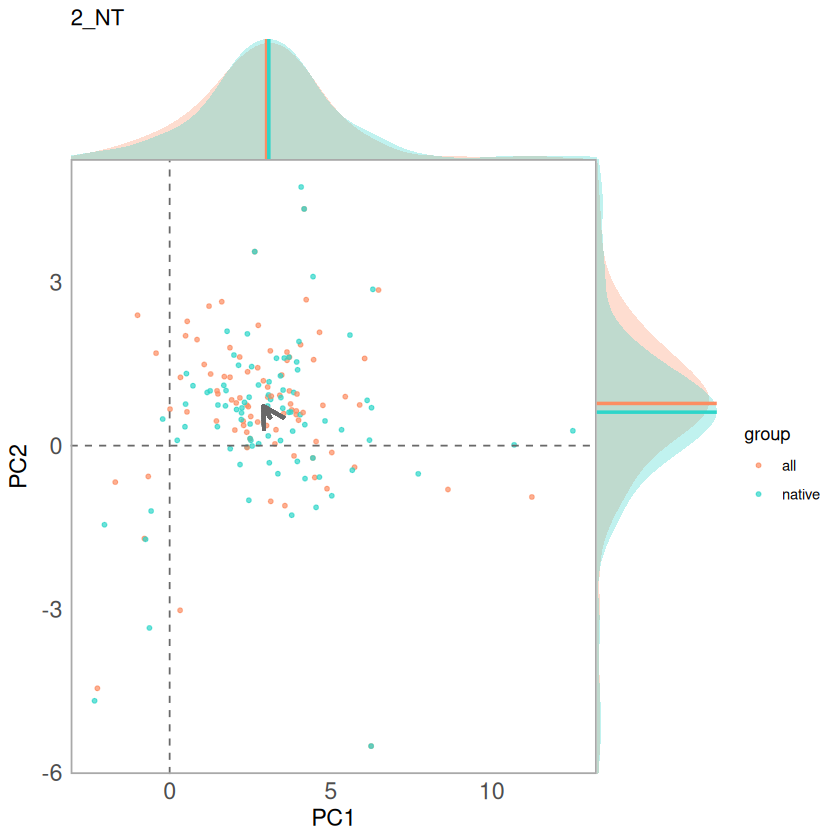

polygon has holes

polygon has holes

polygon has holes

polygon has holes

Warning message in geom_segment(aes(x = centroid_native$PC1, y = centroid_native$PC2, :
“All aesthetics have length 1, but the data has 10 rows.
ℹ Please consider using `annotate()` or provide this layer with data containing
  a single row.”
Warning message in geom_segment(aes(x = centroid_native$PC1, y = centroid_native$PC2, :
“All aesthetics have length 1, but the data has 10 rows.
ℹ Please consider using `annotate()` or provide this layer with data containing
  a single row.”
Warning message in geom_segment(aes(x = centroid_native$PC1, y = centroid_native$PC2, :
“All aesthetics have length 1, but the data has 10 rows.
ℹ Please consider using `annotate()` or provide this layer with data containing
  a single row.”


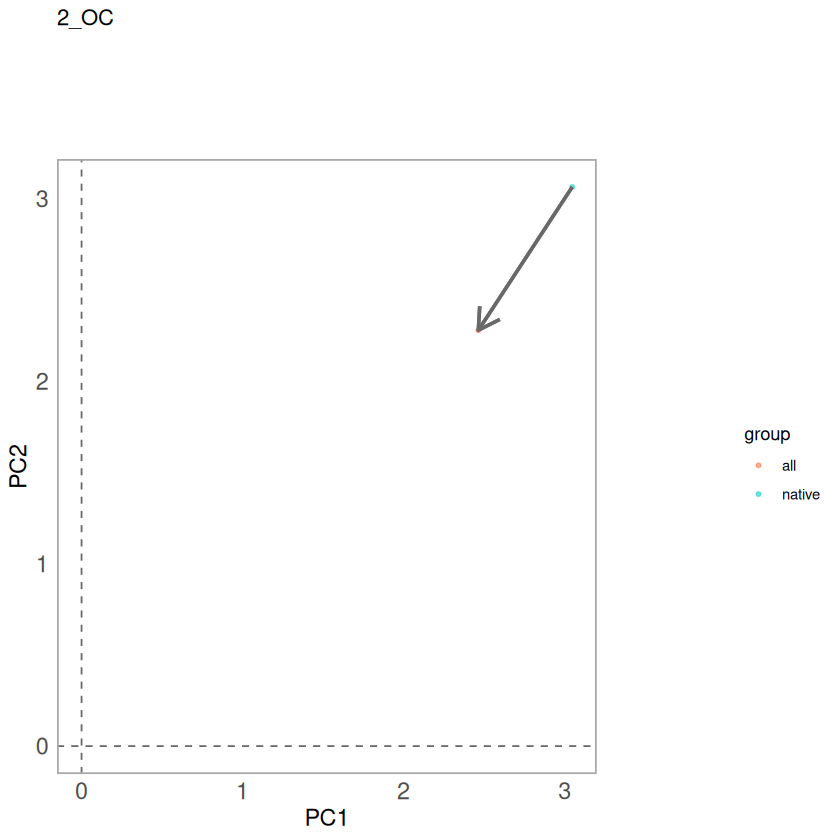

polygon has holes

polygon has holes

polygon has holes

Warning message in geom_segment(aes(x = centroid_native$PC1, y = centroid_native$PC2, :
“All aesthetics have length 1, but the data has 50 rows.
ℹ Please consider using `annotate()` or provide this layer with data containing
  a single row.”
Warning message in geom_segment(aes(x = centroid_native$PC1, y = centroid_native$PC2, :
“All aesthetics have length 1, but the data has 50 rows.
ℹ Please consider using `annotate()` or provide this layer with data containing
  a single row.”
Warning message in geom_segment(aes(x = centroid_native$PC1, y = centroid_native$PC2, :
“All aesthetics have length 1, but the data has 50 rows.
ℹ Please consider using `annotate()` or provide this layer with data containing
  a single row.”


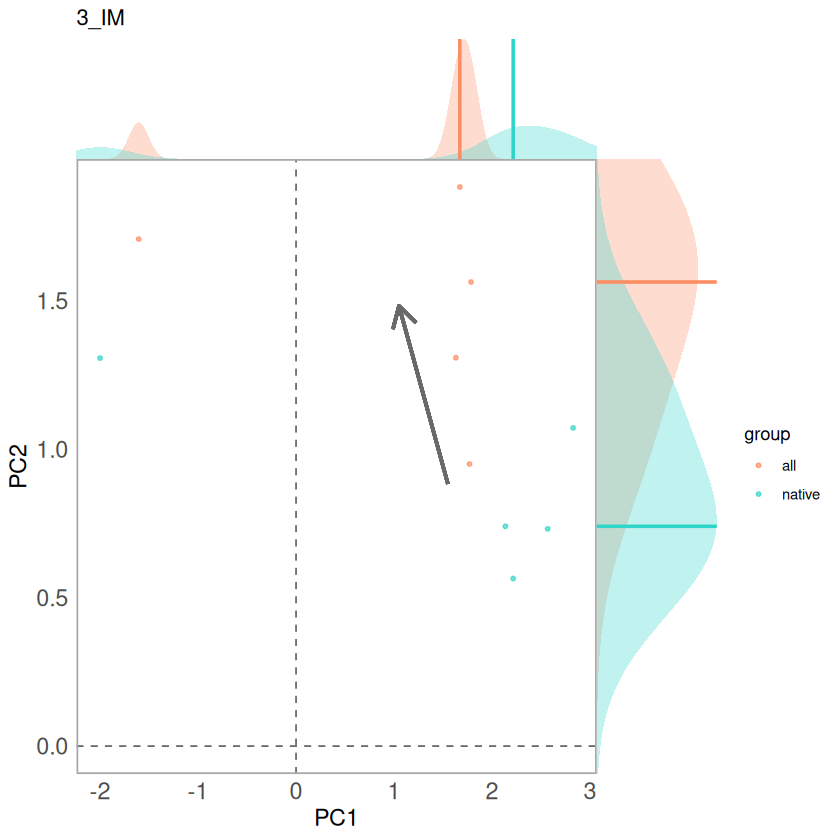

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

Warning message in geom_segment(aes(x = centroid_native$PC1, y = centroid_native$PC2, :
“All aesthetics have length 1, but the data has 40 rows.
ℹ Please consider using `annotate()` or provide this layer with data containing
  a single row.”
Warning message in geom_segment(aes(x = centroid_native$PC1, y = centroid_native$PC2, :
“All aesthetics have length 1, but the data has 40 rows.
ℹ Please consider using `annotate()` or provide this layer with data containing
  a single row.”
Warning message in geom_segment(aes(x = centroid_native$PC1, y = centroid_native$PC2, :
“All aesthetics have length 1, but the data has 40 rows.
ℹ Please consider using `annotate()` or provide this layer with data containing
  a single row.”


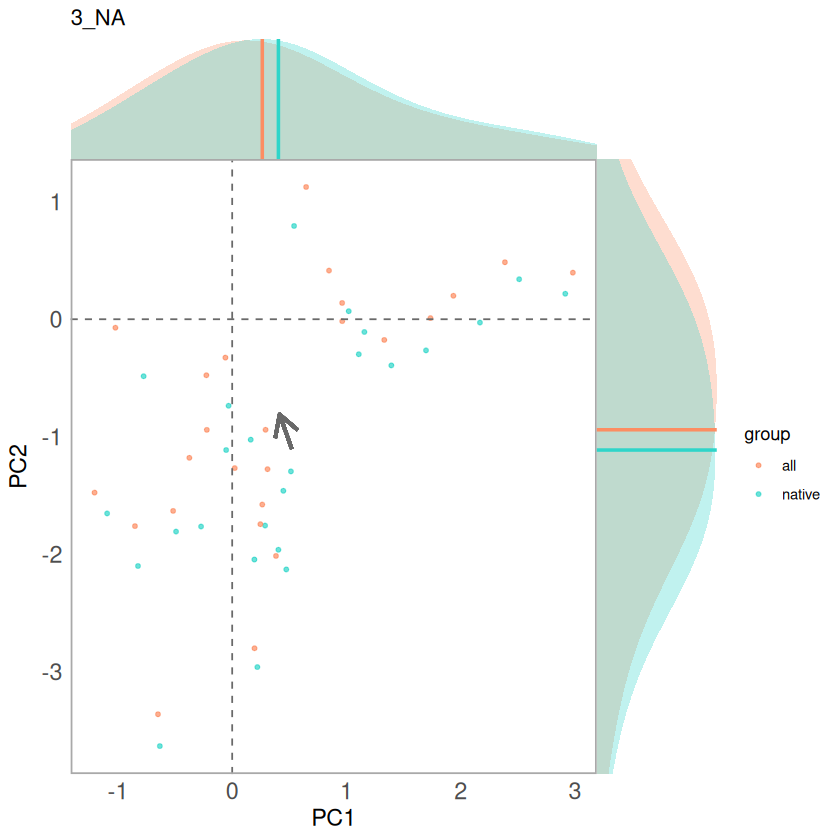

polygon has holes

Warning message in geom_segment(aes(x = centroid_native$PC1, y = centroid_native$PC2, :
“All aesthetics have length 1, but the data has 94 rows.
ℹ Please consider using `annotate()` or provide this layer with data containing
  a single row.”
Warning message in geom_segment(aes(x = centroid_native$PC1, y = centroid_native$PC2, :
“All aesthetics have length 1, but the data has 94 rows.
ℹ Please consider using `annotate()` or provide this layer with data containing
  a single row.”
Warning message in geom_segment(aes(x = centroid_native$PC1, y = centroid_native$PC2, :
“All aesthetics have length 1, but the data has 94 rows.
ℹ Please consider using `annotate()` or provide this layer with data containing
  a single row.”


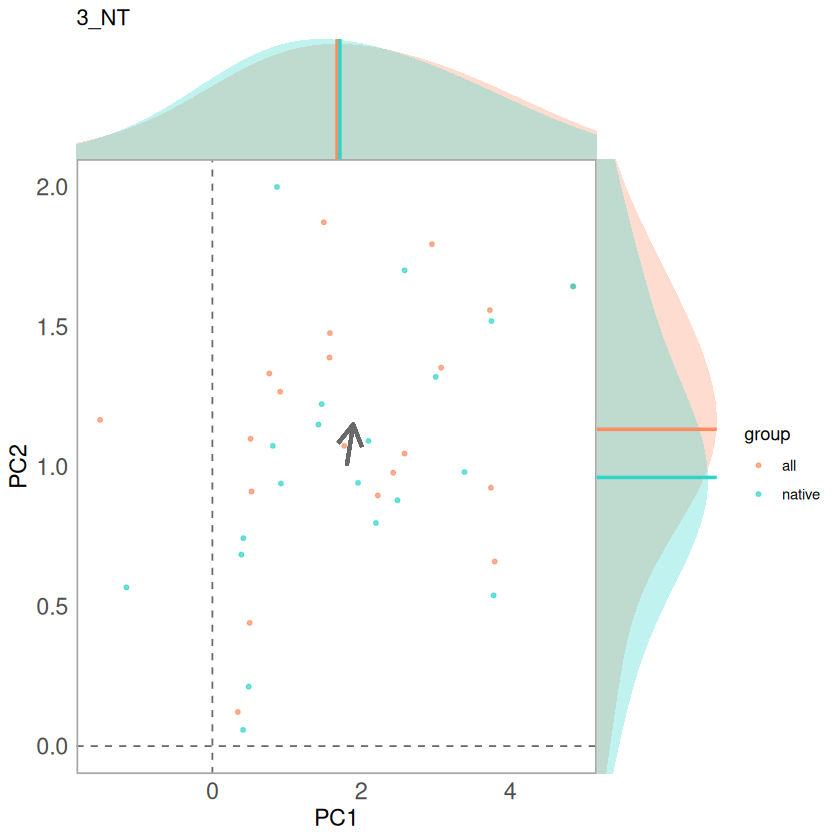

polygon has holes

Warning message in geom_segment(aes(x = centroid_native$PC1, y = centroid_native$PC2, :
“All aesthetics have length 1, but the data has 28 rows.
ℹ Please consider using `annotate()` or provide this layer with data containing
  a single row.”
Warning message in geom_segment(aes(x = centroid_native$PC1, y = centroid_native$PC2, :
“All aesthetics have length 1, but the data has 28 rows.
ℹ Please consider using `annotate()` or provide this layer with data containing
  a single row.”
Warning message in geom_segment(aes(x = centroid_native$PC1, y = centroid_native$PC2, :
“All aesthetics have length 1, but the data has 28 rows.
ℹ Please consider using `annotate()` or provide this layer with data containing
  a single row.”


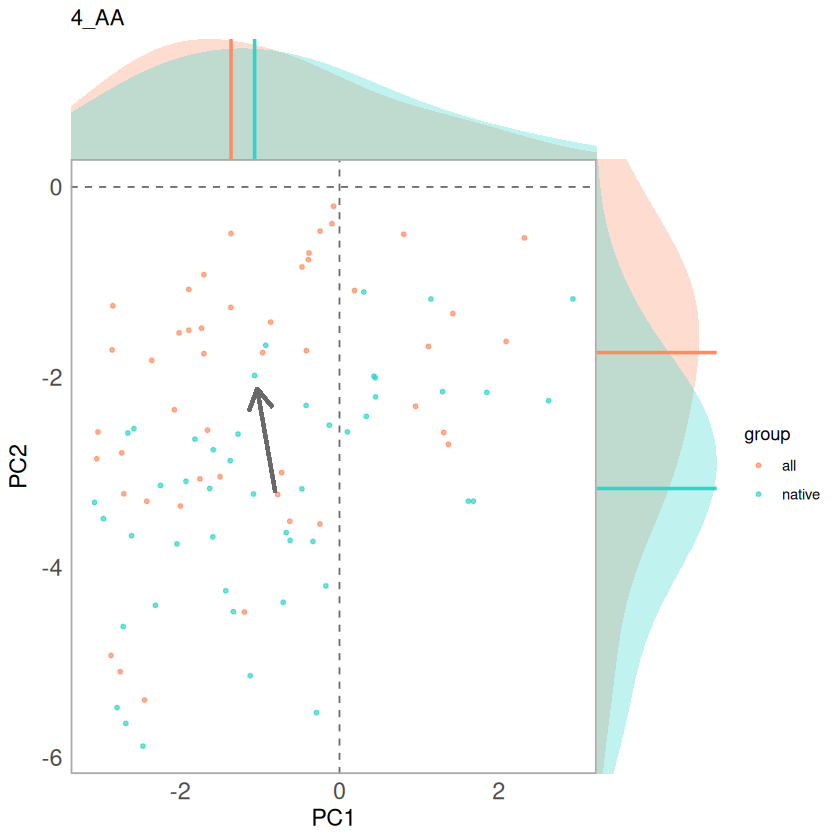

polygon has holes

polygon has holes

Warning message in geom_segment(aes(x = centroid_native$PC1, y = centroid_native$PC2, :
“All aesthetics have length 1, but the data has 432 rows.
ℹ Please consider using `annotate()` or provide this layer with data containing
  a single row.”
Warning message in geom_segment(aes(x = centroid_native$PC1, y = centroid_native$PC2, :
“All aesthetics have length 1, but the data has 432 rows.
ℹ Please consider using `annotate()` or provide this layer with data containing
  a single row.”
Warning message in geom_segment(aes(x = centroid_native$PC1, y = centroid_native$PC2, :
“All aesthetics have length 1, but the data has 432 rows.
ℹ Please consider using `annotate()` or provide this layer with data containing
  a single row.”


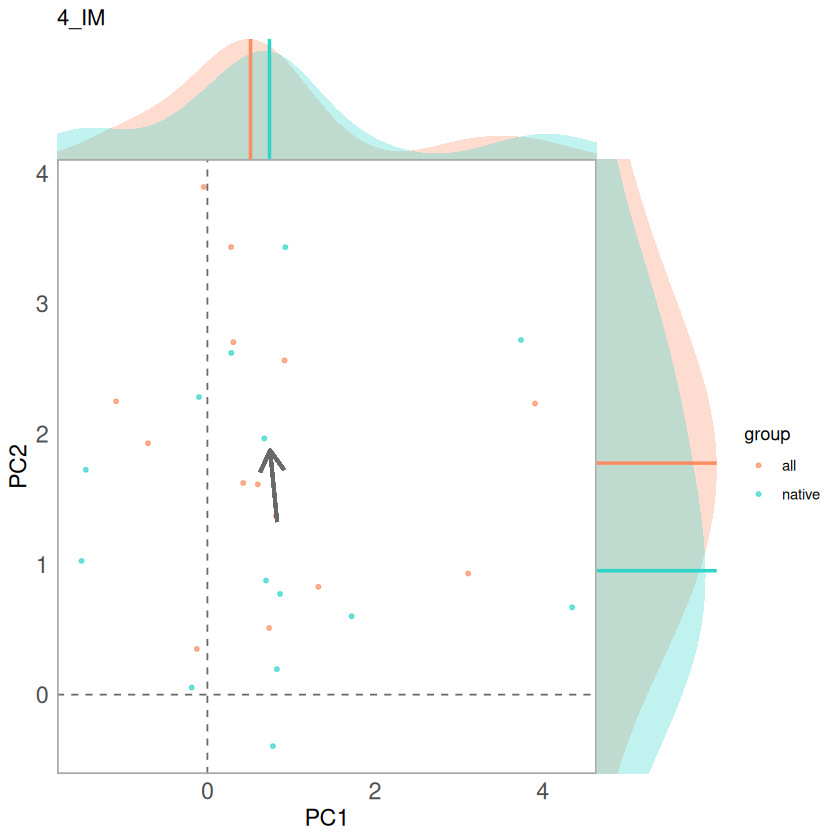

polygon has holes

Warning message in geom_segment(aes(x = centroid_native$PC1, y = centroid_native$PC2, :
“All aesthetics have length 1, but the data has 62 rows.
ℹ Please consider using `annotate()` or provide this layer with data containing
  a single row.”
Warning message in geom_segment(aes(x = centroid_native$PC1, y = centroid_native$PC2, :
“All aesthetics have length 1, but the data has 62 rows.
ℹ Please consider using `annotate()` or provide this layer with data containing
  a single row.”
Warning message in geom_segment(aes(x = centroid_native$PC1, y = centroid_native$PC2, :
“All aesthetics have length 1, but the data has 62 rows.
ℹ Please consider using `annotate()` or provide this layer with data containing
  a single row.”


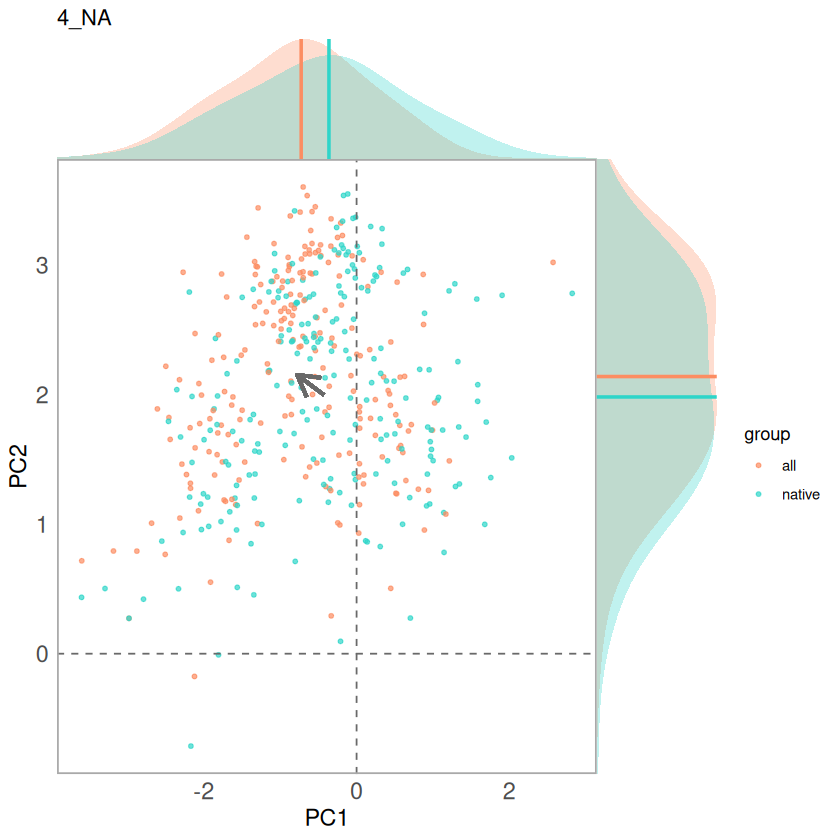

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

Warning message in geom_segment(aes(x = centroid_native$PC1, y = centroid_native$PC2, :
“All aesthetics have length 1, but the data has 1488 rows.
ℹ Please consider using `annotate()` or provide this layer with data containing
  a single row.”
Warning message in geom_segment(aes(x = centroid_native$PC1, y = centroid_native$PC2, :
“All aesthetics have length 1, but the data has 1488 rows.
ℹ Please consider using `annotate()` or provide this layer with data containing
  a single row.”
Warning message in geom_segment(aes(x = centroid_native$PC1, y = centroid_native$PC2, :
“All aesthetics have length 1, but the data has 1488 rows.
ℹ Please consider using `annotate()` or provide this layer with data containing
  a single row.”


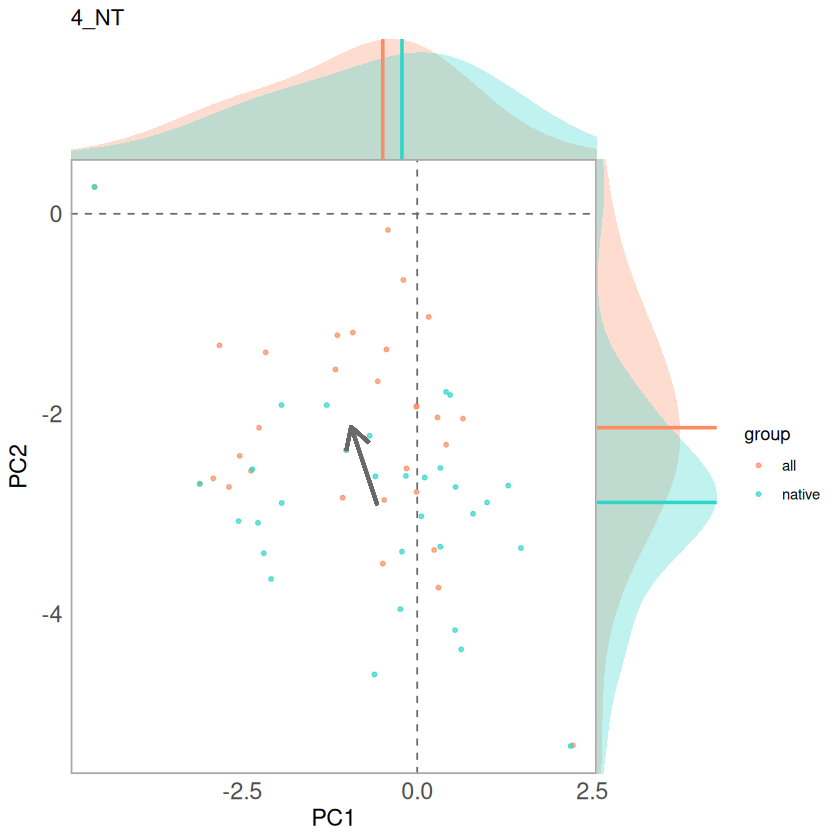

polygon has holes

polygon has holes

polygon has holes

Warning message in geom_segment(aes(x = centroid_native$PC1, y = centroid_native$PC2, :
“All aesthetics have length 1, but the data has 12 rows.
ℹ Please consider using `annotate()` or provide this layer with data containing
  a single row.”
Warning message in geom_segment(aes(x = centroid_native$PC1, y = centroid_native$PC2, :
“All aesthetics have length 1, but the data has 12 rows.
ℹ Please consider using `annotate()` or provide this layer with data containing
  a single row.”
Warning message in geom_segment(aes(x = centroid_native$PC1, y = centroid_native$PC2, :
“All aesthetics have length 1, but the data has 12 rows.
ℹ Please consider using `annotate()` or provide this layer with data containing
  a single row.”


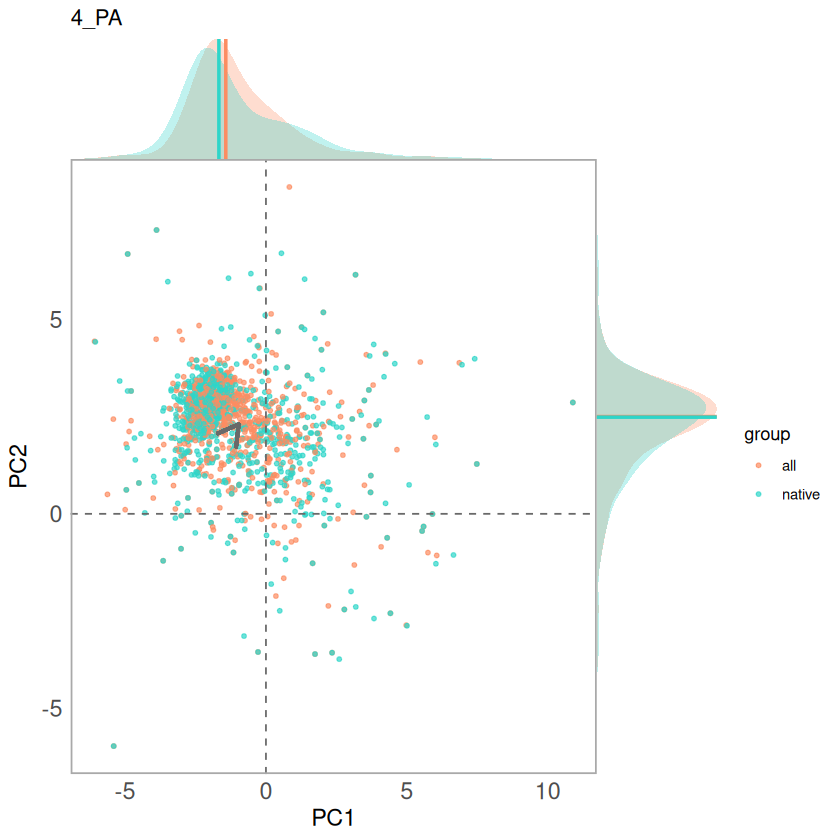

polygon has holes

polygon has holes

Warning message in geom_segment(aes(x = centroid_native$PC1, y = centroid_native$PC2, :
“All aesthetics have length 1, but the data has 380 rows.
ℹ Please consider using `annotate()` or provide this layer with data containing
  a single row.”
Warning message in geom_segment(aes(x = centroid_native$PC1, y = centroid_native$PC2, :
“All aesthetics have length 1, but the data has 380 rows.
ℹ Please consider using `annotate()` or provide this layer with data containing
  a single row.”
Warning message in geom_segment(aes(x = centroid_native$PC1, y = centroid_native$PC2, :
“All aesthetics have length 1, but the data has 380 rows.
ℹ Please consider using `annotate()` or provide this layer with data containing
  a single row.”


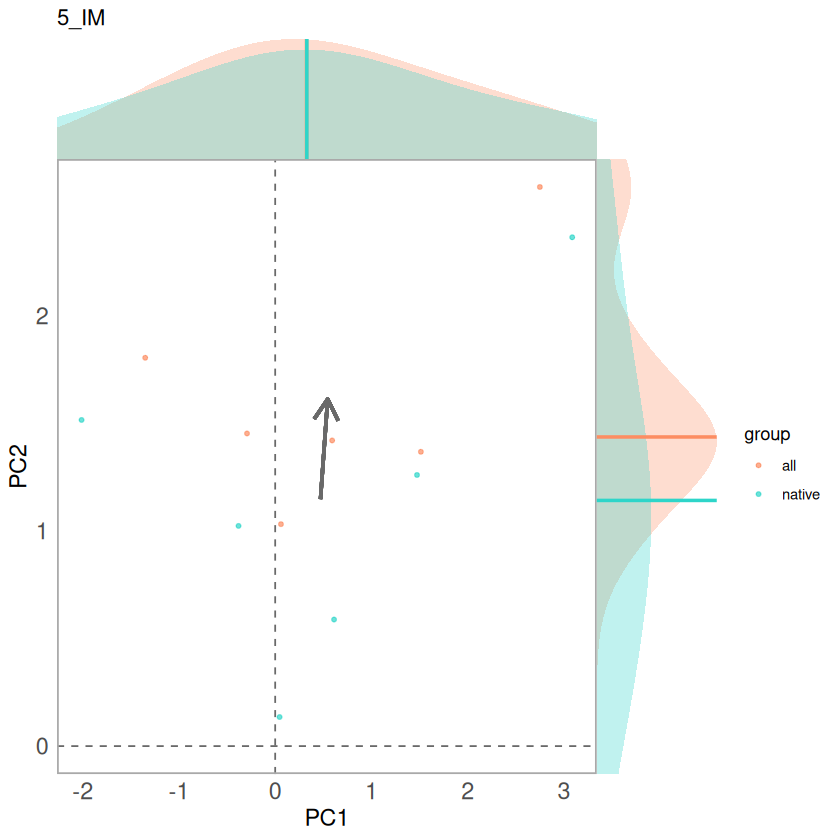

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

Warning message in geom_segment(aes(x = centroid_native$PC1, y = centroid_native$PC2, :
“All aesthetics have length 1, but the data has 224 rows.
ℹ Please consider using `annotate()` or provide this layer with data containing
  a single row.”
Warning message in geom_segment(aes(x = centroid_native$PC1, y = centroid_native$PC2, :
“All aesthetics have length 1, but the data has 224 rows.
ℹ Please consider using `annotate()` or provide this layer with data containing
  a single row.”
Warning message in geom_segment(aes(x = centroid_native$PC1, y = centroid_native$PC2, :
“All aesthetics have length 1, but the data has 224 rows.
ℹ Please consider using `annotate()` or provide this layer with data containing
  a single row.”


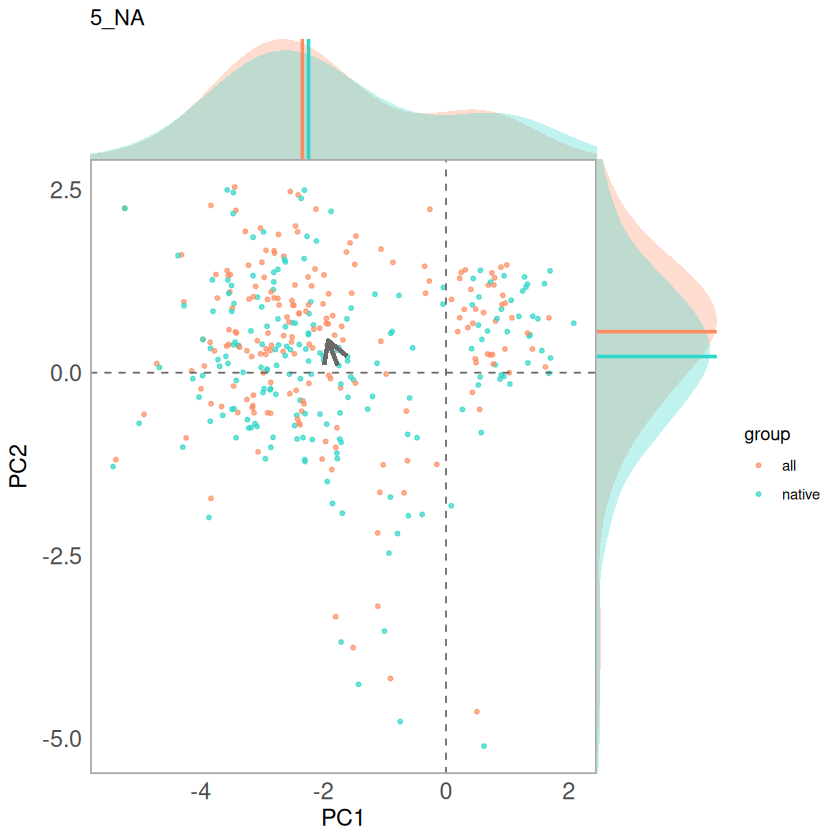

polygon has holes

Warning message in geom_segment(aes(x = centroid_native$PC1, y = centroid_native$PC2, :
“All aesthetics have length 1, but the data has 606 rows.
ℹ Please consider using `annotate()` or provide this layer with data containing
  a single row.”
Warning message in geom_segment(aes(x = centroid_native$PC1, y = centroid_native$PC2, :
“All aesthetics have length 1, but the data has 606 rows.
ℹ Please consider using `annotate()` or provide this layer with data containing
  a single row.”
Warning message in geom_segment(aes(x = centroid_native$PC1, y = centroid_native$PC2, :
“All aesthetics have length 1, but the data has 606 rows.
ℹ Please consider using `annotate()` or provide this layer with data containing
  a single row.”


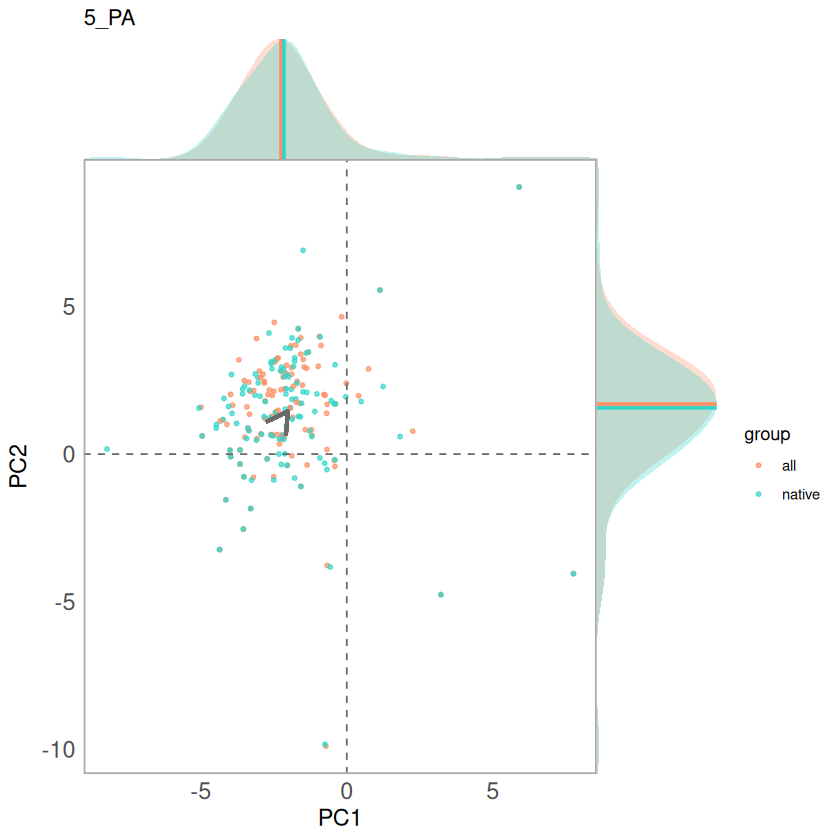

polygon has holes

polygon has holes

polygon has holes

Warning message in geom_segment(aes(x = centroid_native$PC1, y = centroid_native$PC2, :
“All aesthetics have length 1, but the data has 1122 rows.
ℹ Please consider using `annotate()` or provide this layer with data containing
  a single row.”
Warning message in geom_segment(aes(x = centroid_native$PC1, y = centroid_native$PC2, :
“All aesthetics have length 1, but the data has 1122 rows.
ℹ Please consider using `annotate()` or provide this layer with data containing
  a single row.”
Warning message in geom_segment(aes(x = centroid_native$PC1, y = centroid_native$PC2, :
“All aesthetics have length 1, but the data has 1122 rows.
ℹ Please consider using `annotate()` or provide this layer with data containing
  a single row.”


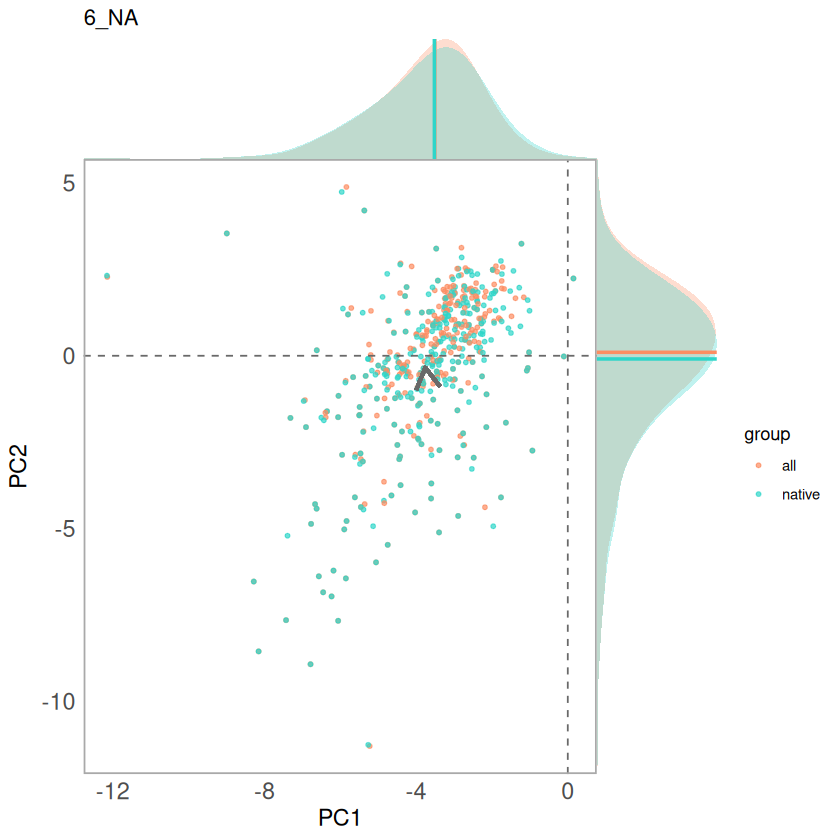

Warning message in geom_segment(aes(x = centroid_native$PC1, y = centroid_native$PC2, :
“All aesthetics have length 1, but the data has 316 rows.
ℹ Please consider using `annotate()` or provide this layer with data containing
  a single row.”
Warning message in geom_segment(aes(x = centroid_native$PC1, y = centroid_native$PC2, :
“All aesthetics have length 1, but the data has 316 rows.
ℹ Please consider using `annotate()` or provide this layer with data containing
  a single row.”
Warning message in geom_segment(aes(x = centroid_native$PC1, y = centroid_native$PC2, :
“All aesthetics have length 1, but the data has 316 rows.
ℹ Please consider using `annotate()` or provide this layer with data containing
  a single row.”


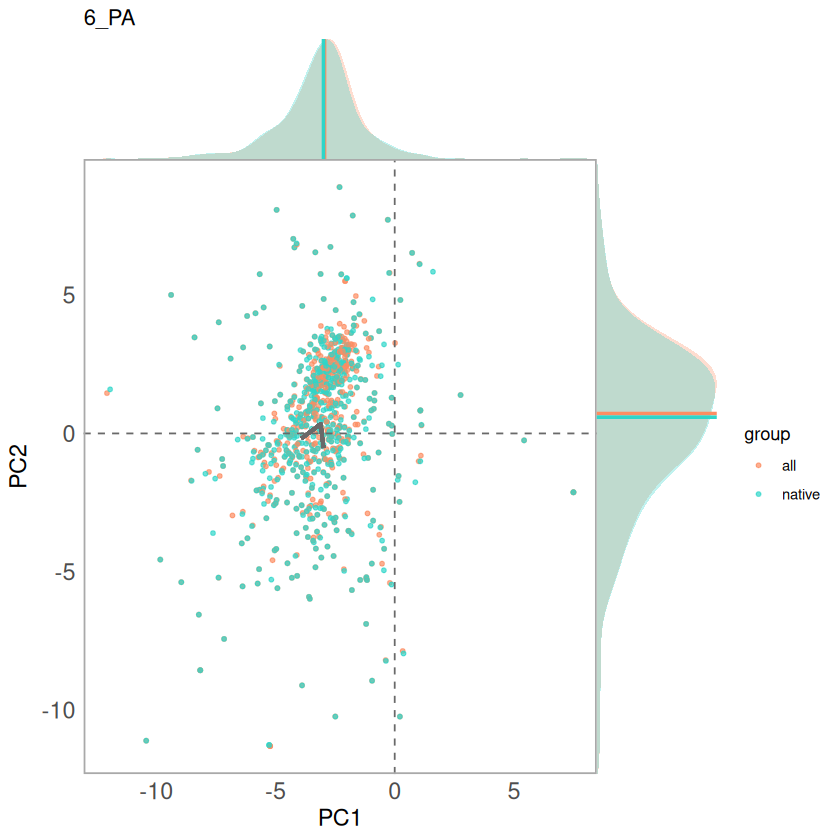

polygon has holes

polygon has holes

Warning message in geom_segment(aes(x = centroid_native$PC1, y = centroid_native$PC2, :
“All aesthetics have length 1, but the data has 1160 rows.
ℹ Please consider using `annotate()` or provide this layer with data containing
  a single row.”
Warning message in geom_segment(aes(x = centroid_native$PC1, y = centroid_native$PC2, :
“All aesthetics have length 1, but the data has 1160 rows.
ℹ Please consider using `annotate()` or provide this layer with data containing
  a single row.”
Warning message in geom_segment(aes(x = centroid_native$PC1, y = centroid_native$PC2, :
“All aesthetics have length 1, but the data has 1160 rows.
ℹ Please consider using `annotate()` or provide this layer with data containing
  a single row.”


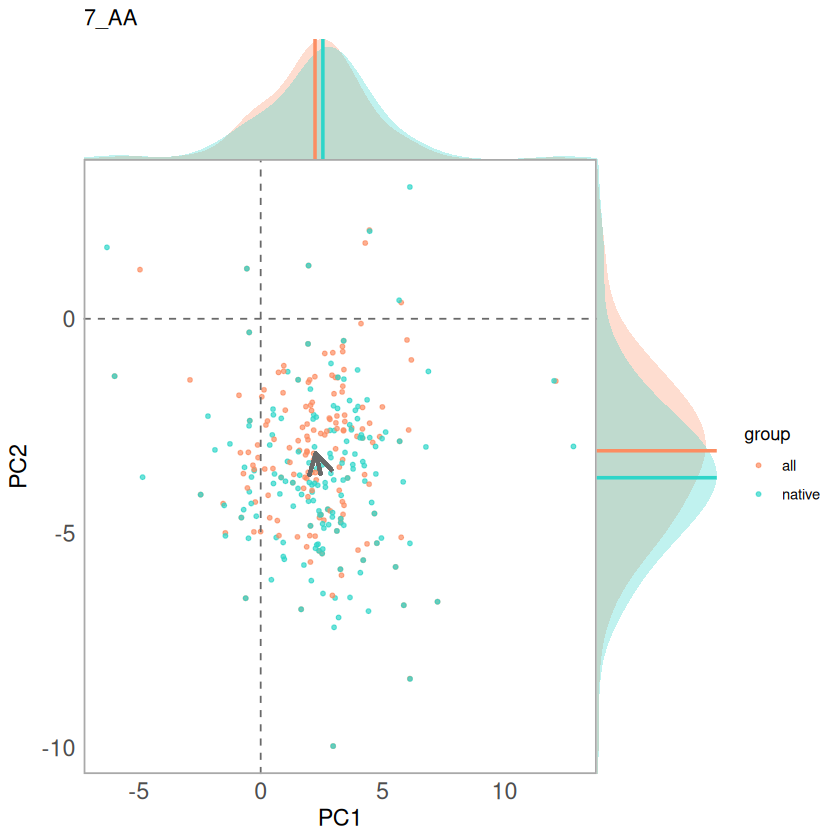

Warning message in geom_segment(aes(x = centroid_native$PC1, y = centroid_native$PC2, :
“All aesthetics have length 1, but the data has 2 rows.
ℹ Please consider using `annotate()` or provide this layer with data containing
  a single row.”
Warning message in geom_segment(aes(x = centroid_native$PC1, y = centroid_native$PC2, :
“All aesthetics have length 1, but the data has 2 rows.
ℹ Please consider using `annotate()` or provide this layer with data containing
  a single row.”
Warning message:
“Groups with fewer than two data points have been dropped.”
Warning message:
“Groups with fewer than two data points have been dropped.”
Warning message:
“Removed 2 rows containing missing values or values outside the scale range
(`geom_density()`).”
Warning message:
“Groups with fewer than two data points have been dropped.”
Warning message:
“Groups with fewer than two data points have been dropped.”
Warning message:
“Removed 2 rows containing missing values or values outside the scale range
(`g

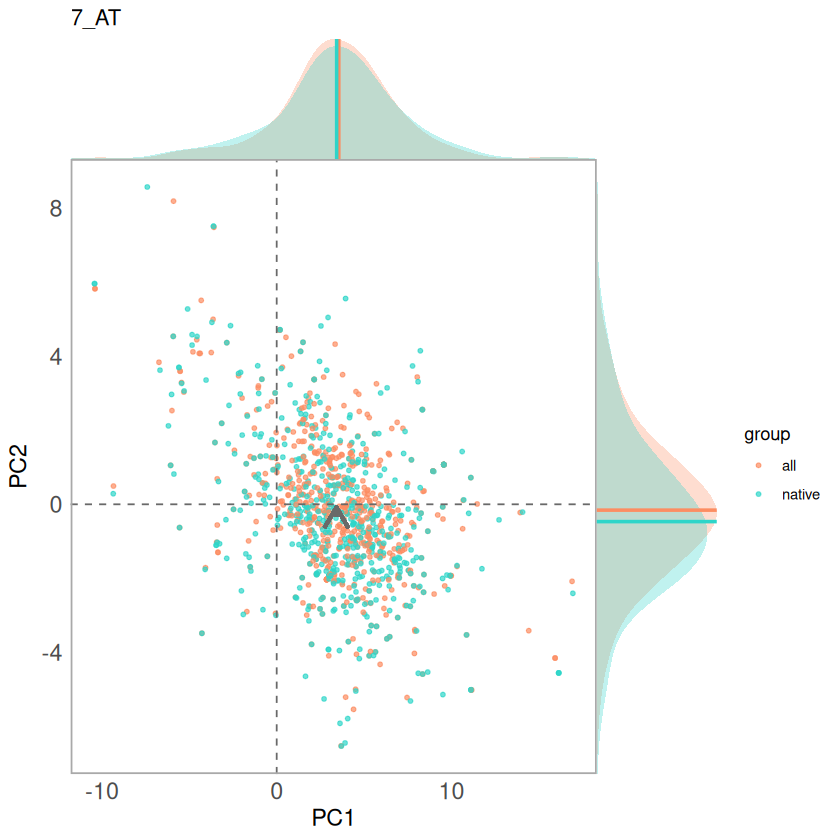

Warning message in geom_segment(aes(x = centroid_native$PC1, y = centroid_native$PC2, :
“All aesthetics have length 1, but the data has 12 rows.
ℹ Please consider using `annotate()` or provide this layer with data containing
  a single row.”
Warning message in geom_segment(aes(x = centroid_native$PC1, y = centroid_native$PC2, :
“All aesthetics have length 1, but the data has 12 rows.
ℹ Please consider using `annotate()` or provide this layer with data containing
  a single row.”
Warning message in geom_segment(aes(x = centroid_native$PC1, y = centroid_native$PC2, :
“All aesthetics have length 1, but the data has 12 rows.
ℹ Please consider using `annotate()` or provide this layer with data containing
  a single row.”


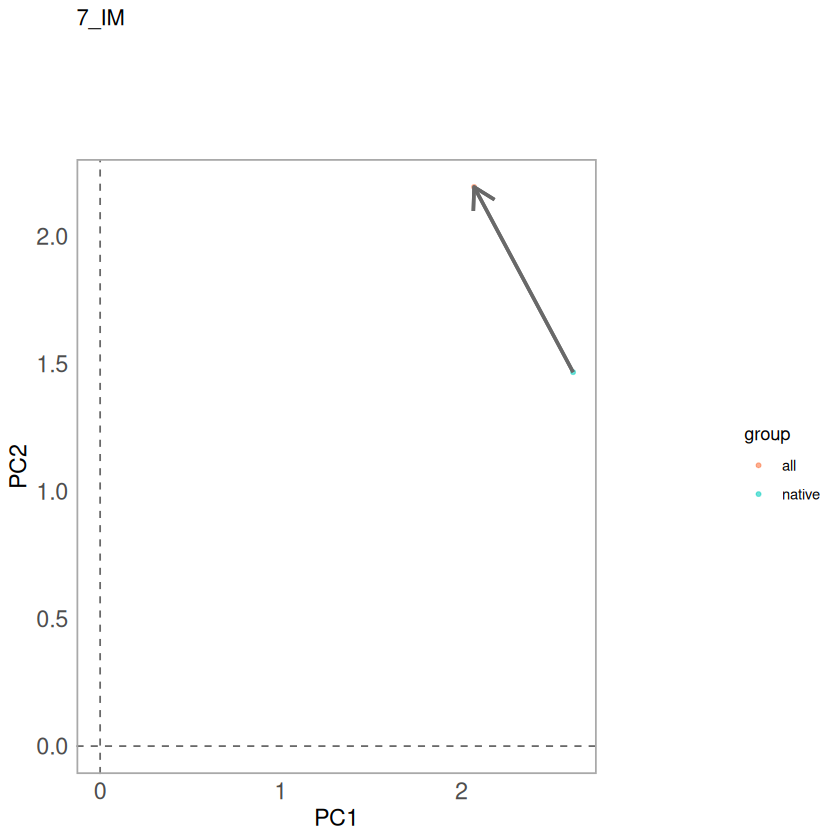

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

Warning message in geom_segment(aes(x = centroid_native$PC1, y = centroid_native$PC2, :
“All aesthetics have length 1, but the data has 582 rows.
ℹ Please consider using `annotate()` or provide this layer with data containing
  a single row.”
Warning message in geom_segment(aes(x = centroid_native$PC1, y = centroid_native$PC2, :
“All aesthetics have length 1, but the data has 582 rows.
ℹ Please consider using `annotate()` or provide this layer with data containing
  a single row.”
Warning message in geom_segment(aes(x = centroid_native$PC1, y = centroid_native$PC2, :
“All aesthetics have length 1, but the data has 582 rows.
ℹ Please consider using `annotate()` or provide this layer with data containing
  a single row.”


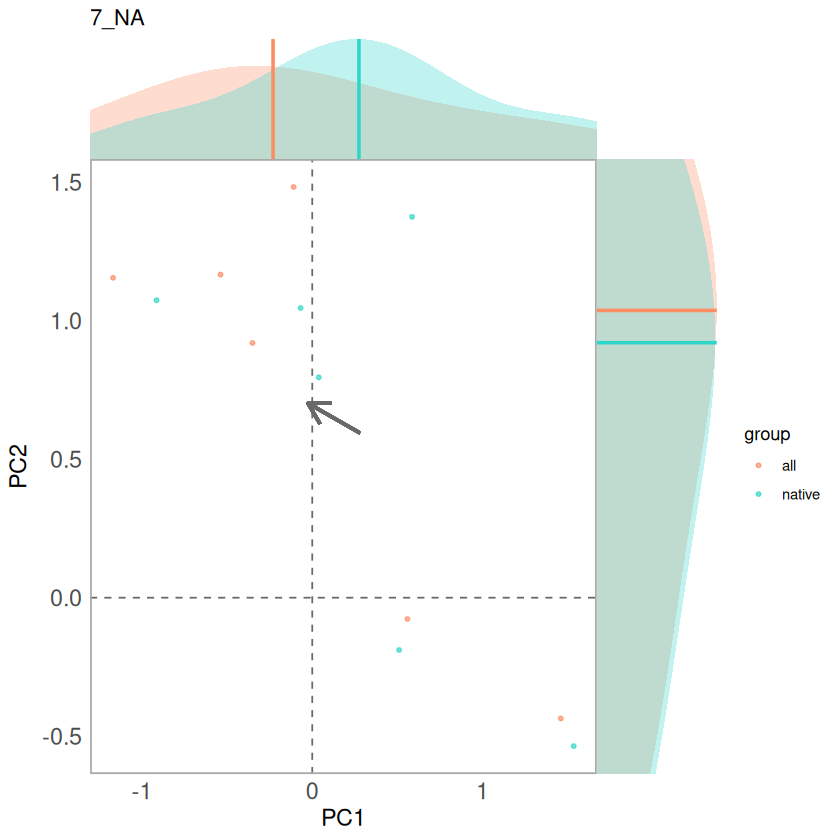

polygon has holes

polygon has holes

polygon has holes

Warning message:
“No shared levels found between `names(values)` of the manual scale and the
data's colour values.”
Warning message:
“No shared levels found between `names(values)` of the manual scale and the
data's colour values.”
Warning message:
“No shared levels found between `names(values)` of the manual scale and the
data's fill values.”
Warning message:
“No shared levels found between `names(values)` of the manual scale and the
data's colour values.”
Warning message:
“No shared levels found between `names(values)` of the manual scale and the
data's fill values.”
Warning message:
“No shared levels found between `names(values)` of the manual scale and the
data's colour values.”
Warning message:
“No shared levels found between `names(values)` of the manual scale and the
data's colour values.”


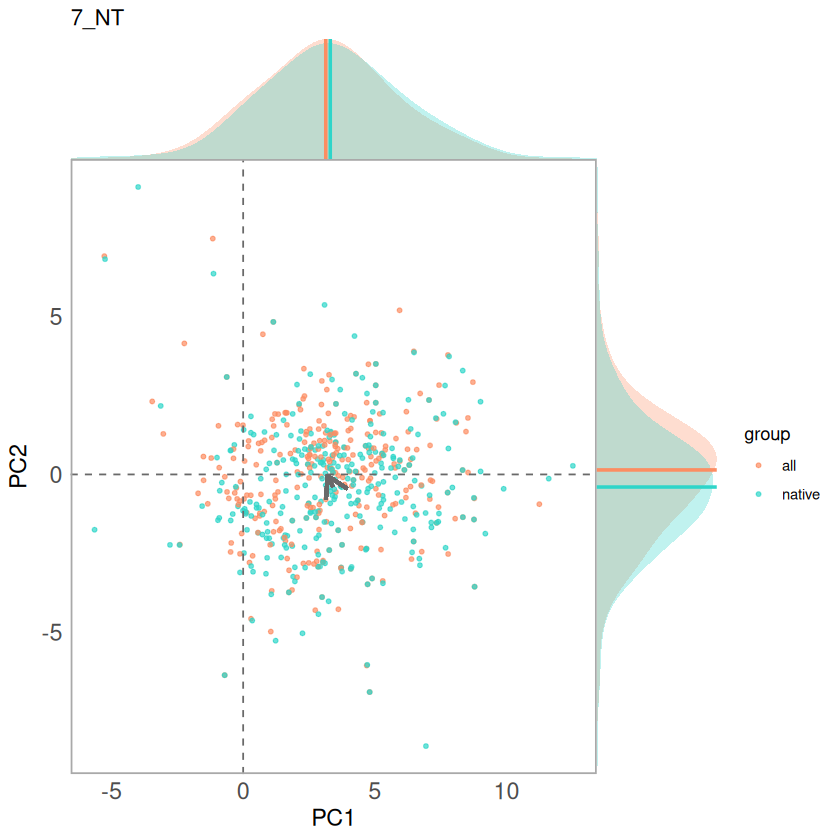

polygon has holes

Warning message in geom_segment(aes(x = centroid_native$PC1, y = centroid_native$PC2, :
“All aesthetics have length 1, but the data has 92 rows.
ℹ Please consider using `annotate()` or provide this layer with data containing
  a single row.”
Warning message in geom_segment(aes(x = centroid_native$PC1, y = centroid_native$PC2, :
“All aesthetics have length 1, but the data has 92 rows.
ℹ Please consider using `annotate()` or provide this layer with data containing
  a single row.”
Warning message in geom_segment(aes(x = centroid_native$PC1, y = centroid_native$PC2, :
“All aesthetics have length 1, but the data has 92 rows.
ℹ Please consider using `annotate()` or provide this layer with data containing
  a single row.”


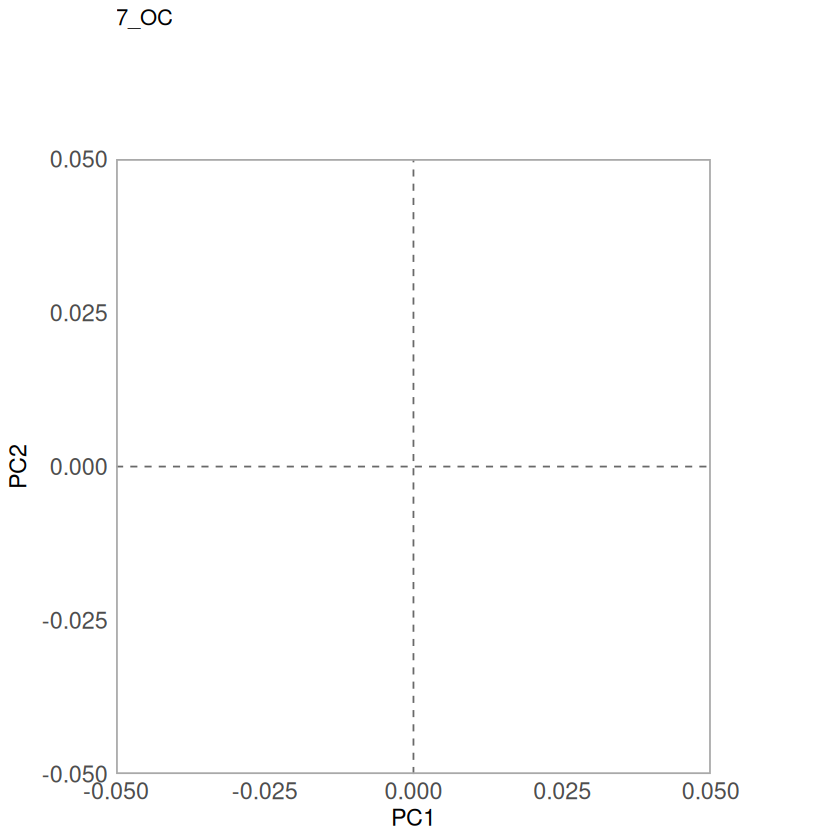

Warning message in geom_segment(aes(x = centroid_native$PC1, y = centroid_native$PC2, :
“All aesthetics have length 1, but the data has 4 rows.
ℹ Please consider using `annotate()` or provide this layer with data containing
  a single row.”
Warning message in geom_segment(aes(x = centroid_native$PC1, y = centroid_native$PC2, :
“All aesthetics have length 1, but the data has 4 rows.
ℹ Please consider using `annotate()` or provide this layer with data containing
  a single row.”
Warning message in geom_segment(aes(x = centroid_native$PC1, y = centroid_native$PC2, :
“All aesthetics have length 1, but the data has 4 rows.
ℹ Please consider using `annotate()` or provide this layer with data containing
  a single row.”


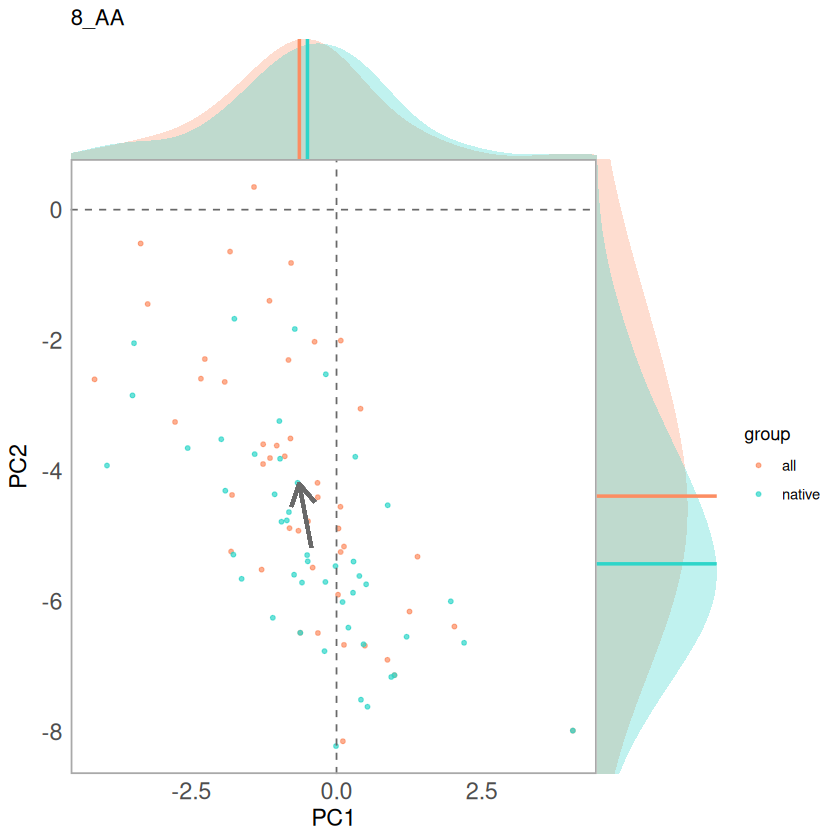

polygon has holes

polygon has holes

Warning message in geom_segment(aes(x = centroid_native$PC1, y = centroid_native$PC2, :
“All aesthetics have length 1, but the data has 482 rows.
ℹ Please consider using `annotate()` or provide this layer with data containing
  a single row.”
Warning message in geom_segment(aes(x = centroid_native$PC1, y = centroid_native$PC2, :
“All aesthetics have length 1, but the data has 482 rows.
ℹ Please consider using `annotate()` or provide this layer with data containing
  a single row.”
Warning message in geom_segment(aes(x = centroid_native$PC1, y = centroid_native$PC2, :
“All aesthetics have length 1, but the data has 482 rows.
ℹ Please consider using `annotate()` or provide this layer with data containing
  a single row.”


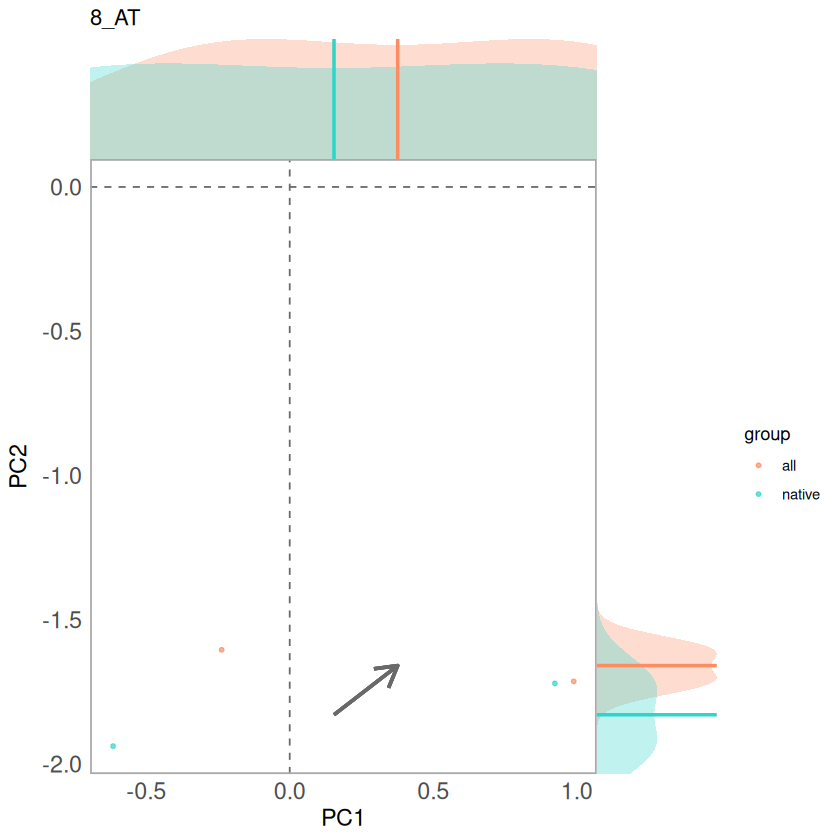

Warning message in geom_segment(aes(x = centroid_native$PC1, y = centroid_native$PC2, :
“All aesthetics have length 1, but the data has 336 rows.
ℹ Please consider using `annotate()` or provide this layer with data containing
  a single row.”
Warning message in geom_segment(aes(x = centroid_native$PC1, y = centroid_native$PC2, :
“All aesthetics have length 1, but the data has 336 rows.
ℹ Please consider using `annotate()` or provide this layer with data containing
  a single row.”
Warning message in geom_segment(aes(x = centroid_native$PC1, y = centroid_native$PC2, :
“All aesthetics have length 1, but the data has 336 rows.
ℹ Please consider using `annotate()` or provide this layer with data containing
  a single row.”


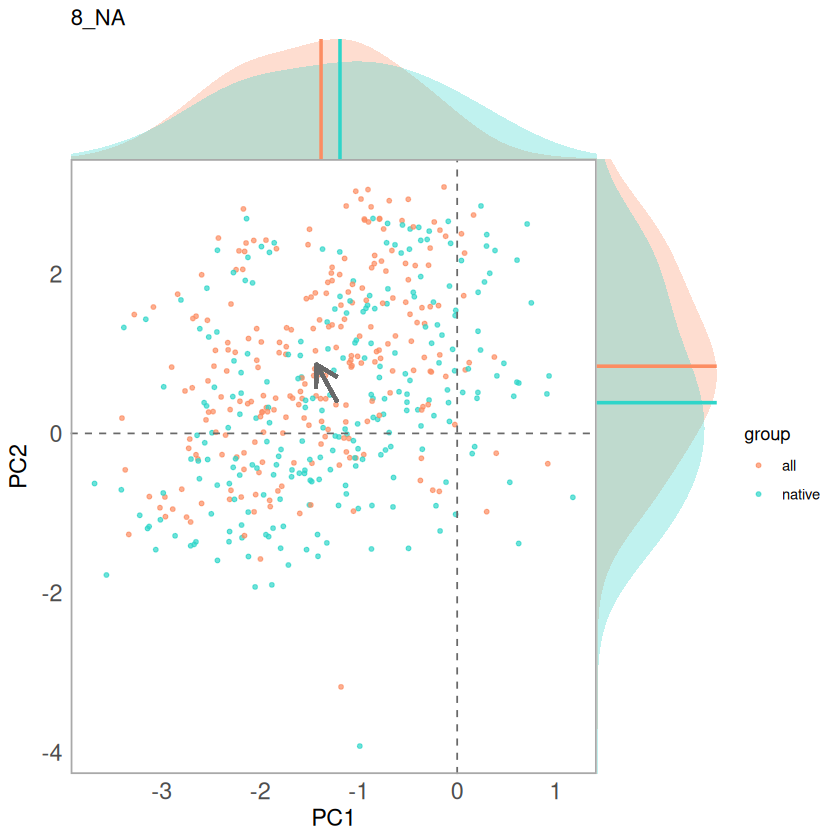

polygon has holes

polygon has holes

polygon has holes

polygon has holes

Warning message in geom_segment(aes(x = centroid_native$PC1, y = centroid_native$PC2, :
“All aesthetics have length 1, but the data has 726 rows.
ℹ Please consider using `annotate()` or provide this layer with data containing
  a single row.”
Warning message in geom_segment(aes(x = centroid_native$PC1, y = centroid_native$PC2, :
“All aesthetics have length 1, but the data has 726 rows.
ℹ Please consider using `annotate()` or provide this layer with data containing
  a single row.”
Warning message in geom_segment(aes(x = centroid_native$PC1, y = centroid_native$PC2, :
“All aesthetics have length 1, but the data has 726 rows.
ℹ Please consider using `annotate()` or provide this layer with data containing
  a single row.”


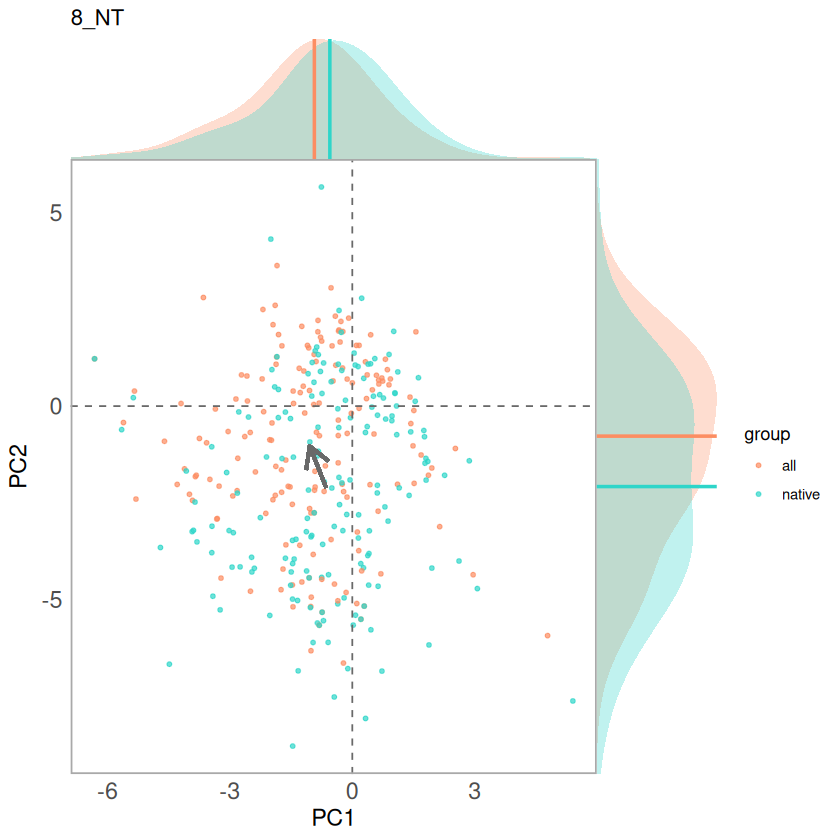

polygon has holes

Warning message in geom_segment(aes(x = centroid_native$PC1, y = centroid_native$PC2, :
“All aesthetics have length 1, but the data has 36 rows.
ℹ Please consider using `annotate()` or provide this layer with data containing
  a single row.”
Warning message in geom_segment(aes(x = centroid_native$PC1, y = centroid_native$PC2, :
“All aesthetics have length 1, but the data has 36 rows.
ℹ Please consider using `annotate()` or provide this layer with data containing
  a single row.”
Warning message in geom_segment(aes(x = centroid_native$PC1, y = centroid_native$PC2, :
“All aesthetics have length 1, but the data has 36 rows.
ℹ Please consider using `annotate()` or provide this layer with data containing
  a single row.”


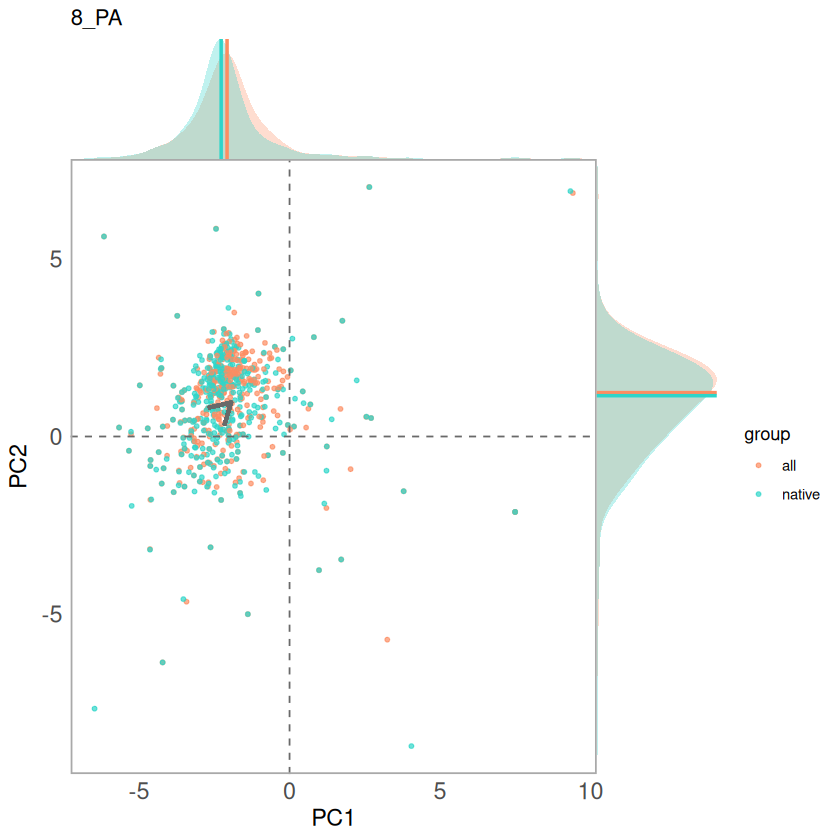

Warning message in geom_segment(aes(x = centroid_native$PC1, y = centroid_native$PC2, :
“All aesthetics have length 1, but the data has 8 rows.
ℹ Please consider using `annotate()` or provide this layer with data containing
  a single row.”
Warning message in geom_segment(aes(x = centroid_native$PC1, y = centroid_native$PC2, :
“All aesthetics have length 1, but the data has 8 rows.
ℹ Please consider using `annotate()` or provide this layer with data containing
  a single row.”
Warning message in geom_segment(aes(x = centroid_native$PC1, y = centroid_native$PC2, :
“All aesthetics have length 1, but the data has 8 rows.
ℹ Please consider using `annotate()` or provide this layer with data containing
  a single row.”


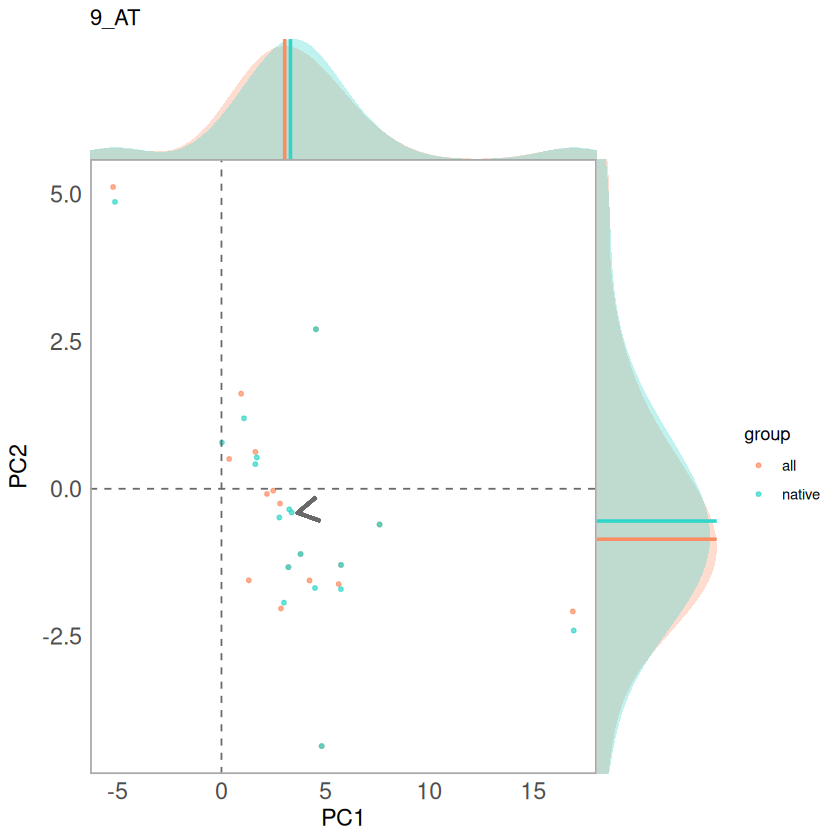

polygon has holes

polygon has holes

Warning message in geom_segment(aes(x = centroid_native$PC1, y = centroid_native$PC2, :
“All aesthetics have length 1, but the data has 42 rows.
ℹ Please consider using `annotate()` or provide this layer with data containing
  a single row.”
Warning message in geom_segment(aes(x = centroid_native$PC1, y = centroid_native$PC2, :
“All aesthetics have length 1, but the data has 42 rows.
ℹ Please consider using `annotate()` or provide this layer with data containing
  a single row.”
Warning message in geom_segment(aes(x = centroid_native$PC1, y = centroid_native$PC2, :
“All aesthetics have length 1, but the data has 42 rows.
ℹ Please consider using `annotate()` or provide this layer with data containing
  a single row.”


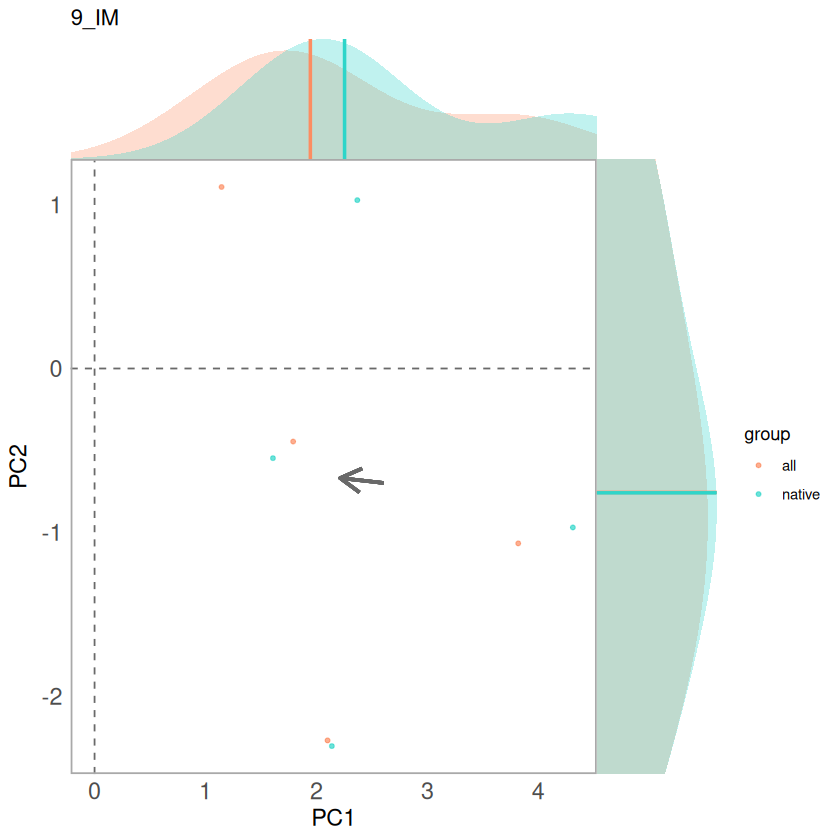

Warning message in geom_segment(aes(x = centroid_native$PC1, y = centroid_native$PC2, :
“All aesthetics have length 1, but the data has 58 rows.
ℹ Please consider using `annotate()` or provide this layer with data containing
  a single row.”
Warning message in geom_segment(aes(x = centroid_native$PC1, y = centroid_native$PC2, :
“All aesthetics have length 1, but the data has 58 rows.
ℹ Please consider using `annotate()` or provide this layer with data containing
  a single row.”
Warning message in geom_segment(aes(x = centroid_native$PC1, y = centroid_native$PC2, :
“All aesthetics have length 1, but the data has 58 rows.
ℹ Please consider using `annotate()` or provide this layer with data containing
  a single row.”


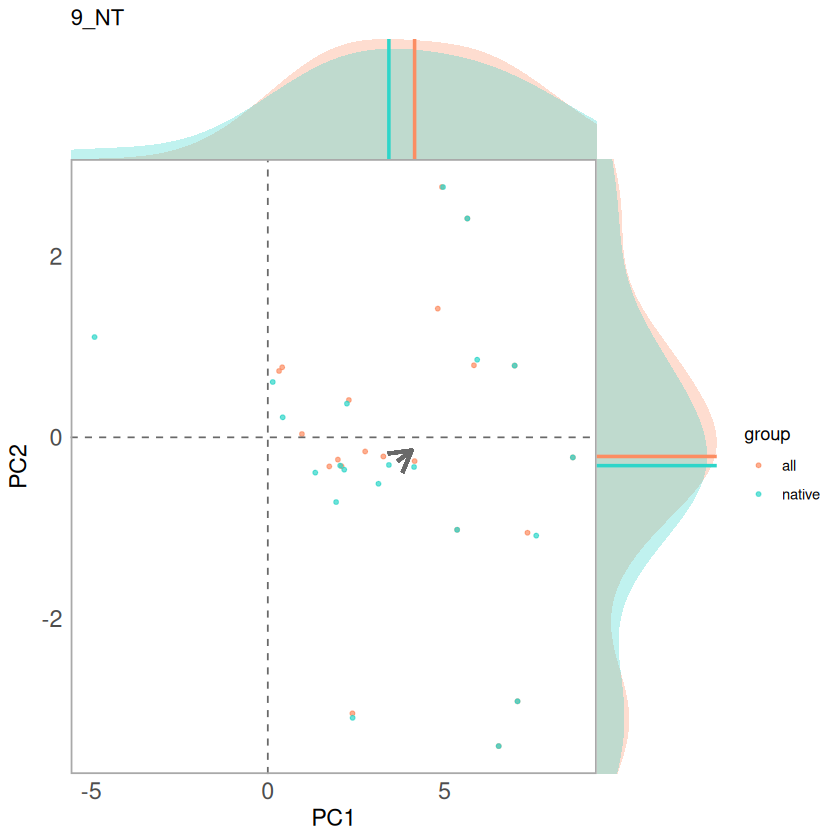

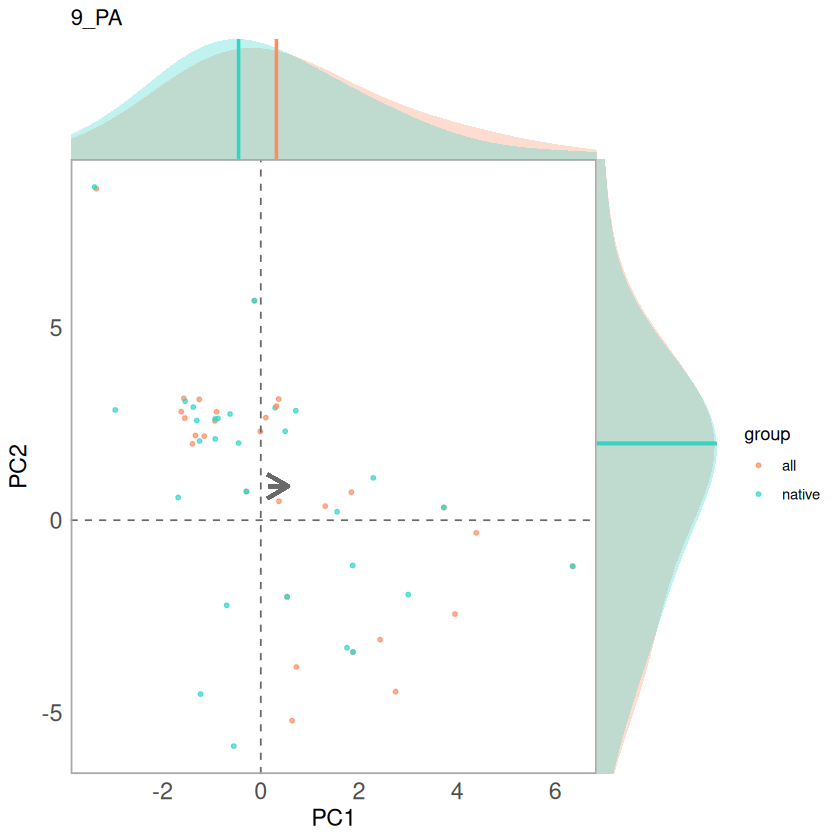

In [33]:
#regions <- merged_regions

for (i in regions) {
  f <- wwf_aggregated[wwf_aggregated$bim_rlm == i, ]
  region_cells <- h3::polyfill(f, res = 3)
  filtered_data <- combined_data %>%
  filter(h3_res3 %in% region_cells)
  sub_plot <- perform_analysis_points(filtered_data, f)
  
  #pdf(file = paste0("~/Func_Neo_Phytes/Results/Figures/pca_", i, "_densities_biplot_wcvp_Olsen.pdf"),
  png(file = paste0("~/Func_Neo_Phytes/Results/Figures/pca_", i, "_biplot_CS_log10_missTree_points.png"),
      width = 10, height = 7, units = "in", res = 300)
  print(sub_plot)
  dev.off()
  
  print(sub_plot)
  
}

# Biomes in trait space

In [34]:
library(MASS)
library(dplyr)
library(ggplot2)
library(purrr)

get_50_contour <- function(df, region_name) {

  df <- df %>%
    filter(
      is.finite(PC1),
      is.finite(PC2)
    )

  if (nrow(df) < 10) return(NULL)

  kd <- MASS::kde2d(
    df$PC1,
    df$PC2,
    n = 100
  )

  # Density threshold containing 50% of probability mass
  dx <- diff(kd$x[1:2])
  dy <- diff(kd$y[1:2])

  z <- kd$z
  z_sorted <- sort(as.vector(z), decreasing = TRUE)

  cumulative <- cumsum(z_sorted * dx * dy)
  cumulative <- cumulative / max(cumulative)

  threshold <- z_sorted[
    which(cumulative >= 0.50)[1]
  ]

  contour_lines <- contourLines(
    kd$x,
    kd$y,
    kd$z,
    levels = threshold
  )

  if (length(contour_lines) == 0) return(NULL)

  map_dfr(contour_lines, ~ tibble(
    PC1 = .x$x,
    PC2 = .x$y,
    region = region_name
  ))
}


Attaching package: ‘purrr’


The following object is masked from ‘package:h3’:

    compact


The following object is masked from ‘package:data.table’:

    transpose




In [35]:
contours_50 <- combined_data %>% filter(group == "native") %>%
  filter(!is.na(region)) %>%
  group_split(region) %>%
  map_dfr(~ get_50_contour(.x, unique(.x$region)))

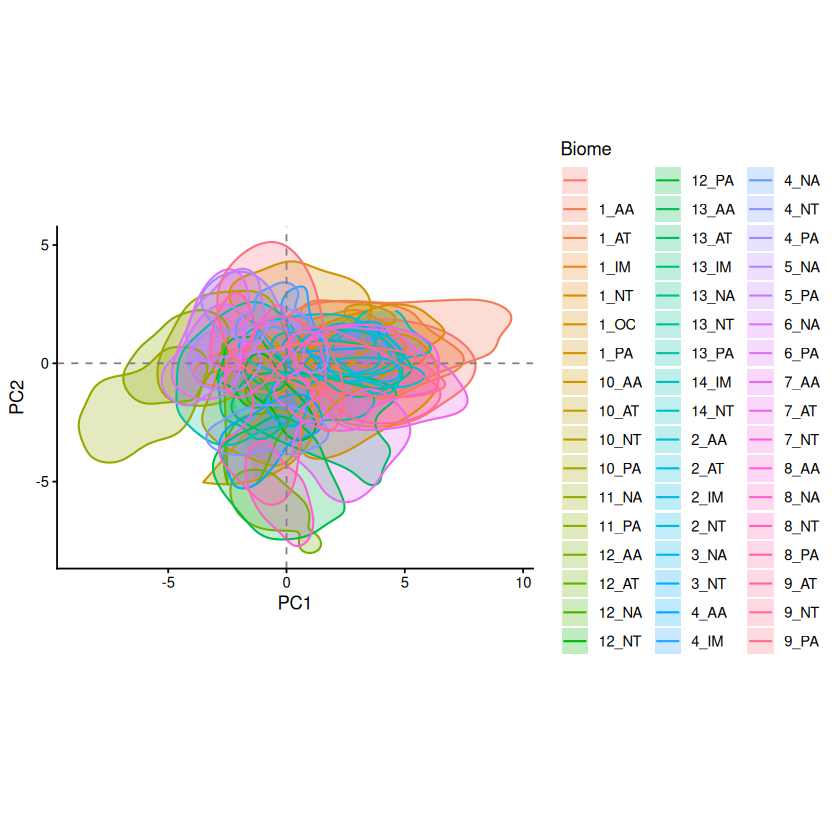

In [36]:
ggplot() +
  geom_polygon(
    data = contours_50,
    aes(
      x = PC1,
      y = PC2,
      group = region,
      fill = region
    ),
    alpha = 0.25,
    color = NA
  ) +
  geom_path(
    data = contours_50,
    aes(
      x = PC1,
      y = PC2,
      group = region,
      color = region
    ),
    linewidth = 0.6
  ) +
  geom_hline(
    yintercept = 0,
    linetype = "dashed",
    color = "grey50"
  ) +
  geom_vline(
    xintercept = 0,
    linetype = "dashed",
    color = "grey50"
  ) +
  coord_equal() +
  theme_classic() +
  labs(
    x = "PC1",
    y = "PC2",
    fill = "Biome",
    color = "Biome"
  )

In [37]:
library(plotly)

p <- ggplot(
  contours_50,
  aes(
    x = PC1,
    y = PC2,
    group = region,
    fill = region,
    text = region
  )
) +
  geom_polygon(
    alpha = 0.25,
    color = "white",
    linewidth = 0.2
  ) +
  geom_hline(
    yintercept = 0,
    linetype = "dashed",
    color = "grey50"
  ) +
  geom_vline(
    xintercept = 0,
    linetype = "dashed",
    color = "grey50"
  ) +
  coord_equal() +
  theme_classic() +
  labs(
    x = "PC1",
    y = "PC2",
    fill = "Biome × realm"
  )

ggplotly(p, tooltip = "text")

HTML widgets cannot be represented in plain text (need html)